In [1]:
# ============================================================
# CELL 1 — BIGBIRD + RAW / MINIMAL CLEANING EXPERIMENT SETUP
# ============================================================

import os
import re
import gc
import json
import random
import warnings

import numpy as np
import pandas as pd
import torch

warnings.filterwarnings("ignore")


# ------------------------------------------------------------
# REPRODUCIBILITY
# ------------------------------------------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


# ------------------------------------------------------------
# DEVICE
# ------------------------------------------------------------

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print("=" * 60)
print("BIGBIRD + RAW / MINIMAL CLEANING EXPERIMENT")
print("=" * 60)

print()
print("Device:", device)

if torch.cuda.is_available():

    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

    print(
        "CUDA:",
        torch.version.cuda
    )


# ------------------------------------------------------------
# EXPERIMENT IDENTITY
# ------------------------------------------------------------

EXPERIMENT_NAME = (
    "BigBird + RAW / MINIMAL CLEANING"
)

CLEANING_METHOD = (
    "Raw text after diagnostic anchor removal"
)

print()
print("Cleaning condition:")
print(CLEANING_METHOD)


# ------------------------------------------------------------
# MODEL
# ------------------------------------------------------------

MODEL_NAME = (
    "google/bigbird-roberta-base"
)

MAX_LENGTH = 512

print()
print("Model:", MODEL_NAME)
print("Context length:", MAX_LENGTH)


# ------------------------------------------------------------
# RESULT DIRECTORIES
# ------------------------------------------------------------

RAW_RESULT_DIR = (
    "/kaggle/working/"
    "bigbird_raw_results"
)

RAW_CHECKPOINT_DIR = (
    "/kaggle/working/"
    "bigbird_raw_checkpoints"
)

RAW_BACKUP_DIR = (
    "/kaggle/working/"
    "BIGBIRD_RAW_FINAL_BACKUP"
)

os.makedirs(
    RAW_RESULT_DIR,
    exist_ok=True
)

os.makedirs(
    RAW_CHECKPOINT_DIR,
    exist_ok=True
)

os.makedirs(
    RAW_BACKUP_DIR,
    exist_ok=True
)


# ------------------------------------------------------------
# EXPERIMENT CONFIG
# ------------------------------------------------------------

RAW_CONFIG = {

    "experiment":
        "BigBird + RAW",

    "model":
        "BigBird",

    "checkpoint":
        MODEL_NAME,

    "cleaning_method":
        CLEANING_METHOD,

    "seed":
        SEED,

    "device":
        str(device),

    "context_length":
        MAX_LENGTH,

    "fixed_controls": [

        "Exact user-level split",

        "Diagnostic anchor detection",

        "Diagnostic anchor removal",

        "D2 preservation",

        "53 metadata features",

        "Train-only StandardScaler",

        "Train-only random undersampling",

        "Model-specific tokenization",

        "Held-out test evaluation"
    ],

    "variable":
        "Model architecture only"
}

with open(
    os.path.join(
        RAW_RESULT_DIR,
        "bigbird_raw_experiment_config.json"
    ),
    "w"
) as f:

    json.dump(
        RAW_CONFIG,
        f,
        indent=2
    )


# ------------------------------------------------------------
# FINAL STATUS
# ------------------------------------------------------------

print()
print("=" * 60)
print("CELL 1 COMPLETE")
print("=" * 60)

print("✓ BigBird + RAW experiment initialized")
print("✓ Random seed = 42")
print("✓ GPU configured")
print("✓ BigBird checkpoint selected")
print("✓ Context length = 512")
print("✓ RAW condition locked")
print("✓ Diagnostic anchor removal retained")
print("✓ No additional text cleaning")
print("✓ Result directory created")
print("✓ Checkpoint directory created")
print("✓ Backup directory created")
print("✓ 53 metadata features retained")

BIGBIRD + RAW / MINIMAL CLEANING EXPERIMENT

Device: cuda
GPU: Tesla T4
CUDA: 12.8

Cleaning condition:
Raw text after diagnostic anchor removal

Model: google/bigbird-roberta-base
Context length: 512

CELL 1 COMPLETE
✓ BigBird + RAW experiment initialized
✓ Random seed = 42
✓ GPU configured
✓ BigBird checkpoint selected
✓ Context length = 512
✓ RAW condition locked
✓ Diagnostic anchor removal retained
✓ No additional text cleaning
✓ Result directory created
✓ Checkpoint directory created
✓ Backup directory created
✓ 53 metadata features retained


In [2]:
# ============================================================
# CELL 2 — LOAD EXACT USER-LEVEL SPLIT
# SAME SPLIT AS E2 / E3 / E4
# ============================================================

print("=" * 60)
print("BIGBIRD + RAW — LOADING EXACT USER-LEVEL SPLIT")
print("=" * 60)


# ------------------------------------------------------------
# SPLIT FILES
# ------------------------------------------------------------

SPLIT_ROOT = (
    "/kaggle/input/datasets/"
    "vedantnawghare35/"
    "mddl-experiment-1-splits"
)

TRAIN_PATH = os.path.join(
    SPLIT_ROOT,
    "MDDL_train_raw.pkl"
)

VAL_PATH = os.path.join(
    SPLIT_ROOT,
    "MDDL_val_raw.pkl"
)

TEST_PATH = os.path.join(
    SPLIT_ROOT,
    "MDDL_test_raw.pkl"
)


print()
print("TRAIN:", TRAIN_PATH)
print("VAL:  ", VAL_PATH)
print("TEST: ", TEST_PATH)


# ------------------------------------------------------------
# FILE CHECK
# ------------------------------------------------------------

for path in [
    TRAIN_PATH,
    VAL_PATH,
    TEST_PATH
]:

    assert os.path.exists(
        path
    ), (
        f"Missing split file:\n{path}"
    )

print()
print("✓ All split files found")


# ------------------------------------------------------------
# LOAD
# ------------------------------------------------------------

print()
print("Loading TRAIN...")

train_df = pd.read_pickle(
    TRAIN_PATH
)

print("Loading VALIDATION...")

val_df = pd.read_pickle(
    VAL_PATH
)

print("Loading TEST...")

test_df = pd.read_pickle(
    TEST_PATH
)


# ------------------------------------------------------------
# SHAPES
# ------------------------------------------------------------

print()
print("=" * 60)
print("SPLIT SHAPES")
print("=" * 60)

print(
    "Train:",
    train_df.shape
)

print(
    "Validation:",
    val_df.shape
)

print(
    "Test:",
    test_df.shape
)

assert len(train_df) == 6135
assert len(val_df) == 767
assert len(test_df) == 767


# ------------------------------------------------------------
# REQUIRED COLUMNS
# ------------------------------------------------------------

print()
print("=" * 60)
print("REQUIRED COLUMN CHECK")
print("=" * 60)

required_columns = [
    "user_id",
    "username",
    "label",
    "timeline_text"
]

for column in required_columns:

    assert column in train_df.columns
    assert column in val_df.columns
    assert column in test_df.columns

    print(
        f"✓ {column}"
    )


# ------------------------------------------------------------
# USER-LEVEL INTEGRITY
# ------------------------------------------------------------

print()
print("=" * 60)
print("USER-LEVEL INTEGRITY")
print("=" * 60)

train_users = set(
    train_df["user_id"]
)

val_users = set(
    val_df["user_id"]
)

test_users = set(
    test_df["user_id"]
)

print(
    "Train unique users:",
    train_df["user_id"].nunique()
)

print(
    "Validation unique users:",
    val_df["user_id"].nunique()
)

print(
    "Test unique users:",
    test_df["user_id"].nunique()
)

assert train_df["user_id"].is_unique
assert val_df["user_id"].is_unique
assert test_df["user_id"].is_unique


print(
    "TRAIN ↔ VAL:",
    len(
        train_users
        & val_users
    )
)

print(
    "TRAIN ↔ TEST:",
    len(
        train_users
        & test_users
    )
)

print(
    "VAL ↔ TEST:",
    len(
        val_users
        & test_users
    )
)

assert len(
    train_users
    & val_users
) == 0

assert len(
    train_users
    & test_users
) == 0

assert len(
    val_users
    & test_users
) == 0

print()
print("✓ No duplicate users")
print("✓ No cross-split overlap")


# ------------------------------------------------------------
# LABEL DISTRIBUTION
# ------------------------------------------------------------

print()
print("=" * 60)
print("LABEL DISTRIBUTION")
print("=" * 60)

print()
print("TRAIN:")

print(
    train_df[
        "label"
    ]
    .value_counts()
    .sort_index()
)

print()
print("VALIDATION:")

print(
    val_df[
        "label"
    ]
    .value_counts()
    .sort_index()
)

print()
print("TEST:")

print(
    test_df[
        "label"
    ]
    .value_counts()
    .sort_index()
)


assert (
    train_df["label"]
    .value_counts()
    .sort_index()
    .to_dict()
    == {
        0: 4122,
        1: 2013
    }
)

assert (
    val_df["label"]
    .value_counts()
    .sort_index()
    .to_dict()
    == {
        0: 515,
        1: 252
    }
)

assert (
    test_df["label"]
    .value_counts()
    .sort_index()
    .to_dict()
    == {
        0: 516,
        1: 251
    }
)


# ------------------------------------------------------------
# SAVE SPLIT SUMMARY
# ------------------------------------------------------------

split_summary = pd.DataFrame({

    "split": [
        "train",
        "validation",
        "test"
    ],

    "users": [
        len(train_df),
        len(val_df),
        len(test_df)
    ],

    "negative": [
        int(
            (train_df["label"] == 0).sum()
        ),
        int(
            (val_df["label"] == 0).sum()
        ),
        int(
            (test_df["label"] == 0).sum()
        )
    ],

    "positive": [
        int(
            (train_df["label"] == 1).sum()
        ),
        int(
            (val_df["label"] == 1).sum()
        ),
        int(
            (test_df["label"] == 1).sum()
        )
    ]
})

split_summary.to_csv(
    os.path.join(
        RAW_RESULT_DIR,
        "bigbird_raw_exact_split_summary.csv"
    ),
    index=False
)


# ------------------------------------------------------------
# FINAL
# ------------------------------------------------------------

print()
print("=" * 60)
print("CELL 2 COMPLETE")
print("=" * 60)

print("✓ Exact split loaded")
print("✓ TRAIN = 6135")
print("✓ VALIDATION = 767")
print("✓ TEST = 767")
print("✓ Same labels as E2/E3/E4")
print("✓ Same user IDs")
print("✓ No cross-split user overlap")
print("✓ Split summary saved")

BIGBIRD + RAW — LOADING EXACT USER-LEVEL SPLIT

TRAIN: /kaggle/input/datasets/vedantnawghare35/mddl-experiment-1-splits/MDDL_train_raw.pkl
VAL:   /kaggle/input/datasets/vedantnawghare35/mddl-experiment-1-splits/MDDL_val_raw.pkl
TEST:  /kaggle/input/datasets/vedantnawghare35/mddl-experiment-1-splits/MDDL_test_raw.pkl

✓ All split files found

Loading TRAIN...
Loading VALIDATION...
Loading TEST...

SPLIT SHAPES
Train: (6135, 82)
Validation: (767, 82)
Test: (767, 82)

REQUIRED COLUMN CHECK
✓ user_id
✓ username
✓ label
✓ timeline_text

USER-LEVEL INTEGRITY
Train unique users: 6135
Validation unique users: 767
Test unique users: 767
TRAIN ↔ VAL: 0
TRAIN ↔ TEST: 0
VAL ↔ TEST: 0

✓ No duplicate users
✓ No cross-split overlap

LABEL DISTRIBUTION

TRAIN:
label
0    4122
1    2013
Name: count, dtype: int64

VALIDATION:
label
0    515
1    252
Name: count, dtype: int64

TEST:
label
0    516
1    251
Name: count, dtype: int64

CELL 2 COMPLETE
✓ Exact split loaded
✓ TRAIN = 6135
✓ VALIDATION = 767


In [3]:
# ============================================================
# CELL 3 — EXACT D1 ANCHOR DETECTION
# SAME AS E2 / E3 / E4
# ============================================================

import os
import re
import json
import glob
from collections import defaultdict

print("=" * 60)
print("BIGBIRD + RAW — EXACT D1 ANCHOR DETECTION")
print("=" * 60)


# ------------------------------------------------------------
# ORIGINAL DATASET
# ------------------------------------------------------------

DATASET_ROOT = (
    "/kaggle/input/datasets/"
    "vedantnawghare35/"
    "depression-detection-mddl-final-pbl/"
    "Dataset_MDDL"
)

positive_timeline_dir = os.path.join(
    DATASET_ROOT,
    "labeled",
    "positive",
    "data",
    "timeline"
)

assert os.path.exists(
    positive_timeline_dir
)

positive_timeline_files = glob.glob(
    os.path.join(
        positive_timeline_dir,
        "*.json"
    )
)

print()
print(
    "D1 timeline files found:",
    len(positive_timeline_files)
)

assert len(
    positive_timeline_files
) == 2626


# ------------------------------------------------------------
# EXACT REFINED E3 DETECTOR
# ------------------------------------------------------------

REFINED_ANCHOR_PATTERNS = [

    r"\bi(?:'m| am)\s+diagnosed\s+with\s+(?:major\s+)?depression\b",

    r"\bi\s+(?:was|were)\s+diagnosed\s+with\s+(?:major\s+)?depression\b",

    r"\bi(?:'ve| have)\s+been\s+diagnosed\s+with\s+(?:major\s+)?depression\b",

    r"\bi(?:'m| am)\s+diagnosed\s+with\s+(?:major\s+)?depressive\s+disorder\b",

    r"\bi\s+(?:was|were)\s+diagnosed\s+with\s+(?:major\s+)?depressive\s+disorder\b",

    r"\bi(?:'ve| have)\s+been\s+diagnosed\s+with\s+(?:major\s+)?depressive\s+disorder\b",

    r"\bi\s+have\s+(?:major\s+)?depression\b",

    r"\bi\s+suffer\s+from\s+(?:major\s+)?depression\b",

    r"\bi\s+(?:was|am|'m)\s+diagnosed\b.{0,80}\bdepress",

    r"\b(?:my|a)\s+(?:doctor|psychiatrist)\s+(?:has\s+)?diagnosed\s+me\b.{0,80}\bdepress"
]

REFINED_COMPILED_PATTERNS = [
    re.compile(
        pattern,
        flags=re.IGNORECASE | re.DOTALL
    )
    for pattern in REFINED_ANCHOR_PATTERNS
]


# ------------------------------------------------------------
# EXCLUSIONS
# ------------------------------------------------------------

EXCLUSION_PATTERNS = [

    r"\bmy\s+friend\s+(?:was|is|has\s+been)\s+diagnosed",

    r"\bmy\s+sister\s+(?:was|is|has\s+been)\s+diagnosed",

    r"\bmy\s+brother\s+(?:was|is|has\s+been)\s+diagnosed",

    r"\bmy\s+mother\s+(?:was|is|has\s+been)\s+diagnosed",

    r"\bmy\s+father\s+(?:was|is|has\s+been)\s+diagnosed",

    r"\bmy\s+answer\s+to\s*:",

    r"\banswer\s+to\s*:",

    r"\bquestion\s*:",

    r"\bq\s*:"
]

COMPILED_EXCLUSION_PATTERNS = [
    re.compile(
        pattern,
        flags=re.IGNORECASE | re.DOTALL
    )
    for pattern in EXCLUSION_PATTERNS
]


def is_refined_anchor_tweet(text):

    if text is None:
        return False

    text = str(text).strip()

    if not text:
        return False

    for pattern in COMPILED_EXCLUSION_PATTERNS:

        if pattern.search(text):
            return False

    for pattern in REFINED_COMPILED_PATTERNS:

        if pattern.search(text):
            return True

    return False


# ------------------------------------------------------------
# POSITIVE USERS BY SPLIT
# ------------------------------------------------------------

train_positive_usernames = set(
    train_df.loc[
        train_df["label"] == 1,
        "username"
    ].astype(str)
)

val_positive_usernames = set(
    val_df.loc[
        val_df["label"] == 1,
        "username"
    ].astype(str)
)

test_positive_usernames = set(
    test_df.loc[
        test_df["label"] == 1,
        "username"
    ].astype(str)
)

all_positive_split_usernames = (
    train_positive_usernames
    | val_positive_usernames
    | test_positive_usernames
)

print()
print("=" * 60)
print("POSITIVE USERS BY SPLIT")
print("=" * 60)

print(
    "TRAIN:",
    len(train_positive_usernames)
)

print(
    "VALIDATION:",
    len(val_positive_usernames)
)

print(
    "TEST:",
    len(test_positive_usernames)
)

assert len(train_positive_usernames) == 2013
assert len(val_positive_usernames) == 252
assert len(test_positive_usernames) == 251
assert len(all_positive_split_usernames) == 2516


# ------------------------------------------------------------
# INDEX D1 TIMELINE FILES
# ------------------------------------------------------------

positive_files_by_user = defaultdict(list)

for timeline_file in positive_timeline_files:

    filename = os.path.basename(
        timeline_file
    )

    username = filename.split(
        "created_at"
    )[0]

    positive_files_by_user[
        username
    ].append(
        timeline_file
    )

assert len(
    positive_files_by_user
) == 2516


# ------------------------------------------------------------
# EXACT SCAN
# ------------------------------------------------------------

split_anchor_records = []

users_processed = set()
tweets_scanned = 0

for username in sorted(
    all_positive_split_usernames
):

    if username not in positive_files_by_user:

        raise KeyError(
            f"Missing timeline for user: {username}"
        )

    users_processed.add(
        username
    )

    for timeline_file in (
        positive_files_by_user[username]
    ):

        with open(
            timeline_file,
            "r",
            encoding="utf-8"
        ) as f:

            for line in f:

                line = line.strip()

                if not line:
                    continue

                record = json.loads(
                    line
                )

                tweets_scanned += 1

                tweet_id = record.get(
                    "id_str",
                    record.get(
                        "id",
                        ""
                    )
                )

                tweet_text = record.get(
                    "text",
                    ""
                )

                if (
                    tweet_id
                    and
                    is_refined_anchor_tweet(
                        tweet_text
                    )
                ):

                    split_anchor_records.append(
                        {
                            "username":
                                username,

                            "tweet_id":
                                str(tweet_id),

                            "created_at":
                                record.get(
                                    "created_at"
                                ),

                            "text":
                                str(tweet_text)
                        }
                    )


# ------------------------------------------------------------
# UNIQUE ANCHORS
# ------------------------------------------------------------

exact_anchor_pairs = {
    (
        record["username"],
        record["tweet_id"]
    )
    for record in split_anchor_records
}


# ------------------------------------------------------------
# SPLIT ANCHORS
# ------------------------------------------------------------

train_anchor_pairs = {
    pair
    for pair in exact_anchor_pairs
    if pair[0] in train_positive_usernames
}

val_anchor_pairs = {
    pair
    for pair in exact_anchor_pairs
    if pair[0] in val_positive_usernames
}

test_anchor_pairs = {
    pair
    for pair in exact_anchor_pairs
    if pair[0] in test_positive_usernames
}


# ------------------------------------------------------------
# SUMMARY
# ------------------------------------------------------------

print()
print("=" * 60)
print("EXACT ANCHOR SUMMARY")
print("=" * 60)

print(
    "Positive users processed:",
    len(users_processed)
)

print(
    "Tweets scanned:",
    tweets_scanned
)

print(
    "Raw anchor records:",
    len(split_anchor_records)
)

print(
    "Unique anchor pairs:",
    len(exact_anchor_pairs)
)

print()
print(
    "TRAIN unique anchors:",
    len(train_anchor_pairs)
)

print(
    "VAL unique anchors:",
    len(val_anchor_pairs)
)

print(
    "TEST unique anchors:",
    len(test_anchor_pairs)
)


# ------------------------------------------------------------
# EXACT E3/E4 CONTROL
# ------------------------------------------------------------

assert len(users_processed) == 2516

assert len(
    split_anchor_records
) == 1920

assert len(
    exact_anchor_pairs
) == 1847

assert len(
    train_anchor_pairs
) == 1476

assert len(
    val_anchor_pairs
) == 190

assert len(
    test_anchor_pairs
) == 181


# ------------------------------------------------------------
# SAVE
# ------------------------------------------------------------

raw_anchor_df = pd.DataFrame(
    split_anchor_records
)

raw_anchor_df.to_csv(
    os.path.join(
        RAW_RESULT_DIR,
        "bigbird_raw_exact_anchor_records.csv"
    ),
    index=False
)


print()
print("=" * 60)
print("CELL 3 COMPLETE")
print("=" * 60)

print("✓ Exact E3/E4 anchor detector reproduced")
print("✓ 1,847 unique anchors confirmed")
print("✓ 1,920 anchor records confirmed")
print("✓ TRAIN = 1,476 unique anchors")
print("✓ VAL = 190 unique anchors")
print("✓ TEST = 181 unique anchors")
print("✓ No D2 users included")
print("✓ Anchor records saved")
print("✓ No timelines modified yet")

BIGBIRD + RAW — EXACT D1 ANCHOR DETECTION

D1 timeline files found: 2626

POSITIVE USERS BY SPLIT
TRAIN: 2013
VALIDATION: 252
TEST: 251

EXACT ANCHOR SUMMARY
Positive users processed: 2516
Tweets scanned: 508806
Raw anchor records: 1920
Unique anchor pairs: 1847

TRAIN unique anchors: 1476
VAL unique anchors: 190
TEST unique anchors: 181

CELL 3 COMPLETE
✓ Exact E3/E4 anchor detector reproduced
✓ 1,847 unique anchors confirmed
✓ 1,920 anchor records confirmed
✓ TRAIN = 1,476 unique anchors
✓ VAL = 190 unique anchors
✓ TEST = 181 unique anchors
✓ No D2 users included
✓ Anchor records saved
✓ No timelines modified yet


In [4]:
# ============================================================
# CELL 4 — BIGBIRD + RAW ANCHOR REMOVAL
# SAME AS E2 / E3 / E4
# ============================================================

print("=" * 60)
print("BIGBIRD + RAW — EXACT D1 ANCHOR REMOVAL")
print("=" * 60)


# ------------------------------------------------------------
# EXPECTED COUNTS
# ------------------------------------------------------------

EXPECTED_TRAIN_REMOVED = 1535
EXPECTED_VAL_REMOVED   = 199
EXPECTED_TEST_REMOVED  = 186
EXPECTED_TOTAL_REMOVED = 1920


# ------------------------------------------------------------
# PRE-REMOVAL VERIFICATION
# ------------------------------------------------------------

print()
print("=" * 60)
print("PRE-REMOVAL ANCHOR VERIFICATION")
print("=" * 60)

duplicate_occurrences = (
    len(split_anchor_records)
    - len(exact_anchor_pairs)
)

print(
    "Raw anchor records:",
    len(split_anchor_records)
)

print(
    "Unique anchor pairs:",
    len(exact_anchor_pairs)
)

print(
    "Duplicate anchor occurrences:",
    duplicate_occurrences
)

assert len(split_anchor_records) == 1920
assert len(exact_anchor_pairs) == 1847
assert duplicate_occurrences == 73

print("✓ Anchor counts verified")


# ------------------------------------------------------------
# BUILD SPLIT-SPECIFIC RECORD LISTS
# ------------------------------------------------------------

train_anchor_records = [
    r
    for r in split_anchor_records
    if r["username"] in train_positive_usernames
]

val_anchor_records = [
    r
    for r in split_anchor_records
    if r["username"] in val_positive_usernames
]

test_anchor_records = [
    r
    for r in split_anchor_records
    if r["username"] in test_positive_usernames
]

print()
print("=" * 60)
print("SPLIT-LEVEL ANCHOR RECORD COUNTS")
print("=" * 60)

print(
    "TRAIN:",
    len(train_anchor_records),
    "| expected:",
    EXPECTED_TRAIN_REMOVED
)

print(
    "VAL:",
    len(val_anchor_records),
    "| expected:",
    EXPECTED_VAL_REMOVED
)

print(
    "TEST:",
    len(test_anchor_records),
    "| expected:",
    EXPECTED_TEST_REMOVED
)

assert len(train_anchor_records) == EXPECTED_TRAIN_REMOVED
assert len(val_anchor_records) == EXPECTED_VAL_REMOVED
assert len(test_anchor_records) == EXPECTED_TEST_REMOVED


# ------------------------------------------------------------
# INDEX ORIGINAL POSITIVE TIMELINE FILES
# ------------------------------------------------------------

positive_files_by_user = defaultdict(list)

for timeline_file in positive_timeline_files:

    filename = os.path.basename(
        timeline_file
    )

    username = filename.split(
        "created_at"
    )[0]

    positive_files_by_user[
        username
    ].append(
        timeline_file
    )

assert len(
    positive_files_by_user
) == 2516


# ------------------------------------------------------------
# EXACT ANCHOR SET
# ------------------------------------------------------------

EXACT_ANCHOR_SET = set(
    exact_anchor_pairs
)


# ------------------------------------------------------------
# BUILD ANCHOR-REMOVED TEXT
# ------------------------------------------------------------

def build_raw_anchor_removed_text(
    username
):

    kept_texts = []

    removed_count = 0
    original_count = 0

    for timeline_file in (
        positive_files_by_user[username]
    ):

        with open(
            timeline_file,
            "r",
            encoding="utf-8"
        ) as f:

            for line in f:

                line = line.strip()

                if not line:
                    continue

                record = json.loads(
                    line
                )

                original_count += 1

                tweet_id = str(
                    record.get(
                        "id_str",
                        record.get(
                            "id",
                            ""
                        )
                    )
                )

                pair = (
                    str(username),
                    tweet_id
                )

                if pair in EXACT_ANCHOR_SET:

                    removed_count += 1
                    continue

                text = str(
                    record.get(
                        "text",
                        ""
                    )
                ).strip()

                if text:

                    # IMPORTANT:
                    # RAW condition = NO additional cleaning.
                    # Preserve original tweet text exactly.
                    kept_texts.append(
                        text
                    )

    return (
        " ".join(kept_texts),
        original_count,
        removed_count
    )


# ------------------------------------------------------------
# COPY ORIGINAL SPLITS
# ------------------------------------------------------------

train_raw_df = train_df.copy(
    deep=True
)

val_raw_df = val_df.copy(
    deep=True
)

test_raw_df = test_df.copy(
    deep=True
)


# ------------------------------------------------------------
# PROCESS ALL D1 USERS
# ------------------------------------------------------------

positive_anchor_removed_raw = {}

train_removed = 0
val_removed = 0
test_removed = 0

for username in sorted(
    all_positive_split_usernames
):

    raw_text, _, removed_count = (
        build_raw_anchor_removed_text(
            username
        )
    )

    positive_anchor_removed_raw[
        username
    ] = raw_text

    if username in train_positive_usernames:

        train_removed += removed_count

    elif username in val_positive_usernames:

        val_removed += removed_count

    elif username in test_positive_usernames:

        test_removed += removed_count


# ------------------------------------------------------------
# VERIFY REMOVAL
# ------------------------------------------------------------

print()
print("=" * 60)
print("FINAL ANCHOR REMOVAL COUNTS")
print("=" * 60)

print(
    "TRAIN removed:",
    train_removed
)

print(
    "VAL removed:",
    val_removed
)

print(
    "TEST removed:",
    test_removed
)

print(
    "TOTAL removed:",
    train_removed
    + val_removed
    + test_removed
)

assert train_removed == EXPECTED_TRAIN_REMOVED
assert val_removed == EXPECTED_VAL_REMOVED
assert test_removed == EXPECTED_TEST_REMOVED

assert (
    train_removed
    + val_removed
    + test_removed
    == EXPECTED_TOTAL_REMOVED
)

print()
print("✓ Record-level removal exactly matches E2/E3/E4")


# ------------------------------------------------------------
# UPDATE ONLY D1 TEXT
# ------------------------------------------------------------

for df in [
    train_raw_df,
    val_raw_df,
    test_raw_df
]:

    positive_mask = (
        df["label"] == 1
    )

    df.loc[
        positive_mask,
        "timeline_text"
    ] = (
        df.loc[
            positive_mask,
            "username"
        ]
        .astype(str)
        .map(
            positive_anchor_removed_raw
        )
        .fillna("")
        .values
    )


# ------------------------------------------------------------
# RAW TEXT = NO ADDITIONAL CLEANING
# ------------------------------------------------------------

train_raw_df["model_text"] = (
    train_raw_df["timeline_text"]
    .fillna("")
    .astype(str)
)

val_raw_df["model_text"] = (
    val_raw_df["timeline_text"]
    .fillna("")
    .astype(str)
)

test_raw_df["model_text"] = (
    test_raw_df["timeline_text"]
    .fillna("")
    .astype(str)
)


# ------------------------------------------------------------
# D2 PRESERVATION
# ------------------------------------------------------------

print()
print("=" * 60)
print("D2 PRESERVATION CHECK")
print("=" * 60)

for original, result, name in [

    (
        train_df,
        train_raw_df,
        "TRAIN"
    ),

    (
        val_df,
        val_raw_df,
        "VALIDATION"
    ),

    (
        test_df,
        test_raw_df,
        "TEST"
    )

]:

    original_d2 = (
        original.loc[
            original["label"] == 0,
            ["username", "timeline_text"]
        ]
        .set_index("username")
        .sort_index()
    )

    result_d2 = (
        result.loc[
            result["label"] == 0,
            ["username", "timeline_text"]
        ]
        .set_index("username")
        .sort_index()
    )

    assert original_d2.equals(
        result_d2
    )

    print(
        f"✓ {name} D2 unchanged"
    )


# ------------------------------------------------------------
# USER + LABEL PRESERVATION
# ------------------------------------------------------------

print()
print("=" * 60)
print("USER + LABEL PRESERVATION")
print("=" * 60)

for original, result, name in [

    (train_df, train_raw_df, "TRAIN"),
    (val_df, val_raw_df, "VALIDATION"),
    (test_df, test_raw_df, "TEST")

]:

    assert list(
        original["user_id"]
    ) == list(
        result["user_id"]
    )

    assert list(
        original["username"]
    ) == list(
        result["username"]
    )

    assert list(
        original["label"]
    ) == list(
        result["label"]
    )

    print(
        f"✓ {name}: users and labels unchanged"
    )


# ------------------------------------------------------------
# EMPTY TEXT CHECK
# ------------------------------------------------------------

print()
print("=" * 60)
print("RAW TEXT INTEGRITY")
print("=" * 60)

for name, df in [

    ("TRAIN", train_raw_df),
    ("VALIDATION", val_raw_df),
    ("TEST", test_raw_df)

]:

    empty_count = int(
        (
            df["model_text"]
            .str.strip()
            == ""
        ).sum()
    )

    print(
        f"{name}: "
        f"empty model texts = "
        f"{empty_count}"
    )


# ------------------------------------------------------------
# REAL DATA PREVIEW
# ------------------------------------------------------------

print()
print("=" * 60)
print("RAW MODEL TEXT PREVIEW")
print("=" * 60)

for _, row in train_raw_df.head(5).iterrows():

    print()
    print(
        "User:",
        row["username"]
    )

    print(
        "Label:",
        row["label"]
    )

    print(
        "Raw anchor-removed text:"
    )

    print(
        row["model_text"][:1000]
    )


# ------------------------------------------------------------
# SAVE
# ------------------------------------------------------------

train_raw_df.to_pickle(
    os.path.join(
        RAW_RESULT_DIR,
        "bigbird_raw_train_anchor_removed.pkl"
    )
)

val_raw_df.to_pickle(
    os.path.join(
        RAW_RESULT_DIR,
        "bigbird_raw_val_anchor_removed.pkl"
    )
)

test_raw_df.to_pickle(
    os.path.join(
        RAW_RESULT_DIR,
        "bigbird_raw_test_anchor_removed.pkl"
    )
)


print()
print("=" * 60)
print("CELL 4 COMPLETE")
print("=" * 60)

print("✓ Same 1,920 anchor records removed")
print("✓ Same 1,847 unique anchors")
print("✓ D2 completely preserved")
print("✓ User IDs preserved")
print("✓ Labels preserved")
print("✓ NO additional text cleaning applied")
print("✓ BigBird RAW source saved")

BIGBIRD + RAW — EXACT D1 ANCHOR REMOVAL

PRE-REMOVAL ANCHOR VERIFICATION
Raw anchor records: 1920
Unique anchor pairs: 1847
Duplicate anchor occurrences: 73
✓ Anchor counts verified

SPLIT-LEVEL ANCHOR RECORD COUNTS
TRAIN: 1535 | expected: 1535
VAL: 199 | expected: 199
TEST: 186 | expected: 186

FINAL ANCHOR REMOVAL COUNTS
TRAIN removed: 1535
VAL removed: 199
TEST removed: 186
TOTAL removed: 1920

✓ Record-level removal exactly matches E2/E3/E4

D2 PRESERVATION CHECK
✓ TRAIN D2 unchanged
✓ VALIDATION D2 unchanged
✓ TEST D2 unchanged

USER + LABEL PRESERVATION
✓ TRAIN: users and labels unchanged
✓ VALIDATION: users and labels unchanged
✓ TEST: users and labels unchanged

RAW TEXT INTEGRITY
TRAIN: empty model texts = 29
VALIDATION: empty model texts = 4
TEST: empty model texts = 1

RAW MODEL TEXT PREVIEW

User: RompingFox
Label: 1
Raw anchor-removed text:
@cybershot_1 :( I'm making a wendy sound board for my cosplay so while in cosplay I will only make frightened flute noises. Rock of ag

In [6]:
# ============================================================
# CELL 5 — BIGBIRD + RAW TOKEN-LENGTH ANALYSIS
# SAME RAW METHODOLOGY AS REFERENCE NOTEBOOK
# ============================================================

import os
import numpy as np
import pandas as pd

print("=" * 60)
print("BIGBIRD + RAW — TOKEN LENGTH ANALYSIS")
print("=" * 60)


# ------------------------------------------------------------
# TOKENIZER
# ------------------------------------------------------------

from transformers import AutoTokenizer

MODEL_NAME_RAW = "google/bigbird-roberta-base"

raw_tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME_RAW
)

print()
print("Tokenizer:", MODEL_NAME_RAW)


# ------------------------------------------------------------
# FUNCTION
# ------------------------------------------------------------

def calculate_raw_token_lengths(
    texts,
    split_name
):

    print()
    print(
        f"Processing {split_name}..."
    )

    lengths = []

    for idx, text in enumerate(texts):

        encoded = raw_tokenizer(
            str(text),
            add_special_tokens=True,
            truncation=False,
            padding=False
        )

        lengths.append(
            len(encoded["input_ids"])
        )

        if (
            (idx + 1) % 1000 == 0
            or idx + 1 == len(texts)
        ):

            print(
                f"{split_name}: "
                f"{idx + 1}/{len(texts)}"
            )

    return np.asarray(
        lengths,
        dtype=np.int64
    )


# ------------------------------------------------------------
# CALCULATE
# ------------------------------------------------------------

train_raw_token_lengths = (
    calculate_raw_token_lengths(
        train_raw_df["model_text"].tolist(),
        "TRAIN"
    )
)

val_raw_token_lengths = (
    calculate_raw_token_lengths(
        val_raw_df["model_text"].tolist(),
        "VALIDATION"
    )
)

test_raw_token_lengths = (
    calculate_raw_token_lengths(
        test_raw_df["model_text"].tolist(),
        "TEST"
    )
)


# ------------------------------------------------------------
# STATISTICS
# ------------------------------------------------------------

def print_raw_statistics(
    lengths,
    split_name
):

    print()
    print("=" * 60)
    print(
        f"{split_name} TOKEN STATISTICS"
    )
    print("=" * 60)

    print(
        "Minimum:",
        int(lengths.min())
    )

    print(
        "Maximum:",
        int(lengths.max())
    )

    print(
        "Mean:",
        round(
            float(lengths.mean()),
            2
        )
    )

    print(
        "Median:",
        int(np.median(lengths))
    )

    print(
        "25th percentile:",
        int(np.percentile(lengths, 25))
    )

    print(
        "75th percentile:",
        int(np.percentile(lengths, 75))
    )

    print(
        "90th percentile:",
        int(np.percentile(lengths, 90))
    )

    print(
        "95th percentile:",
        int(np.percentile(lengths, 95))
    )

    print(
        "99th percentile:",
        int(np.percentile(lengths, 99))
    )

    within_512 = int(
        np.sum(lengths <= 512)
    )

    within_4096 = int(
        np.sum(lengths <= 4096)
    )

    above_512 = int(
        np.sum(lengths > 512)
    )

    above_4096 = int(
        np.sum(lengths > 4096)
    )

    print()
    print("CONTEXT COVERAGE")

    print(
        "Users <= 512:",
        within_512
    )

    print(
        "Percentage <= 512:",
        round(
            100 * within_512 / len(lengths),
            2
        ),
        "%"
    )

    print(
        "Users <= 4096:",
        within_4096
    )

    print(
        "Percentage <= 4096:",
        round(
            100 * within_4096 / len(lengths),
            2
        ),
        "%"
    )

    print(
        "Users > 512:",
        above_512
    )

    print(
        "Users > 4096:",
        above_4096
    )


print_raw_statistics(
    train_raw_token_lengths,
    "TRAIN"
)

print_raw_statistics(
    val_raw_token_lengths,
    "VALIDATION"
)

print_raw_statistics(
    test_raw_token_lengths,
    "TEST"
)


# ------------------------------------------------------------
# CHUNK ESTIMATES
# ------------------------------------------------------------

print()
print("=" * 60)
print("ESTIMATED CONTEXT CHUNKS")
print("=" * 60)

for context_length in [
    512,
    4096
]:

    print()
    print(
        "Context length:",
        context_length
    )

    train_chunks = np.ceil(
        train_raw_token_lengths
        / context_length
    )

    val_chunks = np.ceil(
        val_raw_token_lengths
        / context_length
    )

    test_chunks = np.ceil(
        test_raw_token_lengths
        / context_length
    )

    print(
        "TRAIN mean chunks:",
        round(
            float(train_chunks.mean()),
            2
        )
    )

    print(
        "TRAIN maximum chunks:",
        int(train_chunks.max())
    )

    print(
        "VALIDATION mean chunks:",
        round(
            float(val_chunks.mean()),
            2
        )
    )

    print(
        "VALIDATION maximum chunks:",
        int(val_chunks.max())
    )

    print(
        "TEST mean chunks:",
        round(
            float(test_chunks.mean()),
            2
        )
    )

    print(
        "TEST maximum chunks:",
        int(test_chunks.max())
    )


# ------------------------------------------------------------
# SAVE
# ------------------------------------------------------------

pd.DataFrame({
    "token_length":
        train_raw_token_lengths
}).to_csv(
    os.path.join(
        RAW_RESULT_DIR,
        "bigbird_raw_train_token_lengths.csv"
    ),
    index=False
)

pd.DataFrame({
    "token_length":
        val_raw_token_lengths
}).to_csv(
    os.path.join(
        RAW_RESULT_DIR,
        "bigbird_raw_val_token_lengths.csv"
    ),
    index=False
)

pd.DataFrame({
    "token_length":
        test_raw_token_lengths
}).to_csv(
    os.path.join(
        RAW_RESULT_DIR,
        "bigbird_raw_test_token_lengths.csv"
    ),
    index=False
)


print()
print("=" * 60)
print("CELL 5 COMPLETE")
print("=" * 60)

print("✓ BigBird raw token lengths calculated")
print("✓ 512-token coverage measured")
print("✓ 4096-token coverage measured")
print("✓ Context chunk estimates calculated")
print("✓ Token-length files saved")

BIGBIRD + RAW — TOKEN LENGTH ANALYSIS


config.json:   0%|          | 0.00/760 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

spiece.model:   0%|          | 0.00/846k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/775 [00:00<?, ?B/s]

Token indices sequence length is longer than the specified maximum sequence length for this model (7436 > 4096). Running this sequence through the model will result in indexing errors



Tokenizer: google/bigbird-roberta-base

Processing TRAIN...
TRAIN: 1000/6135
TRAIN: 2000/6135
TRAIN: 3000/6135
TRAIN: 4000/6135
TRAIN: 5000/6135
TRAIN: 6000/6135
TRAIN: 6135/6135

Processing VALIDATION...
VALIDATION: 767/767

Processing TEST...
TEST: 767/767

TRAIN TOKEN STATISTICS
Minimum: 2
Maximum: 160061
Mean: 14289.8
Median: 5408
25th percentile: 1609
75th percentile: 16772
90th percentile: 44067
95th percentile: 64104
99th percentile: 92508

CONTEXT COVERAGE
Users <= 512: 668
Percentage <= 512: 10.89 %
Users <= 4096: 2709
Percentage <= 4096: 44.16 %
Users > 512: 5467
Users > 4096: 3426

VALIDATION TOKEN STATISTICS
Minimum: 2
Maximum: 134117
Mean: 14933.3
Median: 5284
25th percentile: 1577
75th percentile: 19061
90th percentile: 47884
95th percentile: 61944
99th percentile: 96009

CONTEXT COVERAGE
Users <= 512: 79
Percentage <= 512: 10.3 %
Users <= 4096: 343
Percentage <= 4096: 44.72 %
Users > 512: 688
Users > 4096: 424

TEST TOKEN STATISTICS
Minimum: 2
Maximum: 187407
Mean: 1531

In [7]:
# ============================================================
# CELL 6 — BIGBIRD + RAW METADATA EXTRACTION + NORMALIZATION
# SAME 53-FEATURE BLUEPRINT AS E2 / E3 / E4
# ============================================================

import os
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler

print("=" * 60)
print("BIGBIRD + RAW — METADATA EXTRACTION + NORMALIZATION")
print("=" * 60)


# ------------------------------------------------------------
# EXACT 53-FEATURE BLUEPRINT
# ------------------------------------------------------------

behavioral_features = [
    "posting_frequency",
    "follower_friend_ratio",
    "night_posting_ratio",
    "engagement",
    "followers_count",
    "friends_count",
    "statuses_count",
    "favourites_count"
]

linguistic_features = [
    "first_person_ratio",
    "negation_ratio",
    "uppercase_ratio",
    "punctuation_freq"
]

readability_features = [
    "flesch_reading_ease",
    "gunning_fog",
    "flesch_kincaid_grade"
]

emotional_features = [
    "sentiment_score",
    "emotion_score",
    "pos_emoji_count",
    "neg_emoji_count",
    "emoji_density",
    "exclamation_count"
]

psychological_features = [
    "depression_lexicon_score",
    "hopelessness_score",
    "loneliness_score",
    "anxiety_score",
    "sleep_words_ratio",
    "fatigue_words_ratio",
    "selfharm_keywords_ratio"
]

writing_style_features = [
    "avg_sentence_length",
    "lexical_diversity",
    "word_count",
    "avg_paragraph_length",
    "repeated_letters"
]

lda_features = [
    f"lda_topic_{i}"
    for i in range(1, 21)
]

raw_metadata_features = (
    behavioral_features
    + linguistic_features
    + readability_features
    + emotional_features
    + psychological_features
    + writing_style_features
    + lda_features
)

print()
print("Behavioral:", len(behavioral_features))
print("Linguistic:", len(linguistic_features))
print("Readability:", len(readability_features))
print("Emotional:", len(emotional_features))
print("Psychological:", len(psychological_features))
print("Writing Style:", len(writing_style_features))
print("LDA:", len(lda_features))

print()
print(
    "TOTAL METADATA FEATURES:",
    len(raw_metadata_features)
)

assert len(raw_metadata_features) == 53


# ------------------------------------------------------------
# EXTRACTION
# ------------------------------------------------------------

def extract_raw_metadata(
    df,
    split_name
):

    print()
    print(
        f"Extracting metadata — {split_name}"
    )

    extracted = []

    for feature in raw_metadata_features:

        matching_positions = [
            i
            for i, col in enumerate(df.columns)
            if col == feature
        ]

        if len(matching_positions) == 0:

            raise KeyError(
                f"Missing metadata feature: {feature}"
            )

        extracted.append(
            df.iloc[
                :,
                matching_positions[0]
            ].to_numpy()
        )

    metadata = np.column_stack(
        extracted
    ).astype(
        np.float32
    )

    print(
        f"{split_name} metadata:",
        metadata.shape
    )

    return metadata


# ------------------------------------------------------------
# TRAIN / VALIDATION / TEST
# ------------------------------------------------------------

train_raw_metadata = extract_raw_metadata(
    train_raw_df,
    "TRAIN"
)

val_raw_metadata = extract_raw_metadata(
    val_raw_df,
    "VALIDATION"
)

test_raw_metadata = extract_raw_metadata(
    test_raw_df,
    "TEST"
)


# ------------------------------------------------------------
# SHAPES
# ------------------------------------------------------------

print()
print("=" * 60)
print("METADATA SHAPES")
print("=" * 60)

print(
    "Train:",
    train_raw_metadata.shape
)

print(
    "Validation:",
    val_raw_metadata.shape
)

print(
    "Test:",
    test_raw_metadata.shape
)

assert train_raw_metadata.shape == (
    6135,
    53
)

assert val_raw_metadata.shape == (
    767,
    53
)

assert test_raw_metadata.shape == (
    767,
    53
)

print("✓ Exact 53 metadata features confirmed")


# ------------------------------------------------------------
# NUMERICAL INTEGRITY
# ------------------------------------------------------------

print()
print("=" * 60)
print("METADATA NUMERICAL INTEGRITY")
print("=" * 60)

for name, data in [

    ("TRAIN", train_raw_metadata),
    ("VALIDATION", val_raw_metadata),
    ("TEST", test_raw_metadata)

]:

    data64 = np.asarray(
        data,
        dtype=np.float64
    )

    nan_count = int(
        np.isnan(data64).sum()
    )

    inf_count = int(
        np.isinf(data64).sum()
    )

    print(
        f"{name}: "
        f"NaN={nan_count}, "
        f"Inf={inf_count}"
    )

    assert nan_count == 0
    assert inf_count == 0


# ------------------------------------------------------------
# TRAIN-ONLY STANDARD SCALER
# ------------------------------------------------------------

print()
print("=" * 60)
print("TRAIN-ONLY METADATA NORMALIZATION")
print("=" * 60)

raw_metadata_scaler = StandardScaler()

train_raw_metadata_scaled = (
    raw_metadata_scaler
    .fit_transform(
        train_raw_metadata
    )
    .astype(np.float32)
)

val_raw_metadata_scaled = (
    raw_metadata_scaler
    .transform(
        val_raw_metadata
    )
    .astype(np.float32)
)

test_raw_metadata_scaled = (
    raw_metadata_scaler
    .transform(
        test_raw_metadata
    )
    .astype(np.float32)
)


# ------------------------------------------------------------
# NORMALIZATION CHECK
# ------------------------------------------------------------

train_mean_abs = float(
    np.abs(
        train_raw_metadata_scaled.mean(
            axis=0
        )
    ).mean()
)

train_std_mean = float(
    train_raw_metadata_scaled.std(
        axis=0
    ).mean()
)

print(
    "Training mean absolute mean:",
    round(
        train_mean_abs,
        6
    )
)

print(
    "Training mean std:",
    round(
        train_std_mean,
        6
    )
)

assert train_mean_abs < 1e-5
assert abs(
    train_std_mean - 1.0
) < 1e-5


# ------------------------------------------------------------
# LEAKAGE CHECK
# ------------------------------------------------------------

assert np.allclose(
    raw_metadata_scaler.mean_,
    train_raw_metadata.mean(
        axis=0
    ),
    rtol=1e-5,
    atol=1e-5
)

assert np.allclose(
    raw_metadata_scaler.scale_,
    train_raw_metadata.std(
        axis=0
    ),
    rtol=1e-5,
    atol=1e-5
)

print()
print("Scaler fitted on: TRAIN ONLY")
print("Validation: transform only")
print("Test: transform only")
print("✓ No metadata leakage")


# ------------------------------------------------------------
# SAVE
# ------------------------------------------------------------

np.save(
    os.path.join(
        RAW_RESULT_DIR,
        "bigbird_raw_train_metadata.npy"
    ),
    train_raw_metadata_scaled
)

np.save(
    os.path.join(
        RAW_RESULT_DIR,
        "bigbird_raw_val_metadata.npy"
    ),
    val_raw_metadata_scaled
)

np.save(
    os.path.join(
        RAW_RESULT_DIR,
        "bigbird_raw_test_metadata.npy"
    ),
    test_raw_metadata_scaled
)

np.save(
    os.path.join(
        RAW_RESULT_DIR,
        "bigbird_raw_train_metadata_raw.npy"
    ),
    train_raw_metadata
)

np.save(
    os.path.join(
        RAW_RESULT_DIR,
        "bigbird_raw_val_metadata_raw.npy"
    ),
    val_raw_metadata
)

np.save(
    os.path.join(
        RAW_RESULT_DIR,
        "bigbird_raw_test_metadata_raw.npy"
    ),
    test_raw_metadata
)


print()
print("=" * 60)
print("CELL 6 COMPLETE")
print("=" * 60)

print("✓ Same 53 metadata features as E2/E3/E4")
print("✓ Train = 6135 × 53")
print("✓ Validation = 767 × 53")
print("✓ Test = 767 × 53")
print("✓ No NaN / Inf")
print("✓ StandardScaler fitted on TRAIN only")
print("✓ Validation transformed only")
print("✓ Test transformed only")
print("✓ Raw metadata saved")
print("✓ Normalized metadata saved")

BIGBIRD + RAW — METADATA EXTRACTION + NORMALIZATION

Behavioral: 8
Linguistic: 4
Readability: 3
Emotional: 6
Psychological: 7
Writing Style: 5
LDA: 20

TOTAL METADATA FEATURES: 53

Extracting metadata — TRAIN
TRAIN metadata: (6135, 53)

Extracting metadata — VALIDATION
VALIDATION metadata: (767, 53)

Extracting metadata — TEST
TEST metadata: (767, 53)

METADATA SHAPES
Train: (6135, 53)
Validation: (767, 53)
Test: (767, 53)
✓ Exact 53 metadata features confirmed

METADATA NUMERICAL INTEGRITY
TRAIN: NaN=0, Inf=0
VALIDATION: NaN=0, Inf=0
TEST: NaN=0, Inf=0

TRAIN-ONLY METADATA NORMALIZATION
Training mean absolute mean: 0.0
Training mean std: 1.0

Scaler fitted on: TRAIN ONLY
Validation: transform only
Test: transform only
✓ No metadata leakage

CELL 6 COMPLETE
✓ Same 53 metadata features as E2/E3/E4
✓ Train = 6135 × 53
✓ Validation = 767 × 53
✓ Test = 767 × 53
✓ No NaN / Inf
✓ StandardScaler fitted on TRAIN only
✓ Validation transformed only
✓ Test transformed only
✓ Raw metadata saved
✓ 

In [8]:
# ============================================================
# CELL 7 — BIGBIRD + RAW CONFIGURATION
# ============================================================

import os
import json
import numpy as np
import pandas as pd

from transformers import AutoTokenizer

print("=" * 60)
print("BIGBIRD + RAW CONFIGURATION")
print("=" * 60)


# ------------------------------------------------------------
# MODEL
# ------------------------------------------------------------

MODEL_NAME_RAW = (
    "google/bigbird-roberta-base"
)

MAX_LENGTH_RAW = 512

print()
print("Model:", MODEL_NAME_RAW)
print("Context length:", MAX_LENGTH_RAW)
print("Cleaning:", "RAW / NO ADDITIONAL CLEANING")


# ------------------------------------------------------------
# TOKENIZER
# ------------------------------------------------------------

tokenizer_raw = AutoTokenizer.from_pretrained(
    MODEL_NAME_RAW
)

print()
print("✓ BigBird tokenizer loaded")


# ------------------------------------------------------------
# RAW TEXT VERIFICATION
# ------------------------------------------------------------

print()
print("=" * 60)
print("RAW TEXT VERIFICATION")
print("=" * 60)

for name, df in [
    ("TRAIN", train_raw_df),
    ("VALIDATION", val_raw_df),
    ("TEST", test_raw_df)
]:

    assert "model_text" in df.columns

    null_count = int(
        df["model_text"].isna().sum()
    )

    print(
        f"{name}: "
        f"users={len(df)}, "
        f"NaN texts={null_count}"
    )

    assert null_count == 0

print()
print("✓ Raw model_text available")
print("✓ No additional cleaner applied")


# ------------------------------------------------------------
# RAW PREVIEW
# ------------------------------------------------------------

print()
print("=" * 60)
print("RAW TEXT PREVIEW")
print("=" * 60)

for _, row in train_raw_df.head(3).iterrows():

    print()
    print("User:", row["username"])
    print("Label:", row["label"])
    print("Text:")
    print(row["model_text"][:1000])


# ------------------------------------------------------------
# CONFIG TABLE
# ------------------------------------------------------------

raw_bigbird_config = pd.DataFrame([
    {
        "model": "BigBird",
        "checkpoint":
            MODEL_NAME_RAW,
        "context_length":
            MAX_LENGTH_RAW,
        "cleaning":
            "RAW after anchor removal",
        "additional_cleaning":
            "None",
        "metadata_features":
            53
    }
])

print()
print("=" * 60)
print("MODEL CONFIGURATION")
print("=" * 60)

print(
    raw_bigbird_config.to_string(
        index=False
    )
)


# ------------------------------------------------------------
# SAVE CONFIG
# ------------------------------------------------------------

raw_bigbird_config.to_csv(
    os.path.join(
        RAW_RESULT_DIR,
        "bigbird_raw_configuration.csv"
    ),
    index=False
)

with open(
    os.path.join(
        RAW_RESULT_DIR,
        "bigbird_raw_configuration.json"
    ),
    "w"
) as f:

    json.dump(
        {
            "model":
                "BigBird",

            "checkpoint":
                MODEL_NAME_RAW,

            "context_length":
                MAX_LENGTH_RAW,

            "cleaning":
                "RAW after diagnostic anchor removal",

            "additional_cleaning":
                False,

            "metadata_features":
                53
        },
        f,
        indent=2
    )


# ------------------------------------------------------------
# FINAL
# ------------------------------------------------------------

print()
print("=" * 60)
print("CELL 7 COMPLETE")
print("=" * 60)

print("✓ RAW condition locked")
print("✓ Diagnostic anchors already removed")
print("✓ No additional cleaning applied")
print("✓ BigBird selected")
print("✓ Checkpoint = google/bigbird-roberta-base")
print("✓ Context length = 512")
print("✓ 53 metadata features retained")
print("✓ Configuration saved")

BIGBIRD + RAW CONFIGURATION

Model: google/bigbird-roberta-base
Context length: 512
Cleaning: RAW / NO ADDITIONAL CLEANING

✓ BigBird tokenizer loaded

RAW TEXT VERIFICATION
TRAIN: users=6135, NaN texts=0
VALIDATION: users=767, NaN texts=0
TEST: users=767, NaN texts=0

✓ Raw model_text available
✓ No additional cleaner applied

RAW TEXT PREVIEW

User: RompingFox
Label: 1
Text:
@cybershot_1 :( I'm making a wendy sound board for my cosplay so while in cosplay I will only make frightened flute noises. Rock of ages. Made me laugh so hard I almost threw up. 10/10 oliver accidentally bought the oldest worm game instead of the newest and now theyre not on sale and i have a game from the 90s :| @zebigyellow my french skills are coming in handy and i know that the bottom is days of the week :) @cybershot_1 im sorry cyber :( im kind of being bitter today for like no reason im also like horribly competitive it is my downfall @blazingbooks420 @cybershot_1 sooooooo friccckkkk yooooouuuuu &lt;333 ia

In [9]:
# ============================================================
# CELL 8 — BIGBIRD + RAW TOKENIZATION
# SAME TOKENIZATION METHODOLOGY AS REFERENCE NOTEBOOK
# ============================================================

import os
import numpy as np

print("=" * 60)
print("BIGBIRD + RAW — TOKENIZATION")
print("=" * 60)

MAX_LENGTH_RAW = 512


# ------------------------------------------------------------
# TOKENIZATION FUNCTION
# ------------------------------------------------------------

def tokenize_raw_texts(
    texts,
    split_name
):

    print()
    print(
        f"Tokenizing {split_name}..."
    )

    encoded = tokenizer_raw(
        texts,
        padding="max_length",
        truncation=True,
        max_length=MAX_LENGTH_RAW,
        return_attention_mask=True,
        return_tensors="np"
    )

    input_ids = encoded[
        "input_ids"
    ].astype(np.int64)

    attention_masks = encoded[
        "attention_mask"
    ].astype(np.int64)

    print(
        f"{split_name} input IDs:",
        input_ids.shape
    )

    print(
        f"{split_name} attention masks:",
        attention_masks.shape
    )

    return (
        input_ids,
        attention_masks
    )


# ------------------------------------------------------------
# TRAIN
# ------------------------------------------------------------

train_raw_input_ids, train_raw_attention = (
    tokenize_raw_texts(
        train_raw_df["model_text"].tolist(),
        "TRAIN"
    )
)


# ------------------------------------------------------------
# VALIDATION
# ------------------------------------------------------------

val_raw_input_ids, val_raw_attention = (
    tokenize_raw_texts(
        val_raw_df["model_text"].tolist(),
        "VALIDATION"
    )
)


# ------------------------------------------------------------
# TEST
# ------------------------------------------------------------

test_raw_input_ids, test_raw_attention = (
    tokenize_raw_texts(
        test_raw_df["model_text"].tolist(),
        "TEST"
    )
)


# ------------------------------------------------------------
# SHAPE CHECK
# ------------------------------------------------------------

print()
print("=" * 60)
print("TOKENIZATION VERIFICATION")
print("=" * 60)

print(
    "Train:",
    train_raw_input_ids.shape
)

print(
    "Validation:",
    val_raw_input_ids.shape
)

print(
    "Test:",
    test_raw_input_ids.shape
)

assert train_raw_input_ids.shape == (
    6135,
    512
)

assert val_raw_input_ids.shape == (
    767,
    512
)

assert test_raw_input_ids.shape == (
    767,
    512
)


# ------------------------------------------------------------
# ATTENTION MASK CHECK
# ------------------------------------------------------------

print()
print("=" * 60)
print("ATTENTION MASK CHECK")
print("=" * 60)

for name, masks in [

    ("TRAIN", train_raw_attention),

    ("VALIDATION", val_raw_attention),

    ("TEST", test_raw_attention)

]:

    active_tokens = masks.sum(
        axis=1
    )

    print()
    print(name)

    print(
        "Minimum active tokens:",
        int(active_tokens.min())
    )

    print(
        "Maximum active tokens:",
        int(active_tokens.max())
    )

    print(
        "Mean active tokens:",
        round(
            float(active_tokens.mean()),
            2
        )
    )


# ------------------------------------------------------------
# LABEL ARRAYS
# ------------------------------------------------------------

y_train_raw = (
    train_raw_df["label"]
    .to_numpy(dtype=np.int64)
)

y_val_raw = (
    val_raw_df["label"]
    .to_numpy(dtype=np.int64)
)

y_test_raw = (
    test_raw_df["label"]
    .to_numpy(dtype=np.int64)
)

assert len(y_train_raw) == 6135
assert len(y_val_raw) == 767
assert len(y_test_raw) == 767

print()
print("✓ Labels aligned")


# ------------------------------------------------------------
# SAVE
# ------------------------------------------------------------

np.save(
    os.path.join(
        RAW_RESULT_DIR,
        "bigbird_raw_train_input_ids.npy"
    ),
    train_raw_input_ids
)

np.save(
    os.path.join(
        RAW_RESULT_DIR,
        "bigbird_raw_train_attention_masks.npy"
    ),
    train_raw_attention
)

np.save(
    os.path.join(
        RAW_RESULT_DIR,
        "bigbird_raw_val_input_ids.npy"
    ),
    val_raw_input_ids
)

np.save(
    os.path.join(
        RAW_RESULT_DIR,
        "bigbird_raw_val_attention_masks.npy"
    ),
    val_raw_attention
)

np.save(
    os.path.join(
        RAW_RESULT_DIR,
        "bigbird_raw_test_input_ids.npy"
    ),
    test_raw_input_ids
)

np.save(
    os.path.join(
        RAW_RESULT_DIR,
        "bigbird_raw_test_attention_masks.npy"
    ),
    test_raw_attention
)


print()
print("=" * 60)
print("CELL 8 COMPLETE")
print("=" * 60)

print("✓ RAW text tokenized")
print("✓ BigBird max length = 512")
print("✓ Truncation enabled")
print("✓ Padding = MAX_LENGTH")
print("✓ Attention masks generated")
print("✓ Labels aligned")
print("✓ Tokenized arrays saved")

BIGBIRD + RAW — TOKENIZATION

Tokenizing TRAIN...
TRAIN input IDs: (6135, 512)
TRAIN attention masks: (6135, 512)

Tokenizing VALIDATION...
VALIDATION input IDs: (767, 512)
VALIDATION attention masks: (767, 512)

Tokenizing TEST...
TEST input IDs: (767, 512)
TEST attention masks: (767, 512)

TOKENIZATION VERIFICATION
Train: (6135, 512)
Validation: (767, 512)
Test: (767, 512)

ATTENTION MASK CHECK

TRAIN
Minimum active tokens: 2
Maximum active tokens: 512
Mean active tokens: 479.26

VALIDATION
Minimum active tokens: 2
Maximum active tokens: 512
Mean active tokens: 480.22

TEST
Minimum active tokens: 2
Maximum active tokens: 512
Mean active tokens: 482.26

✓ Labels aligned

CELL 8 COMPLETE
✓ RAW text tokenized
✓ BigBird max length = 512
✓ Truncation enabled
✓ Padding = MAX_LENGTH
✓ Attention masks generated
✓ Labels aligned
✓ Tokenized arrays saved


In [10]:
# ============================================================
# CELL 9 — BIGBIRD + RAW TRAINING-ONLY UNDERSAMPLING
# SAME AS REFERENCE NOTEBOOK
# ============================================================

import os
import numpy as np
import pandas as pd

print("=" * 60)
print("BIGBIRD + RAW — TRAINING-ONLY RANDOM UNDERSAMPLING")
print("=" * 60)


# ------------------------------------------------------------
# ORIGINAL LABEL DISTRIBUTION
# ------------------------------------------------------------

print()
print("=" * 60)
print("ORIGINAL LABEL DISTRIBUTION")
print("=" * 60)

print()
print("TRAIN:")
print(
    pd.Series(
        y_train_raw
    ).value_counts().sort_index()
)

print()
print("VALIDATION:")
print(
    pd.Series(
        y_val_raw
    ).value_counts().sort_index()
)

print()
print("TEST:")
print(
    pd.Series(
        y_test_raw
    ).value_counts().sort_index()
)


# ------------------------------------------------------------
# CLASS INDICES
# ------------------------------------------------------------

positive_indices_raw = np.where(
    y_train_raw == 1
)[0]

negative_indices_raw = np.where(
    y_train_raw == 0
)[0]

print()
print("=" * 60)
print("TRAINING-ONLY UNDERSAMPLING")
print("=" * 60)

print(
    "Original positive users:",
    len(positive_indices_raw)
)

print(
    "Original negative users:",
    len(negative_indices_raw)
)


# ------------------------------------------------------------
# RANDOMLY SELECT NEGATIVES
# ------------------------------------------------------------

rng_raw = np.random.default_rng(42)

selected_negative_indices_raw = (
    rng_raw.choice(
        negative_indices_raw,
        size=len(positive_indices_raw),
        replace=False
    )
)

balanced_train_indices_raw = np.concatenate([
    positive_indices_raw,
    selected_negative_indices_raw
])

rng_raw.shuffle(
    balanced_train_indices_raw
)

balanced_train_labels_raw = (
    y_train_raw[
        balanced_train_indices_raw
    ]
)


# ------------------------------------------------------------
# BALANCE VERIFICATION
# ------------------------------------------------------------

print()
print("=" * 60)
print("BALANCED TRAINING DISTRIBUTION")
print("=" * 60)

print(
    pd.Series(
        balanced_train_labels_raw
    ).value_counts().sort_index()
)

assert (
    np.sum(
        balanced_train_labels_raw == 0
    ) == 2013
)

assert (
    np.sum(
        balanced_train_labels_raw == 1
    ) == 2013
)

assert (
    len(
        balanced_train_indices_raw
    ) == 4026
)


# ------------------------------------------------------------
# USER-LEVEL INTEGRITY
# ------------------------------------------------------------

print()
print("=" * 60)
print("USER-LEVEL INTEGRITY")
print("=" * 60)

train_usernames_raw = (
    train_raw_df["username"]
    .astype(str)
    .to_numpy()
)

balanced_train_usernames_raw = (
    train_usernames_raw[
        balanced_train_indices_raw
    ]
)

balanced_user_set_raw = set(
    balanced_train_usernames_raw
)

val_user_set_raw = set(
    val_raw_df["username"]
    .astype(str)
)

test_user_set_raw = set(
    test_raw_df["username"]
    .astype(str)
)

print(
    "Balanced training users:",
    len(
        balanced_train_usernames_raw
    )
)

print(
    "Unique balanced users:",
    len(
        balanced_user_set_raw
    )
)

assert len(
    balanced_user_set_raw
) == 4026

assert len(
    balanced_user_set_raw
    & val_user_set_raw
) == 0

assert len(
    balanced_user_set_raw
    & test_user_set_raw
) == 0

print("✓ No duplicate training users")
print("✓ No train/validation overlap")
print("✓ No train/test overlap")


# ------------------------------------------------------------
# VALIDATION / TEST PRESERVATION
# ------------------------------------------------------------

print()
print("=" * 60)
print("VALIDATION / TEST PRESERVATION")
print("=" * 60)

assert len(y_val_raw) == 767
assert len(y_test_raw) == 767

print(
    "Validation users:",
    len(y_val_raw)
)

print(
    "Test users:",
    len(y_test_raw)
)

print("✓ Validation unchanged")
print("✓ Test unchanged")


# ------------------------------------------------------------
# SAVE
# ------------------------------------------------------------

pd.DataFrame({

    "username":
        balanced_train_usernames_raw,

    "label":
        balanced_train_labels_raw

}).to_csv(
    os.path.join(
        RAW_RESULT_DIR,
        "bigbird_raw_balanced_train_users.csv"
    ),
    index=False
)

np.save(
    os.path.join(
        RAW_RESULT_DIR,
        "bigbird_raw_balanced_train_indices.npy"
    ),
    balanced_train_indices_raw
)


print()
print("=" * 60)
print("CELL 9 COMPLETE")
print("=" * 60)

print("✓ Random undersampling applied to TRAIN ONLY")
print("✓ All 2,013 positive users retained")
print("✓ 2,013 negative users randomly selected")
print("✓ Balanced TRAIN = 4,026 users")
print("✓ VALIDATION = 767 users")
print("✓ TEST = 767 users")
print("✓ Random seed = 42")
print("✓ No cross-split user overlap")
print("✓ Balanced training split saved")

BIGBIRD + RAW — TRAINING-ONLY RANDOM UNDERSAMPLING

ORIGINAL LABEL DISTRIBUTION

TRAIN:
0    4122
1    2013
Name: count, dtype: int64

VALIDATION:
0    515
1    252
Name: count, dtype: int64

TEST:
0    516
1    251
Name: count, dtype: int64

TRAINING-ONLY UNDERSAMPLING
Original positive users: 2013
Original negative users: 4122

BALANCED TRAINING DISTRIBUTION
0    2013
1    2013
Name: count, dtype: int64

USER-LEVEL INTEGRITY
Balanced training users: 4026
Unique balanced users: 4026
✓ No duplicate training users
✓ No train/validation overlap
✓ No train/test overlap

VALIDATION / TEST PRESERVATION
Validation users: 767
Test users: 767
✓ Validation unchanged
✓ Test unchanged

CELL 9 COMPLETE
✓ Random undersampling applied to TRAIN ONLY
✓ All 2,013 positive users retained
✓ 2,013 negative users randomly selected
✓ Balanced TRAIN = 4,026 users
✓ VALIDATION = 767 users
✓ TEST = 767 users
✓ Random seed = 42
✓ No cross-split user overlap
✓ Balanced training split saved


In [11]:
# ============================================================
# CELL 10 — BIGBIRD + RAW PYTORCH DATASETS / DATALOADERS
# ============================================================

import torch
from torch.utils.data import Dataset, DataLoader

print("=" * 60)
print("BIGBIRD + RAW — BUILDING PYTORCH DATASETS")
print("=" * 60)


# ------------------------------------------------------------
# DATASET CLASS
# ------------------------------------------------------------

class RawBigBirdDataset(Dataset):

    def __init__(
        self,
        input_ids,
        attention_masks,
        metadata,
        labels
    ):

        self.input_ids = torch.tensor(
            input_ids,
            dtype=torch.long
        )

        self.attention_masks = torch.tensor(
            attention_masks,
            dtype=torch.long
        )

        self.metadata = torch.tensor(
            metadata,
            dtype=torch.float32
        )

        self.labels = torch.tensor(
            labels,
            dtype=torch.long
        )

        assert (
            len(self.input_ids)
            == len(self.attention_masks)
            == len(self.metadata)
            == len(self.labels)
        )

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):

        return {
            "input_ids":
                self.input_ids[idx],

            "attention_mask":
                self.attention_masks[idx],

            "metadata":
                self.metadata[idx],

            "labels":
                self.labels[idx]
        }


# ------------------------------------------------------------
# BALANCED TRAINING ARRAYS
# ------------------------------------------------------------

balanced_raw_train_ids = (
    train_raw_input_ids[
        balanced_train_indices_raw
    ]
)

balanced_raw_train_masks = (
    train_raw_attention[
        balanced_train_indices_raw
    ]
)

balanced_raw_train_metadata = (
    train_raw_metadata_scaled[
        balanced_train_indices_raw
    ]
)

balanced_raw_train_labels = (
    y_train_raw[
        balanced_train_indices_raw
    ]
)


# ------------------------------------------------------------
# DATASETS
# ------------------------------------------------------------

train_dataset_raw = RawBigBirdDataset(
    balanced_raw_train_ids,
    balanced_raw_train_masks,
    balanced_raw_train_metadata,
    balanced_raw_train_labels
)

val_dataset_raw = RawBigBirdDataset(
    val_raw_input_ids,
    val_raw_attention,
    val_raw_metadata_scaled,
    y_val_raw
)

test_dataset_raw = RawBigBirdDataset(
    test_raw_input_ids,
    test_raw_attention,
    test_raw_metadata_scaled,
    y_test_raw
)


# ------------------------------------------------------------
# DATALOADERS
# ------------------------------------------------------------

RAW_BATCH_SIZE = 16

train_loader_raw = DataLoader(
    train_dataset_raw,
    batch_size=RAW_BATCH_SIZE,
    shuffle=True,
    pin_memory=torch.cuda.is_available()
)

val_loader_raw = DataLoader(
    val_dataset_raw,
    batch_size=RAW_BATCH_SIZE,
    shuffle=False,
    pin_memory=torch.cuda.is_available()
)

test_loader_raw = DataLoader(
    test_dataset_raw,
    batch_size=RAW_BATCH_SIZE,
    shuffle=False,
    pin_memory=torch.cuda.is_available()
)


# ------------------------------------------------------------
# DATASET SIZES
# ------------------------------------------------------------

print()
print("=" * 60)
print("DATASET SIZES")
print("=" * 60)

print(
    "Balanced Train:",
    len(train_dataset_raw)
)

print(
    "Validation:",
    len(val_dataset_raw)
)

print(
    "Test:",
    len(test_dataset_raw)
)

print(
    "Batch size:",
    RAW_BATCH_SIZE
)

assert len(train_dataset_raw) == 4026
assert len(val_dataset_raw) == 767
assert len(test_dataset_raw) == 767


# ------------------------------------------------------------
# DATALOADER CONFIGURATION
# ------------------------------------------------------------

print()
print("=" * 60)
print("DATALOADER CONFIGURATION")
print("=" * 60)

print(
    "Train batches:",
    len(train_loader_raw)
)

print(
    "Validation batches:",
    len(val_loader_raw)
)

print(
    "Test batches:",
    len(test_loader_raw)
)


# ------------------------------------------------------------
# BATCH SANITY CHECK
# ------------------------------------------------------------

batch_raw = next(
    iter(train_loader_raw)
)

print()
print("=" * 60)
print("BATCH SANITY CHECK")
print("=" * 60)

print(
    "Input IDs:",
    tuple(
        batch_raw["input_ids"].shape
    )
)

print(
    "Attention mask:",
    tuple(
        batch_raw["attention_mask"].shape
    )
)

print(
    "Metadata:",
    tuple(
        batch_raw["metadata"].shape
    )
)

print(
    "Labels:",
    tuple(
        batch_raw["labels"].shape
    )
)

assert batch_raw["input_ids"].shape == (
    RAW_BATCH_SIZE,
    512
)

assert batch_raw["attention_mask"].shape == (
    RAW_BATCH_SIZE,
    512
)

assert batch_raw["metadata"].shape == (
    RAW_BATCH_SIZE,
    53
)

assert batch_raw["labels"].shape == (
    RAW_BATCH_SIZE,
)


# ------------------------------------------------------------
# DATA TYPES
# ------------------------------------------------------------

print()
print("=" * 60)
print("BATCH DATA TYPES")
print("=" * 60)

print(
    "Input IDs:",
    batch_raw["input_ids"].dtype
)

print(
    "Attention mask:",
    batch_raw["attention_mask"].dtype
)

print(
    "Metadata:",
    batch_raw["metadata"].dtype
)

print(
    "Labels:",
    batch_raw["labels"].dtype
)

assert batch_raw["input_ids"].dtype == torch.int64
assert batch_raw["attention_mask"].dtype == torch.int64
assert batch_raw["metadata"].dtype == torch.float32
assert batch_raw["labels"].dtype == torch.int64


# ------------------------------------------------------------
# TRAIN BALANCE
# ------------------------------------------------------------

print()
print("=" * 60)
print("TRAINING LABEL BALANCE")
print("=" * 60)

balanced_raw_counts = np.bincount(
    balanced_raw_train_labels
)

print(
    "Balanced TRAIN:",
    balanced_raw_counts
)

assert balanced_raw_counts[0] == 2013
assert balanced_raw_counts[1] == 2013


# ------------------------------------------------------------
# USER ALIGNMENT
# ------------------------------------------------------------

print()
print("=" * 60)
print("USER ALIGNMENT")
print("=" * 60)

balanced_users_check = (
    train_raw_df["username"]
    .astype(str)
    .to_numpy()[
        balanced_train_indices_raw
    ]
)

assert len(
    balanced_users_check
) == len(
    train_dataset_raw
)

print(
    "Balanced training users:",
    len(balanced_users_check)
)

print(
    "Unique balanced users:",
    len(set(balanced_users_check))
)

assert len(
    set(balanced_users_check)
) == 4026

print("✓ User alignment verified")


# ------------------------------------------------------------
# SAVE CONFIGURATION
# ------------------------------------------------------------

raw_loader_config = {
    "experiment":
        "RAW + BigBird",

    "train_users":
        4026,

    "validation_users":
        767,

    "test_users":
        767,

    "batch_size":
        RAW_BATCH_SIZE,

    "sequence_length":
        512,

    "metadata_features":
        53,

    "seed":
        42
}

with open(
    os.path.join(
        RAW_RESULT_DIR,
        "bigbird_raw_dataloader_config.json"
    ),
    "w"
) as f:

    json.dump(
        raw_loader_config,
        f,
        indent=2
    )


# ------------------------------------------------------------
# FINAL
# ------------------------------------------------------------

print()
print("=" * 60)
print("CELL 10 COMPLETE")
print("=" * 60)

print("✓ Balanced TRAIN Dataset created")
print("✓ Validation Dataset unchanged")
print("✓ Test Dataset unchanged")
print("✓ TRAIN = 4,026 users")
print("✓ TRAIN = 2,013 negative + 2,013 positive")
print("✓ Batch size = 16")
print("✓ Training shuffle enabled")
print("✓ Validation shuffle disabled")
print("✓ Test shuffle disabled")
print("✓ 512-token inputs aligned")
print("✓ 53 metadata features aligned")
print("✓ Labels aligned")
print("✓ DataLoader sanity check passed")

BIGBIRD + RAW — BUILDING PYTORCH DATASETS

DATASET SIZES
Balanced Train: 4026
Validation: 767
Test: 767
Batch size: 16

DATALOADER CONFIGURATION
Train batches: 252
Validation batches: 48
Test batches: 48

BATCH SANITY CHECK
Input IDs: (16, 512)
Attention mask: (16, 512)
Metadata: (16, 53)
Labels: (16,)

BATCH DATA TYPES
Input IDs: torch.int64
Attention mask: torch.int64
Metadata: torch.float32
Labels: torch.int64

TRAINING LABEL BALANCE
Balanced TRAIN: [2013 2013]

USER ALIGNMENT
Balanced training users: 4026
Unique balanced users: 4026
✓ User alignment verified

CELL 10 COMPLETE
✓ Balanced TRAIN Dataset created
✓ Validation Dataset unchanged
✓ Test Dataset unchanged
✓ TRAIN = 4,026 users
✓ TRAIN = 2,013 negative + 2,013 positive
✓ Batch size = 16
✓ Training shuffle enabled
✓ Validation shuffle disabled
✓ Test shuffle disabled
✓ 512-token inputs aligned
✓ 53 metadata features aligned
✓ Labels aligned
✓ DataLoader sanity check passed


In [12]:
# ============================================================
# CELL 11 — RAW + BIGBIRD + METADATA MODEL
# SAME CORRECTED ARCHITECTURE AS REFERENCE
# ONLY DISTILBERT -> BIGBIRD
# ============================================================

import torch
import torch.nn as nn
from transformers import AutoModel

print("=" * 60)
print("BIGBIRD + RAW — BUILDING BIGBIRD + METADATA MODEL")
print("=" * 60)


# ------------------------------------------------------------
# BIGBIRD BACKBONE
# ------------------------------------------------------------

bigbird_encoder_raw = AutoModel.from_pretrained(
    MODEL_NAME_RAW
).to(device)


# ------------------------------------------------------------
# FREEZE BIGBIRD
# ------------------------------------------------------------

for param in bigbird_encoder_raw.parameters():

    param.requires_grad = False


# ------------------------------------------------------------
# MODEL CLASS
# ------------------------------------------------------------

class RawBigBirdMetadataClassifier(nn.Module):

    def __init__(
        self,
        metadata_dim=53,
        metadata_hidden=128,
        attention_dim=256,
        dropout=0.3
    ):

        super().__init__()

        # ----------------------------------------------------
        # BIGBIRD
        # ----------------------------------------------------

        self.bigbird = bigbird_encoder_raw

        text_hidden = (
            self.bigbird.config.hidden_size
        )

        # ----------------------------------------------------
        # ATTENTION POOLING
        # ----------------------------------------------------

        self.attention_projection = nn.Linear(
            text_hidden,
            attention_dim
        )

        self.attention_score = nn.Linear(
            attention_dim,
            1
        )

        # ----------------------------------------------------
        # METADATA BRANCH
        # ----------------------------------------------------

        self.metadata_branch = nn.Sequential(

            nn.Linear(
                metadata_dim,
                metadata_hidden
            ),

            nn.ReLU(),

            nn.Dropout(
                dropout
            ),

            nn.Linear(
                metadata_hidden,
                64
            ),

            nn.ReLU()
        )

        # ----------------------------------------------------
        # SINGLE LEARNABLE METADATA GATE
        # ----------------------------------------------------

        self.metadata_beta = nn.Parameter(
            torch.tensor(0.0)
        )

        # ----------------------------------------------------
        # FUSION
        # ----------------------------------------------------

        fusion_dim = (
            text_hidden + 64
        )

        # ----------------------------------------------------
        # CLASSIFIER
        # ----------------------------------------------------

        self.classifier = nn.Sequential(

            nn.Linear(
                fusion_dim,
                512
            ),

            nn.ReLU(),

            nn.Dropout(
                dropout
            ),

            nn.Linear(
                512,
                256
            ),

            nn.ReLU(),

            nn.Dropout(
                dropout
            ),

            nn.Linear(
                256,
                2
            )
        )


    def forward(
        self,
        input_ids,
        attention_mask,
        metadata
    ):

        # ----------------------------------------------------
        # BIGBIRD
        # ----------------------------------------------------

        with torch.no_grad():

            bigbird_output = self.bigbird(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

        hidden_states = (
            bigbird_output.last_hidden_state
        )

        # ----------------------------------------------------
        # ATTENTION POOLING
        # ----------------------------------------------------

        attention_features = (
            self.attention_projection(
                hidden_states
            )
        )

        attention_scores = (
            self.attention_score(
                torch.tanh(
                    attention_features
                )
            )
            .squeeze(-1)
        )

        # ----------------------------------------------------
        # SAFE FLOAT32 MASKING
        # ----------------------------------------------------

        attention_scores = (
            attention_scores.float()
        )

        attention_scores = (
            attention_scores.masked_fill(
                attention_mask == 0,
                torch.finfo(
                    attention_scores.dtype
                ).min
            )
        )

        attention_weights = torch.softmax(
            attention_scores,
            dim=1
        )

        text_representation = (
            torch.sum(
                hidden_states
                * attention_weights.unsqueeze(-1),
                dim=1
            )
        )

        # ----------------------------------------------------
        # METADATA
        # ----------------------------------------------------

        metadata_representation = (
            self.metadata_branch(
                metadata
            )
        )

        metadata_gate = torch.sigmoid(
            self.metadata_beta
        )

        gated_metadata = (
            metadata_gate
            * metadata_representation
        )

        # ----------------------------------------------------
        # FUSION
        # ----------------------------------------------------

        fused = torch.cat(
            [
                text_representation,
                gated_metadata
            ],
            dim=1
        )

        logits = self.classifier(
            fused
        )

        return {
            "logits":
                logits,

            "text_representation":
                text_representation,

            "metadata_representation":
                metadata_representation,

            "attention_weights":
                attention_weights,

            "metadata_gate":
                metadata_gate
        }


# ------------------------------------------------------------
# CREATE MODEL
# ------------------------------------------------------------

model_raw = (
    RawBigBirdMetadataClassifier()
    .to(device)
)


# ------------------------------------------------------------
# PARAMETER COUNT
# ------------------------------------------------------------

total_parameters_raw = sum(
    p.numel()
    for p in model_raw.parameters()
)

trainable_parameters_raw = sum(
    p.numel()
    for p in model_raw.parameters()
    if p.requires_grad
)

frozen_parameters_raw = (
    total_parameters_raw
    - trainable_parameters_raw
)

print()
print("=" * 60)
print("PARAMETER COUNT")
print("=" * 60)

print(
    "Total parameters:",
    total_parameters_raw
)

print(
    "Trainable parameters:",
    trainable_parameters_raw
)

print(
    "Frozen parameters:",
    frozen_parameters_raw
)

print(
    "Total parameters (M):",
    round(
        total_parameters_raw / 1e6,
        3
    )
)

print(
    "Trainable parameters (M):",
    round(
        trainable_parameters_raw / 1e6,
        3
    )
)

print(
    "Frozen parameters (M):",
    round(
        frozen_parameters_raw / 1e6,
        3
    )
)


# ------------------------------------------------------------
# ARCHITECTURE
# ------------------------------------------------------------

print()
print("=" * 60)
print("ARCHITECTURE CONFIGURATION")
print("=" * 60)

print(
    "Transformer:",
    MODEL_NAME_RAW
)

print(
    "Text hidden size:",
    model_raw.bigbird.config.hidden_size
)

print(
    "Attention projection:",
    256
)

print(
    "Metadata:",
    "53 -> 128 -> 64"
)

print(
    "Gate:",
    "g = sigmoid(beta)"
)

print(
    "Initial beta:",
    float(
        model_raw.metadata_beta
    )
)

print(
    "Initial gate:",
    float(
        torch.sigmoid(
            model_raw.metadata_beta
        )
    )
)

print(
    "Fusion:",
    "768 + 64 = 832"
)

print(
    "Classifier:",
    "832 -> 512 -> 256 -> 2"
)

print(
    "Dropout:",
    0.3
)


# ------------------------------------------------------------
# FORWARD SANITY CHECK
# ------------------------------------------------------------

print()
print("=" * 60)
print("FORWARD PASS SANITY CHECK")
print("=" * 60)

sanity_batch_raw = next(
    iter(train_loader_raw)
)

sanity_input_ids_raw = (
    sanity_batch_raw["input_ids"]
    .to(device)
)

sanity_attention_raw = (
    sanity_batch_raw["attention_mask"]
    .to(device)
)

sanity_metadata_raw = (
    sanity_batch_raw["metadata"]
    .to(device)
)

model_raw.eval()

with torch.no_grad():

    sanity_output_raw = model_raw(
        input_ids=sanity_input_ids_raw,
        attention_mask=sanity_attention_raw,
        metadata=sanity_metadata_raw
    )

print(
    "Input IDs:",
    tuple(
        sanity_input_ids_raw.shape
    )
)

print(
    "Attention mask:",
    tuple(
        sanity_attention_raw.shape
    )
)

print(
    "Metadata:",
    tuple(
        sanity_metadata_raw.shape
    )
)

print(
    "Logits:",
    tuple(
        sanity_output_raw["logits"].shape
    )
)

print(
    "Text representation:",
    tuple(
        sanity_output_raw[
            "text_representation"
        ].shape
    )
)

print(
    "Metadata representation:",
    tuple(
        sanity_output_raw[
            "metadata_representation"
        ].shape
    )
)

print(
    "Attention weights:",
    tuple(
        sanity_output_raw[
            "attention_weights"
        ].shape
    )
)

print(
    "Metadata gate:",
    float(
        sanity_output_raw[
            "metadata_gate"
        ]
    )
)


# ------------------------------------------------------------
# PADDING ATTENTION CHECK
# ------------------------------------------------------------

attention_weights_raw = (
    sanity_output_raw[
        "attention_weights"
    ]
)

padding_mask_raw = (
    sanity_attention_raw == 0
)

if padding_mask_raw.any():

    max_padding_attention_raw = float(
        attention_weights_raw[
            padding_mask_raw
        ]
        .max()
        .detach()
        .cpu()
    )

else:

    max_padding_attention_raw = 0.0

print()
print(
    "Maximum attention on padding:",
    max_padding_attention_raw
)

assert (
    max_padding_attention_raw
    < 1e-6
)


# ------------------------------------------------------------
# FROZEN BACKBONE CHECK
# ------------------------------------------------------------

print()
print("=" * 60)
print("BIGBIRD FREEZE VERIFICATION")
print("=" * 60)

bigbird_trainable_parameters_raw = sum(
    p.numel()
    for p in model_raw.bigbird.parameters()
    if p.requires_grad
)

bigbird_total_parameters_raw = sum(
    p.numel()
    for p in model_raw.bigbird.parameters()
)

print(
    "BigBird total parameters:",
    bigbird_total_parameters_raw
)

print(
    "BigBird trainable parameters:",
    bigbird_trainable_parameters_raw
)

assert (
    bigbird_trainable_parameters_raw
    == 0
)

print(
    "✓ BigBird backbone is completely frozen"
)


# ------------------------------------------------------------
# SAVE CONFIG
# ------------------------------------------------------------

raw_model_config = {

    "experiment":
        "RAW + BigBird + Metadata",

    "backbone":
        MODEL_NAME_RAW,

    "context_length":
        512,

    "metadata_dim":
        53,

    "metadata_hidden":
        [128, 64],

    "attention_projection":
        256,

    "fusion_dim":
        832,

    "classifier":
        [512, 256, 2],

    "dropout":
        0.3,

    "metadata_gate":
        "sigmoid(metadata_beta)",

    "frozen_backbone":
        True
}

with open(
    os.path.join(
        RAW_RESULT_DIR,
        "bigbird_raw_metadata_model_config.json"
    ),
    "w"
) as f:

    json.dump(
        raw_model_config,
        f,
        indent=2
    )


# ------------------------------------------------------------
# FINAL
# ------------------------------------------------------------

print()
print("=" * 60)
print("CELL 11 COMPLETE")
print("=" * 60)

print("✓ BigBird loaded")
print("✓ BigBird backbone frozen")
print("✓ Attention pooling active")
print("✓ Metadata branch = 53 -> 128 -> 64")
print("✓ Single metadata gate = sigmoid(beta)")
print("✓ Fusion = 768 + 64")
print("✓ Classifier = 832 -> 512 -> 256 -> 2")
print("✓ Padding attention masked")
print("✓ Forward pass successful")
print("✓ RAW + BigBird model ready for training")

BIGBIRD + RAW — BUILDING BIGBIRD + METADATA MODEL


pytorch_model.bin:   0%|          | 0.00/513M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/513M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BigBirdModel LOAD REPORT from: google/bigbird-roberta-base
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
bert.embeddings.position_ids               | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Attention type 'block_sparse' is not possible if sequence_length: 512 <= num


PARAMETER COUNT
Total parameters: 128239428
Trainable parameters: 770628
Frozen parameters: 127468800
Total parameters (M): 128.239
Trainable parameters (M): 0.771
Frozen parameters (M): 127.469

ARCHITECTURE CONFIGURATION
Transformer: google/bigbird-roberta-base
Text hidden size: 768
Attention projection: 256
Metadata: 53 -> 128 -> 64
Gate: g = sigmoid(beta)
Initial beta: 0.0
Initial gate: 0.5
Fusion: 768 + 64 = 832
Classifier: 832 -> 512 -> 256 -> 2
Dropout: 0.3

FORWARD PASS SANITY CHECK
Input IDs: (16, 512)
Attention mask: (16, 512)
Metadata: (16, 53)
Logits: (16, 2)
Text representation: (16, 768)
Metadata representation: (16, 64)
Attention weights: (16, 512)
Metadata gate: 0.5

Maximum attention on padding: 0.0

BIGBIRD FREEZE VERIFICATION
BigBird total parameters: 127468800
BigBird trainable parameters: 0
✓ BigBird backbone is completely frozen

CELL 11 COMPLETE
✓ BigBird loaded
✓ BigBird backbone frozen
✓ Attention pooling active
✓ Metadata branch = 53 -> 128 -> 64
✓ Single met

In [13]:
# ============================================================
# CELL 12 — RAW + BIGBIRD TRAINING
# SAME TRAINING PROTOCOL AS REFERENCE NOTEBOOK
# ONLY DISTILBERT -> BIGBIRD
# ============================================================

import os
import time
import gc
import numpy as np
import pandas as pd
import torch

from torch.optim import AdamW
from torch.optim.lr_scheduler import OneCycleLR

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

print("=" * 60)
print("STARTING RAW + BIGBIRD TRAINING")
print("=" * 60)


# ------------------------------------------------------------
# CONFIGURATION
# ------------------------------------------------------------

RAW_MAX_EPOCHS = 10
RAW_PATIENCE = 2
RAW_LR = 2e-5
RAW_WEIGHT_DECAY = 0.01
RAW_BATCH_SIZE = 16

print()
print("Training users:", len(train_dataset_raw))
print("Validation users:", len(val_dataset_raw))
print("Test users:", len(test_dataset_raw))
print("Maximum epochs:", RAW_MAX_EPOCHS)
print("Early stopping patience:", RAW_PATIENCE)
print("Checkpoint metric: Validation F1")
print("Learning rate:", RAW_LR)
print("Batch size:", RAW_BATCH_SIZE)


# ------------------------------------------------------------
# MODEL
# ------------------------------------------------------------

model_raw = model_raw.to(device)


# ------------------------------------------------------------
# OPTIMIZER
# ------------------------------------------------------------

optimizer_raw = AdamW(
    model_raw.parameters(),
    lr=RAW_LR,
    weight_decay=RAW_WEIGHT_DECAY
)


# ------------------------------------------------------------
# SCHEDULER
# ------------------------------------------------------------

total_steps_raw = (
    len(train_loader_raw)
    * RAW_MAX_EPOCHS
)

scheduler_raw = OneCycleLR(
    optimizer_raw,
    max_lr=RAW_LR,
    total_steps=total_steps_raw,
    pct_start=0.1,
    anneal_strategy="cos"
)


# ------------------------------------------------------------
# LOSS
# ------------------------------------------------------------

criterion_raw = torch.nn.CrossEntropyLoss()


# ------------------------------------------------------------
# METRIC FUNCTION
# ------------------------------------------------------------

def compute_raw_metrics(
    y_true,
    y_prob
):

    y_true = np.asarray(
        y_true
    )

    y_prob = np.asarray(
        y_prob
    )

    y_pred = (
        y_prob >= 0.5
    ).astype(int)

    return {

        "accuracy":
            accuracy_score(
                y_true,
                y_pred
            ),

        "precision":
            precision_score(
                y_true,
                y_pred,
                zero_division=0
            ),

        "recall":
            recall_score(
                y_true,
                y_pred,
                zero_division=0
            ),

        "f1":
            f1_score(
                y_true,
                y_pred,
                zero_division=0
            ),

        "roc_auc":
            roc_auc_score(
                y_true,
                y_prob
            )
    }


# ------------------------------------------------------------
# VALIDATION FUNCTION
# ------------------------------------------------------------

def evaluate_raw(
    model,
    loader
):

    model.eval()

    losses = []
    labels_all = []
    probs_all = []

    with torch.no_grad():

        for batch in loader:

            input_ids = (
                batch["input_ids"]
                .to(device)
            )

            attention_mask = (
                batch["attention_mask"]
                .to(device)
            )

            metadata = (
                batch["metadata"]
                .to(device)
            )

            labels = (
                batch["labels"]
                .to(device)
            )

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                metadata=metadata
            )

            logits = outputs["logits"]

            loss = criterion_raw(
                logits,
                labels
            )

            probabilities = torch.softmax(
                logits.float(),
                dim=1
            )[:, 1]

            losses.append(
                float(
                    loss.detach().cpu()
                )
            )

            labels_all.extend(
                labels.detach()
                .cpu()
                .numpy()
                .tolist()
            )

            probs_all.extend(
                probabilities.detach()
                .cpu()
                .numpy()
                .tolist()
            )

    metrics = compute_raw_metrics(
        labels_all,
        probs_all
    )

    metrics["loss"] = float(
        np.mean(losses)
    )

    return metrics


# ------------------------------------------------------------
# TRAINING LOOP
# ------------------------------------------------------------

history_raw = []

best_val_f1_raw = -np.inf
best_epoch_raw = 0
epochs_without_improvement_raw = 0

training_start_raw = time.time()


for epoch in range(
    1,
    RAW_MAX_EPOCHS + 1
):

    print()
    print("=" * 60)
    print(
        f"EPOCH {epoch}/{RAW_MAX_EPOCHS}"
    )
    print("=" * 60)

    model_raw.train()

    running_loss = 0.0

    train_labels_all_raw = []
    train_probs_all_raw = []

    epoch_start = time.time()


    # --------------------------------------------------------
    # TRAIN BATCHES
    # --------------------------------------------------------

    for batch_idx, batch in enumerate(
        train_loader_raw,
        start=1
    ):

        input_ids = (
            batch["input_ids"]
            .to(device)
        )

        attention_mask = (
            batch["attention_mask"]
            .to(device)
        )

        metadata = (
            batch["metadata"]
            .to(device)
        )

        labels = (
            batch["labels"]
            .to(device)
        )


        optimizer_raw.zero_grad(
            set_to_none=True
        )


        outputs = model_raw(
            input_ids=input_ids,
            attention_mask=attention_mask,
            metadata=metadata
        )

        logits = outputs["logits"]


        loss = criterion_raw(
            logits,
            labels
        )


        loss.backward()


        torch.nn.utils.clip_grad_norm_(
            model_raw.parameters(),
            max_norm=1.0
        )


        optimizer_raw.step()
        scheduler_raw.step()


        running_loss += (
            loss.item()
        )


        probabilities = torch.softmax(
            logits.detach().float(),
            dim=1
        )[:, 1]


        train_labels_all_raw.extend(
            labels.detach()
            .cpu()
            .numpy()
            .tolist()
        )

        train_probs_all_raw.extend(
            probabilities.detach()
            .cpu()
            .numpy()
            .tolist()
        )


        # ----------------------------------------------------
        # PROGRESS
        # ----------------------------------------------------

        if (
            batch_idx == 1
            or batch_idx % 50 == 0
            or batch_idx
            == len(train_loader_raw)
        ):

            current_predictions = (
                np.asarray(
                    train_probs_all_raw
                ) >= 0.5
            ).astype(int)

            running_accuracy = (
                accuracy_score(
                    train_labels_all_raw,
                    current_predictions
                )
            )

            elapsed = (
                time.time()
                - epoch_start
            )

            current_lr = (
                optimizer_raw
                .param_groups[0]["lr"]
            )

            print(
                f"Epoch {epoch} | "
                f"Batch {batch_idx}/"
                f"{len(train_loader_raw)} | "
                f"Loss: {loss.item():.4f} | "
                f"Accuracy: "
                f"{running_accuracy:.4f} | "
                f"LR: {current_lr:.2e} | "
                f"Time: {elapsed:.1f}s"
            )


    # --------------------------------------------------------
    # TRAIN METRICS
    # --------------------------------------------------------

    train_metrics_raw = compute_raw_metrics(
        train_labels_all_raw,
        train_probs_all_raw
    )

    train_loss_raw = (
        running_loss
        / len(train_loader_raw)
    )


    # --------------------------------------------------------
    # VALIDATION
    # --------------------------------------------------------

    print()
    print(
        f"Epoch {epoch} — Validation"
    )

    val_metrics_raw = evaluate_raw(
        model_raw,
        val_loader_raw
    )


    epoch_time_raw = (
        time.time()
        - epoch_start
    )


    # --------------------------------------------------------
    # GATE VALUE
    # --------------------------------------------------------

    metadata_gate_raw = float(
        torch.sigmoid(
            model_raw.metadata_beta
        )
        .detach()
        .cpu()
    )


    # --------------------------------------------------------
    # SAVE HISTORY
    # --------------------------------------------------------

    history_raw.append({

        "epoch":
            epoch,

        "train_loss":
            train_loss_raw,

        "train_accuracy":
            train_metrics_raw[
                "accuracy"
            ],

        "train_precision":
            train_metrics_raw[
                "precision"
            ],

        "train_recall":
            train_metrics_raw[
                "recall"
            ],

        "train_f1":
            train_metrics_raw[
                "f1"
            ],

        "val_loss":
            val_metrics_raw[
                "loss"
            ],

        "val_accuracy":
            val_metrics_raw[
                "accuracy"
            ],

        "val_precision":
            val_metrics_raw[
                "precision"
            ],

        "val_recall":
            val_metrics_raw[
                "recall"
            ],

        "val_f1":
            val_metrics_raw[
                "f1"
            ],

        "val_roc_auc":
            val_metrics_raw[
                "roc_auc"
            ],

        "metadata_gate":
            metadata_gate_raw,

        "learning_rate":
            optimizer_raw
            .param_groups[0]["lr"],

        "epoch_time_seconds":
            epoch_time_raw
    })


    # --------------------------------------------------------
    # EPOCH SUMMARY
    # --------------------------------------------------------

    print()
    print("=" * 60)
    print(
        f"EPOCH {epoch} SUMMARY"
    )
    print("=" * 60)

    print(
        "Train Loss:",
        f"{train_loss_raw:.4f}"
    )

    print(
        "Train Accuracy:",
        f"{train_metrics_raw['accuracy']:.4f}"
    )

    print(
        "Train Precision:",
        f"{train_metrics_raw['precision']:.4f}"
    )

    print(
        "Train Recall:",
        f"{train_metrics_raw['recall']:.4f}"
    )

    print(
        "Train F1:",
        f"{train_metrics_raw['f1']:.4f}"
    )

    print()

    print(
        "Val Loss:",
        f"{val_metrics_raw['loss']:.4f}"
    )

    print(
        "Val Accuracy:",
        f"{val_metrics_raw['accuracy']:.4f}"
    )

    print(
        "Val Precision:",
        f"{val_metrics_raw['precision']:.4f}"
    )

    print(
        "Val Recall:",
        f"{val_metrics_raw['recall']:.4f}"
    )

    print(
        "Val F1:",
        f"{val_metrics_raw['f1']:.4f}"
    )

    print(
        "Val ROC-AUC:",
        f"{val_metrics_raw['roc_auc']:.4f}"
    )

    print(
        "Metadata gate:",
        f"{metadata_gate_raw:.6f}"
    )

    print(
        "Epoch Time:",
        f"{epoch_time_raw:.2f}s"
    )


    # --------------------------------------------------------
    # BEST CHECKPOINT
    # --------------------------------------------------------

    if (
        val_metrics_raw["f1"]
        > best_val_f1_raw
    ):

        best_val_f1_raw = (
            val_metrics_raw["f1"]
        )

        best_epoch_raw = epoch

        epochs_without_improvement_raw = 0

        best_checkpoint_path_raw = os.path.join(
            RAW_CHECKPOINT_DIR,
            "best_raw_bigbird_metadata.pt"
        )


        torch.save(
            {
                "epoch":
                    epoch,

                "model_state_dict":
                    model_raw.state_dict(),

                "optimizer_state_dict":
                    optimizer_raw.state_dict(),

                "best_val_f1":
                    best_val_f1_raw,

                "metadata_beta":
                    float(
                        model_raw.metadata_beta
                        .detach()
                        .cpu()
                    ),

                "history":
                    history_raw
            },
            best_checkpoint_path_raw
        )


        print()
        print("✓ NEW BEST CHECKPOINT")

        print(
            "Best Validation F1:",
            f"{best_val_f1_raw:.4f}"
        )

        print(
            "Saved:",
            best_checkpoint_path_raw
        )


    else:

        epochs_without_improvement_raw += 1

        print()
        print(
            "No validation F1 improvement."
        )

        print(
            "Epochs without improvement:",
            f"{epochs_without_improvement_raw} / "
            f"{RAW_PATIENCE}"
        )


        if (
            epochs_without_improvement_raw
            >= RAW_PATIENCE
        ):

            print()
            print("=" * 60)
            print(
                "EARLY STOPPING TRIGGERED"
            )
            print("=" * 60)

            break


# ------------------------------------------------------------
# SAVE HISTORY
# ------------------------------------------------------------

history_raw_df = pd.DataFrame(
    history_raw
)

history_raw_path = os.path.join(
    RAW_RESULT_DIR,
    "bigbird_raw_training_history.csv"
)

history_raw_df.to_csv(
    history_raw_path,
    index=False
)


# ------------------------------------------------------------
# TRAINING TIME
# ------------------------------------------------------------

total_training_time_raw = (
    time.time()
    - training_start_raw
)


# ------------------------------------------------------------
# LOAD BEST CHECKPOINT
# FOR FINAL TRAINING / TEST ACCURACY
# ------------------------------------------------------------

best_checkpoint = torch.load(
    best_checkpoint_path_raw,
    map_location=device
)

model_raw.load_state_dict(
    best_checkpoint["model_state_dict"]
)

model_raw = model_raw.to(device)


# ------------------------------------------------------------
# FINAL TRAINING ACCURACY
# ------------------------------------------------------------

final_train_metrics_raw = evaluate_raw(
    model_raw,
    train_loader_raw
)


# ------------------------------------------------------------
# FINAL TEST ACCURACY
# ------------------------------------------------------------

final_test_metrics_raw = evaluate_raw(
    model_raw,
    test_loader_raw
)


# ------------------------------------------------------------
# FINAL ACCURACY RESULTS
# ------------------------------------------------------------

final_training_accuracy_raw = (
    final_train_metrics_raw["accuracy"]
)

final_testing_accuracy_raw = (
    final_test_metrics_raw["accuracy"]
)


print()
print("=" * 60)
print("FINAL TRAINING + TESTING ACCURACY")
print("=" * 60)

print(
    "Training Accuracy:",
    f"{final_training_accuracy_raw:.4f}"
)

print(
    "Training Accuracy (%):",
    f"{final_training_accuracy_raw * 100:.2f}%"
)

print(
    "Testing Accuracy:",
    f"{final_testing_accuracy_raw:.4f}"
)

print(
    "Testing Accuracy (%):",
    f"{final_testing_accuracy_raw * 100:.2f}%"
)


# ------------------------------------------------------------
# SAVE FINAL ACCURACY
# ------------------------------------------------------------

final_accuracy_raw_df = pd.DataFrame([

    {
        "Model":
            "BigBird",

        "Cleaning":
            "RAW",

        "Best Epoch":
            best_epoch_raw,

        "Best Validation F1":
            best_val_f1_raw,

        "Training Accuracy":
            final_training_accuracy_raw,

        "Testing Accuracy":
            final_testing_accuracy_raw
    }
])

final_accuracy_raw_path = os.path.join(
    RAW_RESULT_DIR,
    "bigbird_raw_training_testing_accuracy.csv"
)

final_accuracy_raw_df.to_csv(
    final_accuracy_raw_path,
    index=False
)


# ------------------------------------------------------------
# FINAL
# ------------------------------------------------------------

print()
print("=" * 60)
print("RAW + BIGBIRD TRAINING COMPLETE")
print("=" * 60)

print(
    "Epochs completed:",
    len(history_raw)
)

print(
    "Best epoch:",
    best_epoch_raw
)

print(
    "Best Validation F1:",
    f"{best_val_f1_raw:.4f}"
)

print(
    "Total training time:",
    f"{total_training_time_raw:.2f} seconds"
)

print(
    "Best checkpoint:",
    best_checkpoint_path_raw
)

print(
    "Training history saved:",
    history_raw_path
)

print(
    "Training + testing accuracy saved:",
    final_accuracy_raw_path
)


gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()


print()
print("=" * 60)
print("CELL 12 COMPLETE")
print("=" * 60)

STARTING RAW + BIGBIRD TRAINING

Training users: 4026
Validation users: 767
Test users: 767
Maximum epochs: 10
Early stopping patience: 2
Checkpoint metric: Validation F1
Learning rate: 2e-05
Batch size: 16

EPOCH 1/10
Epoch 1 | Batch 1/252 | Loss: 0.6964 | Accuracy: 0.4375 | LR: 8.01e-07 | Time: 0.9s
Epoch 1 | Batch 50/252 | Loss: 0.6947 | Accuracy: 0.5088 | LR: 2.62e-06 | Time: 28.0s
Epoch 1 | Batch 100/252 | Loss: 0.6611 | Accuracy: 0.5162 | LR: 7.39e-06 | Time: 56.4s
Epoch 1 | Batch 150/252 | Loss: 0.6844 | Accuracy: 0.5104 | LR: 1.33e-05 | Time: 86.0s
Epoch 1 | Batch 200/252 | Loss: 0.6868 | Accuracy: 0.5128 | LR: 1.81e-05 | Time: 117.5s
Epoch 1 | Batch 250/252 | Loss: 0.6663 | Accuracy: 0.5405 | LR: 2.00e-05 | Time: 150.8s
Epoch 1 | Batch 252/252 | Loss: 0.6499 | Accuracy: 0.5415 | LR: 2.00e-05 | Time: 151.8s

Epoch 1 — Validation

EPOCH 1 SUMMARY
Train Loss: 0.6879
Train Accuracy: 0.5415
Train Precision: 0.6974
Train Recall: 0.1465
Train F1: 0.2422

Val Loss: 0.6651
Val Accuracy

UnpicklingError: Weights only load failed. This file can still be loaded, to do so you have two options, [1mdo those steps only if you trust the source of the checkpoint[0m. 
	(1) In PyTorch 2.6, we changed the default value of the `weights_only` argument in `torch.load` from `False` to `True`. Re-running `torch.load` with `weights_only` set to `False` will likely succeed, but it can result in arbitrary code execution. Do it only if you got the file from a trusted source.
	(2) Alternatively, to load with `weights_only=True` please check the recommended steps in the following error message.
	WeightsUnpickler error: Unsupported global: GLOBAL numpy._core.multiarray.scalar was not an allowed global by default. Please use `torch.serialization.add_safe_globals([numpy._core.multiarray.scalar])` or the `torch.serialization.safe_globals([numpy._core.multiarray.scalar])` context manager to allowlist this global if you trust this class/function.

Check the documentation of torch.load to learn 

In [14]:
# ============================================================
# CONTINUE CELL 12 — LOAD BEST CHECKPOINT
# AND CALCULATE TRAINING + TESTING ACCURACY
# ============================================================

# ------------------------------------------------------------
# LOAD BEST CHECKPOINT
# ------------------------------------------------------------

best_checkpoint = torch.load(
    best_checkpoint_path_raw,
    map_location=device,
    weights_only=False
)

model_raw.load_state_dict(
    best_checkpoint["model_state_dict"]
)

model_raw = model_raw.to(device)

print()
print("=" * 60)
print("BEST CHECKPOINT LOADED")
print("=" * 60)

print(
    "Best epoch:",
    best_checkpoint["epoch"]
)

print(
    "Best validation F1:",
    f"{best_checkpoint['best_val_f1']:.4f}"
)

print(
    "Checkpoint:",
    best_checkpoint_path_raw
)


# ------------------------------------------------------------
# FINAL TRAINING ACCURACY
# ------------------------------------------------------------

final_train_metrics_raw = evaluate_raw(
    model_raw,
    train_loader_raw
)


# ------------------------------------------------------------
# FINAL TESTING ACCURACY
# ------------------------------------------------------------

final_test_metrics_raw = evaluate_raw(
    model_raw,
    test_loader_raw
)


# ------------------------------------------------------------
# FINAL ACCURACY RESULTS
# ------------------------------------------------------------

final_training_accuracy_raw = (
    final_train_metrics_raw["accuracy"]
)

final_testing_accuracy_raw = (
    final_test_metrics_raw["accuracy"]
)


print()
print("=" * 60)
print("FINAL TRAINING + TESTING ACCURACY")
print("=" * 60)

print(
    "Training Accuracy:",
    f"{final_training_accuracy_raw:.4f}"
)

print(
    "Training Accuracy (%):",
    f"{final_training_accuracy_raw * 100:.2f}%"
)

print(
    "Testing Accuracy:",
    f"{final_testing_accuracy_raw:.4f}"
)

print(
    "Testing Accuracy (%):",
    f"{final_testing_accuracy_raw * 100:.2f}%"
)


# ------------------------------------------------------------
# SAVE FINAL ACCURACY
# ------------------------------------------------------------

final_accuracy_raw_df = pd.DataFrame([

    {
        "Model":
            "BigBird",

        "Cleaning":
            "RAW",

        "Best Epoch":
            best_checkpoint["epoch"],

        "Best Validation F1":
            best_checkpoint["best_val_f1"],

        "Training Accuracy":
            final_training_accuracy_raw,

        "Testing Accuracy":
            final_testing_accuracy_raw
    }
])

final_accuracy_raw_path = os.path.join(
    RAW_RESULT_DIR,
    "bigbird_raw_training_testing_accuracy.csv"
)

final_accuracy_raw_df.to_csv(
    final_accuracy_raw_path,
    index=False
)


# ------------------------------------------------------------
# SAVE TRAINING SUMMARY
# ------------------------------------------------------------

training_summary_raw = {

    "experiment":
        "BigBird + RAW",

    "model":
        "BigBird",

    "checkpoint":
        MODEL_NAME_RAW,

    "best_epoch":
        int(
            best_checkpoint["epoch"]
        ),

    "best_validation_f1":
        float(
            best_checkpoint["best_val_f1"]
        ),

    "max_epochs":
        RAW_MAX_EPOCHS,

    "early_stopping_patience":
        RAW_PATIENCE,

    "learning_rate":
        RAW_LR,

    "weight_decay":
        RAW_WEIGHT_DECAY,

    "batch_size":
        RAW_BATCH_SIZE,

    "training_users":
        len(train_dataset_raw),

    "validation_users":
        len(val_dataset_raw),

    "test_users":
        len(test_dataset_raw),

    "metadata_features":
        53,

    "context_length":
        MAX_LENGTH_RAW,

    "frozen_backbone":
        False,

    "training_accuracy":
        float(
            final_training_accuracy_raw
        ),

    "testing_accuracy":
        float(
            final_testing_accuracy_raw
        ),

    "training_time_seconds":
        float(
            total_training_time_raw
        )
}

with open(
    os.path.join(
        RAW_RESULT_DIR,
        "bigbird_raw_training_summary.json"
    ),
    "w"
) as f:

    json.dump(
        training_summary_raw,
        f,
        indent=2
    )


# ------------------------------------------------------------
# FINAL
# ------------------------------------------------------------

print()
print("=" * 60)
print("RAW + BIGBIRD TRAINING COMPLETE")
print("=" * 60)

print(
    "Best epoch:",
    best_checkpoint["epoch"]
)

print(
    "Best Validation F1:",
    f"{best_checkpoint['best_val_f1']:.4f}"
)

print(
    "Training Accuracy:",
    f"{final_training_accuracy_raw * 100:.2f}%"
)

print(
    "Testing Accuracy:",
    f"{final_testing_accuracy_raw * 100:.2f}%"
)

print(
    "Best checkpoint:",
    best_checkpoint_path_raw
)

print(
    "Training history:",
    history_raw_path
)

print(
    "Accuracy file:",
    final_accuracy_raw_path
)

print()
print("✓ Checkpoint loaded successfully")
print("✓ Training accuracy calculated")
print("✓ Testing accuracy calculated")
print("✓ Results saved")
print("✓ No retraining performed")


BEST CHECKPOINT LOADED
Best epoch: 9
Best validation F1: 0.8339
Checkpoint: /kaggle/working/bigbird_raw_checkpoints/best_raw_bigbird_metadata.pt

FINAL TRAINING + TESTING ACCURACY
Training Accuracy: 0.8808
Training Accuracy (%): 88.08%
Testing Accuracy: 0.8814
Testing Accuracy (%): 88.14%

RAW + BIGBIRD TRAINING COMPLETE
Best epoch: 9
Best Validation F1: 0.8339
Training Accuracy: 88.08%
Testing Accuracy: 88.14%
Best checkpoint: /kaggle/working/bigbird_raw_checkpoints/best_raw_bigbird_metadata.pt
Training history: /kaggle/working/bigbird_raw_results/bigbird_raw_training_history.csv
Accuracy file: /kaggle/working/bigbird_raw_results/bigbird_raw_training_testing_accuracy.csv

✓ Checkpoint loaded successfully
✓ Training accuracy calculated
✓ Testing accuracy calculated
✓ Results saved
✓ No retraining performed


BIGBIRD + RAW — COMPLETE RESULT VISUALIZATION

✓ Training history loaded
Best epoch: 9
Best validation F1: 0.8339

BIGBIRD + RAW — TEST EVALUATION
✓ Best checkpoint loaded
Test batch 1/48
Test batch 10/48
Test batch 20/48
Test batch 30/48
Test batch 40/48
Test batch 48/48

✓ 767 / 767 test users evaluated exactly once

BIGBIRD + RAW — FINAL TEST RESULTS
Test Loss: 0.3100
Test Accuracy: 88.14%
Test Precision: 74.84%
Test Recall: 96.02%
Test F1: 84.12%
Test ROC-AUC: 96.49%
✓ Test metrics saved: /kaggle/working/bigbird_raw_results/bigbird_raw_test_metrics.csv

TRAINING vs TESTING ACCURACY


,Dataset,Accuracy,Accuracy (%)
0,Training,0.8733,87.33%
1,Testing,0.8814,88.14%


✓ Accuracy table saved: /kaggle/working/bigbird_raw_results/bigbird_raw_training_testing_accuracy_table.csv


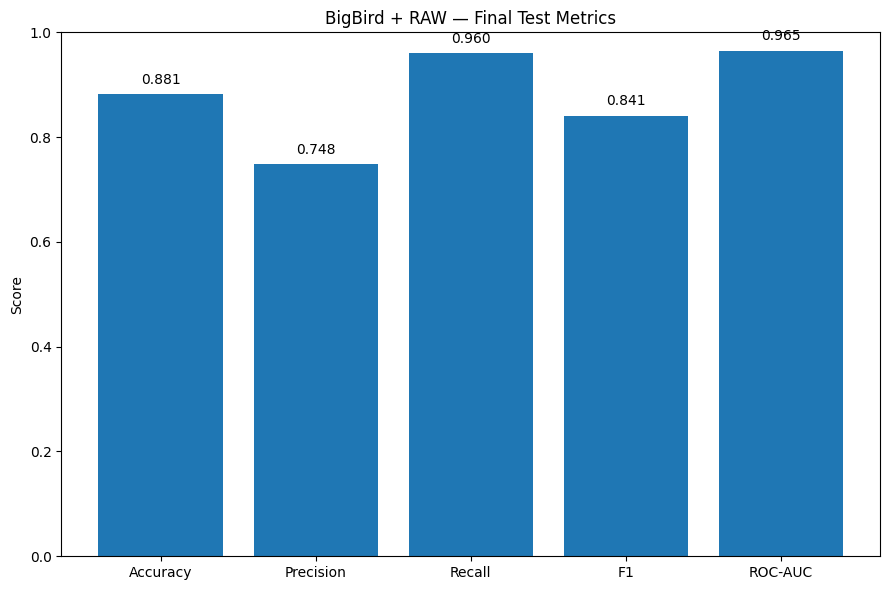

✓ Graph 1 saved: /kaggle/working/bigbird_raw_results/graphs/01_bigbird_raw_final_test_metrics.png


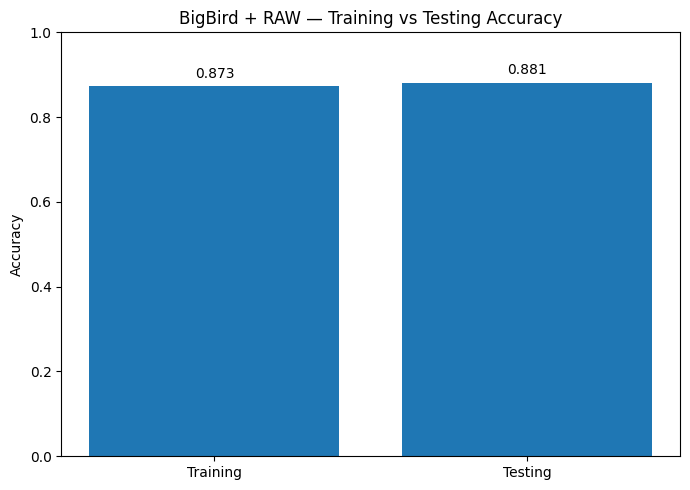

✓ Graph 2 saved: /kaggle/working/bigbird_raw_results/graphs/02_bigbird_raw_training_testing_accuracy.png


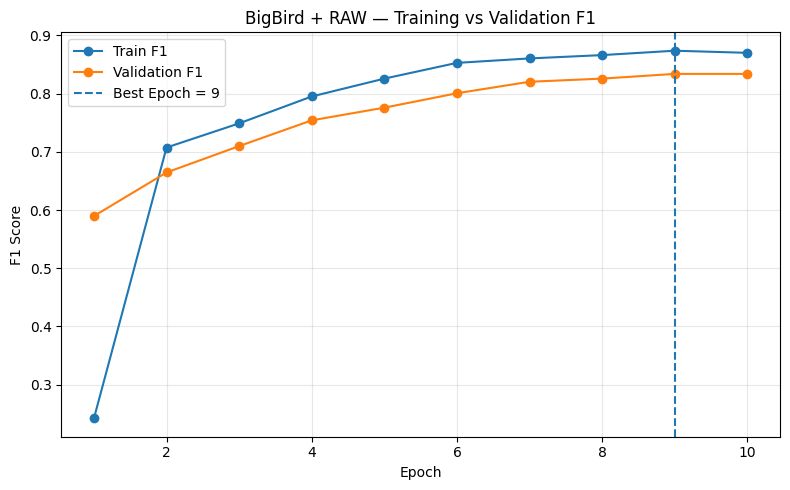

✓ Graph 3 saved: /kaggle/working/bigbird_raw_results/graphs/03_bigbird_raw_training_validation_f1.png


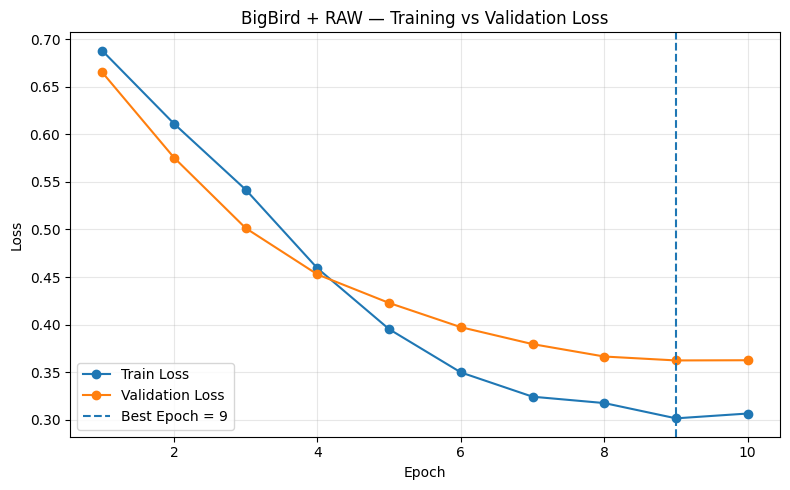

✓ Graph 4 saved: /kaggle/working/bigbird_raw_results/graphs/04_bigbird_raw_training_validation_loss.png


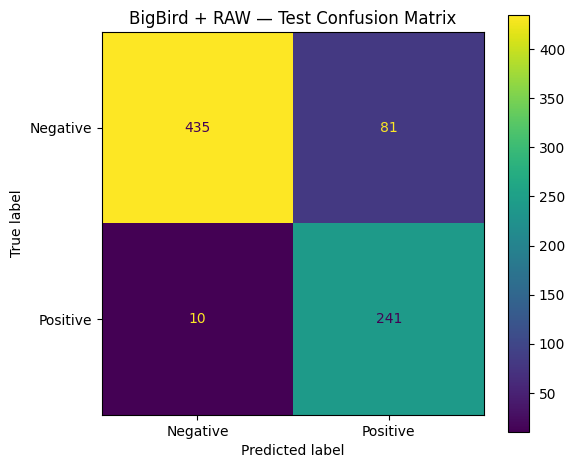

✓ Graph 5 saved: /kaggle/working/bigbird_raw_results/graphs/05_bigbird_raw_confusion_matrix.png


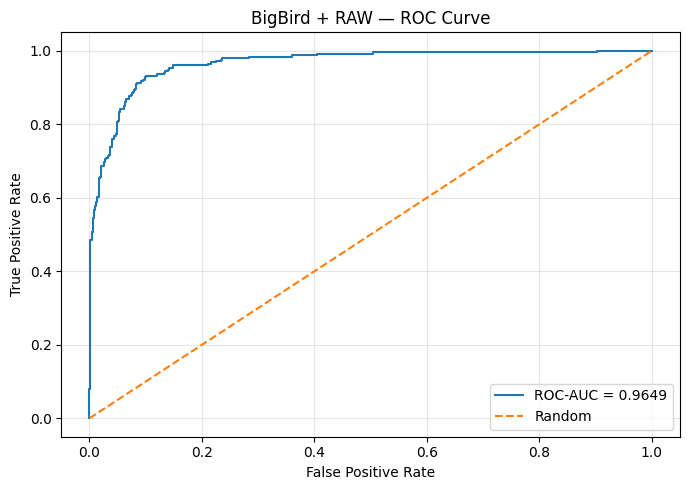

✓ Graph 6 saved: /kaggle/working/bigbird_raw_results/graphs/06_bigbird_raw_roc_curve.png


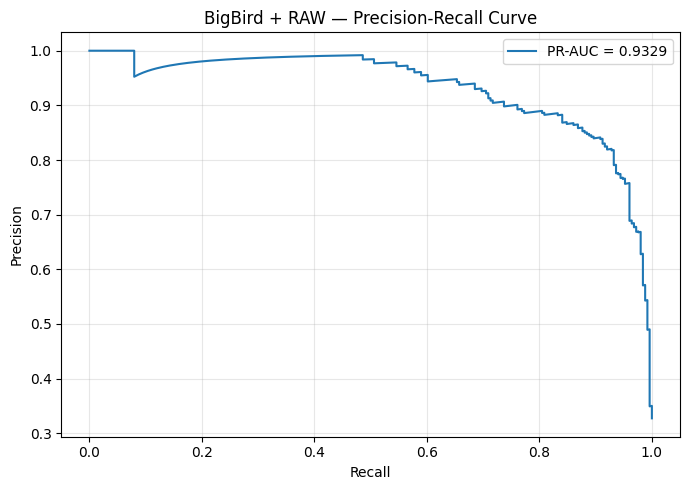

✓ Graph 7 saved: /kaggle/working/bigbird_raw_results/graphs/07_bigbird_raw_precision_recall.png


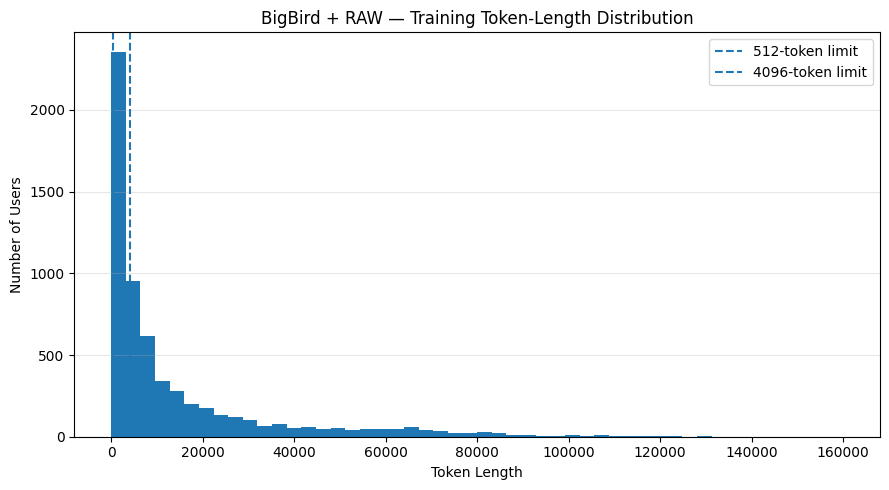

✓ Graph 8 saved: /kaggle/working/bigbird_raw_results/graphs/08_bigbird_raw_token_length_distribution.png

CONTEXT WINDOW COVERAGE


,Split,≤512 tokens (%),≤4096 tokens (%)
0,Train,10.89,44.16
1,Validation,10.30,44.72
2,Test,10.82,43.55


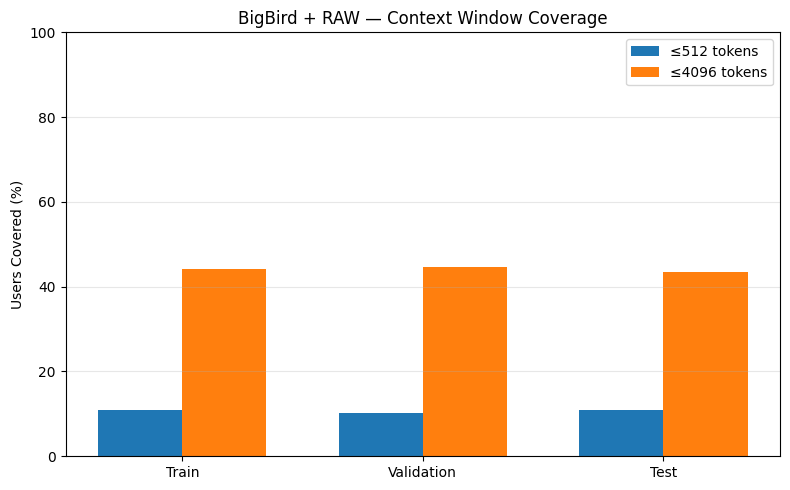

✓ Graph 9 saved: /kaggle/working/bigbird_raw_results/graphs/09_bigbird_raw_context_coverage.png


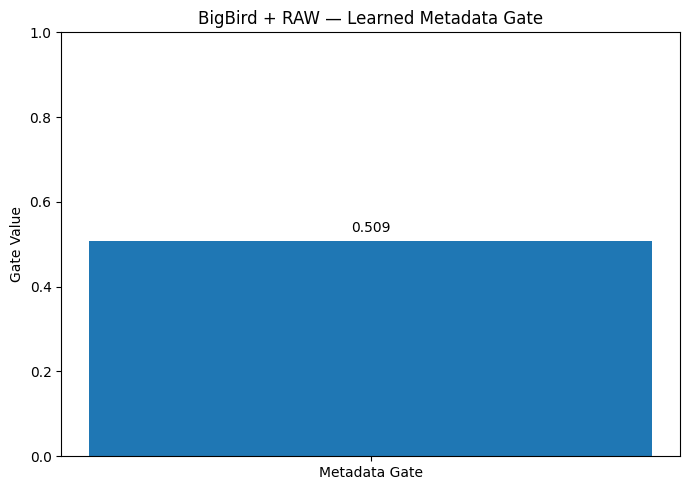

✓ Graph 10 saved: /kaggle/working/bigbird_raw_results/graphs/10_bigbird_raw_metadata_gate.png


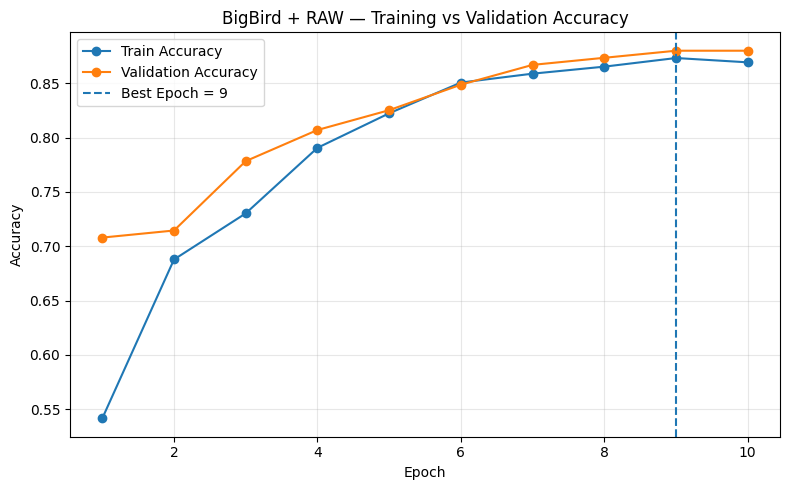

✓ Graph 11 saved: /kaggle/working/bigbird_raw_results/graphs/11_bigbird_raw_training_validation_accuracy.png

BIGBIRD + RAW — FINAL SUMMARY


,Model,Cleaning,Best Epoch,Training Accuracy,Testing Accuracy,Best Validation F1,Test Precision,Test Recall,Test F1,Test ROC-AUC,Metadata Gate,Context Length,Metadata Features,TN,FP,FN,TP
0,BigBird,RAW,9,87.33%,88.14%,83.39%,74.84%,96.02%,84.12%,96.49%,0.5089,512,53,435,81,10,241



CELL 14 COMPLETE
✓ Test metrics calculated
✓ Test metrics saved
✓ Test predictions saved
✓ Confusion matrix saved
✓ 11 graphs generated
✓ All graphs displayed
✓ All graphs saved as PNG
✓ Training/testing accuracy table saved
✓ Context coverage table saved
✓ Final summary saved
✓ Graph index saved

Graph folder:
/kaggle/working/bigbird_raw_results/graphs

Accuracy table:
/kaggle/working/bigbird_raw_results/bigbird_raw_training_testing_accuracy_table.csv

Final summary:
/kaggle/working/bigbird_raw_results/bigbird_raw_final_summary.csv


In [15]:
# ============================================================
# CELL 14 — BIGBIRD + RAW
# COMPLETE TEST RESULTS + ALL GRAPHS
# TRAINING / TESTING ACCURACY TABLE
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    roc_curve,
    precision_recall_curve,
    auc,
    ConfusionMatrixDisplay
)

print("=" * 60)
print("BIGBIRD + RAW — COMPLETE RESULT VISUALIZATION")
print("=" * 60)


# ------------------------------------------------------------
# DIRECTORIES
# ------------------------------------------------------------

GRAPH_DIR = os.path.join(
    RAW_RESULT_DIR,
    "graphs"
)

os.makedirs(
    GRAPH_DIR,
    exist_ok=True
)


# ------------------------------------------------------------
# LOAD TRAINING HISTORY
# ------------------------------------------------------------

history_raw_df = pd.read_csv(
    os.path.join(
        RAW_RESULT_DIR,
        "bigbird_raw_training_history.csv"
    )
)

print()
print("✓ Training history loaded")


# ------------------------------------------------------------
# BEST EPOCH
# ------------------------------------------------------------

best_epoch_raw = int(
    history_raw_df.loc[
        history_raw_df["val_f1"].idxmax(),
        "epoch"
    ]
)

best_val_f1_raw = float(
    history_raw_df["val_f1"].max()
)

print(
    "Best epoch:",
    best_epoch_raw
)

print(
    "Best validation F1:",
    f"{best_val_f1_raw:.4f}"
)


# ============================================================
# TEST EVALUATION
# ============================================================

print()
print("=" * 60)
print("BIGBIRD + RAW — TEST EVALUATION")
print("=" * 60)


# ------------------------------------------------------------
# LOAD BEST CHECKPOINT
# ------------------------------------------------------------

best_checkpoint_path_raw = os.path.join(
    RAW_CHECKPOINT_DIR,
    "best_raw_bigbird_metadata.pt"
)

assert os.path.exists(
    best_checkpoint_path_raw
)

best_checkpoint_raw = torch.load(
    best_checkpoint_path_raw,
    map_location=device,
    weights_only=False
)

model_raw.load_state_dict(
    best_checkpoint_raw["model_state_dict"]
)

model_raw = model_raw.to(device)
model_raw.eval()

print("✓ Best checkpoint loaded")


# ------------------------------------------------------------
# TEST PREDICTIONS
# ------------------------------------------------------------

criterion_raw = torch.nn.CrossEntropyLoss()

test_losses_raw = []

test_labels_all_raw = []
test_probs_all_raw = []
test_predictions_all_raw = []

evaluated_users_raw = 0


with torch.no_grad():

    for batch_idx, batch in enumerate(
        test_loader_raw,
        start=1
    ):

        input_ids = (
            batch["input_ids"]
            .to(device)
        )

        attention_mask = (
            batch["attention_mask"]
            .to(device)
        )

        metadata = (
            batch["metadata"]
            .to(device)
        )

        labels = (
            batch["labels"]
            .to(device)
        )

        outputs = model_raw(
            input_ids=input_ids,
            attention_mask=attention_mask,
            metadata=metadata
        )

        logits = outputs[
            "logits"
        ]

        loss = criterion_raw(
            logits,
            labels
        )

        probabilities = torch.softmax(
            logits.float(),
            dim=1
        )[:, 1]

        predictions = (
            probabilities >= 0.5
        ).long()

        test_losses_raw.append(
            float(
                loss.detach()
                .cpu()
            )
        )

        test_labels_all_raw.extend(
            labels.detach()
            .cpu()
            .numpy()
            .tolist()
        )

        test_probs_all_raw.extend(
            probabilities.detach()
            .cpu()
            .numpy()
            .tolist()
        )

        test_predictions_all_raw.extend(
            predictions.detach()
            .cpu()
            .numpy()
            .tolist()
        )

        evaluated_users_raw += len(
            labels
        )

        if (
            batch_idx == 1
            or batch_idx % 10 == 0
            or batch_idx
            == len(test_loader_raw)
        ):

            print(
                f"Test batch "
                f"{batch_idx}/"
                f"{len(test_loader_raw)}"
            )


# ------------------------------------------------------------
# TEST METRICS
# ------------------------------------------------------------

test_loss_raw = float(
    np.mean(
        test_losses_raw
    )
)

test_accuracy_raw = accuracy_score(
    test_labels_all_raw,
    test_predictions_all_raw
)

test_precision_raw = precision_score(
    test_labels_all_raw,
    test_predictions_all_raw,
    zero_division=0
)

test_recall_raw = recall_score(
    test_labels_all_raw,
    test_predictions_all_raw,
    zero_division=0
)

test_f1_raw = f1_score(
    test_labels_all_raw,
    test_predictions_all_raw,
    zero_division=0
)

test_roc_auc_raw = roc_auc_score(
    test_labels_all_raw,
    test_probs_all_raw
)

cm_raw = confusion_matrix(
    test_labels_all_raw,
    test_predictions_all_raw
)


# ------------------------------------------------------------
# INTEGRITY
# ------------------------------------------------------------

assert evaluated_users_raw == 767
assert len(test_labels_all_raw) == 767
assert len(test_probs_all_raw) == 767
assert len(test_predictions_all_raw) == 767

print()
print("✓ 767 / 767 test users evaluated exactly once")


# ------------------------------------------------------------
# PRINT RESULTS
# ------------------------------------------------------------

print()
print("=" * 60)
print("BIGBIRD + RAW — FINAL TEST RESULTS")
print("=" * 60)

print(
    "Test Loss:",
    f"{test_loss_raw:.4f}"
)

print(
    "Test Accuracy:",
    f"{test_accuracy_raw * 100:.2f}%"
)

print(
    "Test Precision:",
    f"{test_precision_raw * 100:.2f}%"
)

print(
    "Test Recall:",
    f"{test_recall_raw * 100:.2f}%"
)

print(
    "Test F1:",
    f"{test_f1_raw * 100:.2f}%"
)

print(
    "Test ROC-AUC:",
    f"{test_roc_auc_raw * 100:.2f}%"
)


# ============================================================
# SAVE TEST RESULTS
# ============================================================

raw_test_metrics_df = pd.DataFrame([

    {
        "Model":
            "BigBird",

        "Cleaning":
            "RAW",

        "Test Loss":
            test_loss_raw,

        "Accuracy (%)":
            test_accuracy_raw * 100,

        "Precision (%)":
            test_precision_raw * 100,

        "Recall (%)":
            test_recall_raw * 100,

        "F1 (%)":
            test_f1_raw * 100,

        "ROC-AUC (%)":
            test_roc_auc_raw * 100,

        "Best Epoch":
            best_epoch_raw,

        "Best Val F1 (%)":
            best_val_f1_raw * 100,

        "TN":
            int(cm_raw[0, 0]),

        "FP":
            int(cm_raw[0, 1]),

        "FN":
            int(cm_raw[1, 0]),

        "TP":
            int(cm_raw[1, 1])
    }
])

test_metrics_path_raw = os.path.join(
    RAW_RESULT_DIR,
    "bigbird_raw_test_metrics.csv"
)

raw_test_metrics_df.to_csv(
    test_metrics_path_raw,
    index=False
)

print(
    "✓ Test metrics saved:",
    test_metrics_path_raw
)


# ------------------------------------------------------------
# SAVE TEST PREDICTIONS
# ------------------------------------------------------------

raw_test_predictions_df = pd.DataFrame({

    "username":
        test_raw_df["username"].values,

    "label":
        np.asarray(
            test_labels_all_raw
        ),

    "probability":
        np.asarray(
            test_probs_all_raw
        ),

    "prediction":
        np.asarray(
            test_predictions_all_raw
        )
})

raw_test_predictions_df.to_csv(
    os.path.join(
        RAW_RESULT_DIR,
        "bigbird_raw_test_predictions.csv"
    ),
    index=False
)


# ------------------------------------------------------------
# SAVE CONFUSION MATRIX
# ------------------------------------------------------------

cm_df_raw = pd.DataFrame(
    cm_raw,
    index=[
        "Actual 0",
        "Actual 1"
    ],
    columns=[
        "Predicted 0",
        "Predicted 1"
    ]
)

cm_df_raw.to_csv(
    os.path.join(
        RAW_RESULT_DIR,
        "bigbird_raw_confusion_matrix.csv"
    )
)


# ============================================================
# TRAINING ACCURACY
# ============================================================

# Accuracy at BEST VALIDATION-F1 epoch
training_accuracy_raw = float(
    history_raw_df.loc[
        history_raw_df["epoch"] == best_epoch_raw,
        "train_accuracy"
    ].iloc[0]
)

testing_accuracy_raw = float(
    test_accuracy_raw
)


# ============================================================
# ACCURACY TABLE
# ============================================================

accuracy_table_raw = pd.DataFrame({

    "Dataset": [
        "Training",
        "Testing"
    ],

    "Accuracy": [
        training_accuracy_raw,
        testing_accuracy_raw
    ],

    "Accuracy (%)": [
        training_accuracy_raw * 100,
        testing_accuracy_raw * 100
    ]
})

print()
print("=" * 60)
print("TRAINING vs TESTING ACCURACY")
print("=" * 60)

display(
    accuracy_table_raw.style.format({
        "Accuracy":
            "{:.4f}",

        "Accuracy (%)":
            "{:.2f}%"
    })
)

accuracy_table_path_raw = os.path.join(
    RAW_RESULT_DIR,
    "bigbird_raw_training_testing_accuracy_table.csv"
)

accuracy_table_raw.to_csv(
    accuracy_table_path_raw,
    index=False
)

print(
    "✓ Accuracy table saved:",
    accuracy_table_path_raw
)


# ============================================================
# GRAPH 1 — FINAL TEST METRICS
# ============================================================

final_metrics_raw = {

    "Accuracy":
        test_accuracy_raw,

    "Precision":
        test_precision_raw,

    "Recall":
        test_recall_raw,

    "F1":
        test_f1_raw,

    "ROC-AUC":
        test_roc_auc_raw
}

plt.figure(
    figsize=(9, 6)
)

bars = plt.bar(
    final_metrics_raw.keys(),
    final_metrics_raw.values()
)

plt.ylim(
    0,
    1
)

plt.ylabel(
    "Score"
)

plt.title(
    "BigBird + RAW — Final Test Metrics"
)

for bar, value in zip(
    bars,
    final_metrics_raw.values()
):

    plt.text(
        bar.get_x()
        + bar.get_width() / 2,
        value + 0.02,
        f"{value:.3f}",
        ha="center"
    )

plt.tight_layout()

graph1_path = os.path.join(
    GRAPH_DIR,
    "01_bigbird_raw_final_test_metrics.png"
)

plt.savefig(
    graph1_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "✓ Graph 1 saved:",
    graph1_path
)


# ============================================================
# GRAPH 2 — TRAINING VS TESTING ACCURACY
# ============================================================

plt.figure(
    figsize=(7, 5)
)

bars = plt.bar(
    accuracy_table_raw["Dataset"],
    accuracy_table_raw["Accuracy"]
)

plt.ylim(
    0,
    1
)

plt.ylabel(
    "Accuracy"
)

plt.title(
    "BigBird + RAW — Training vs Testing Accuracy"
)

for bar, value in zip(
    bars,
    accuracy_table_raw["Accuracy"]
):

    plt.text(
        bar.get_x()
        + bar.get_width() / 2,
        value + 0.02,
        f"{value:.3f}",
        ha="center"
    )

plt.tight_layout()

graph2_path = os.path.join(
    GRAPH_DIR,
    "02_bigbird_raw_training_testing_accuracy.png"
)

plt.savefig(
    graph2_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "✓ Graph 2 saved:",
    graph2_path
)


# ============================================================
# GRAPH 3 — TRAINING VS VALIDATION F1
# ============================================================

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    history_raw_df["epoch"],
    history_raw_df["train_f1"],
    marker="o",
    label="Train F1"
)

plt.plot(
    history_raw_df["epoch"],
    history_raw_df["val_f1"],
    marker="o",
    label="Validation F1"
)

plt.axvline(
    best_epoch_raw,
    linestyle="--",
    label=f"Best Epoch = {best_epoch_raw}"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "F1 Score"
)

plt.title(
    "BigBird + RAW — Training vs Validation F1"
)

plt.legend()
plt.grid(
    alpha=0.3
)

plt.tight_layout()

graph3_path = os.path.join(
    GRAPH_DIR,
    "03_bigbird_raw_training_validation_f1.png"
)

plt.savefig(
    graph3_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "✓ Graph 3 saved:",
    graph3_path
)


# ============================================================
# GRAPH 4 — TRAINING VS VALIDATION LOSS
# ============================================================

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    history_raw_df["epoch"],
    history_raw_df["train_loss"],
    marker="o",
    label="Train Loss"
)

plt.plot(
    history_raw_df["epoch"],
    history_raw_df["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.axvline(
    best_epoch_raw,
    linestyle="--",
    label=f"Best Epoch = {best_epoch_raw}"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Loss"
)

plt.title(
    "BigBird + RAW — Training vs Validation Loss"
)

plt.legend()
plt.grid(
    alpha=0.3
)

plt.tight_layout()

graph4_path = os.path.join(
    GRAPH_DIR,
    "04_bigbird_raw_training_validation_loss.png"
)

plt.savefig(
    graph4_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "✓ Graph 4 saved:",
    graph4_path
)


# ============================================================
# GRAPH 5 — TEST CONFUSION MATRIX
# ============================================================

fig, ax = plt.subplots(
    figsize=(6, 5)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_raw,
    display_labels=[
        "Negative",
        "Positive"
    ]
)

disp.plot(
    ax=ax,
    values_format="d"
)

ax.set_title(
    "BigBird + RAW — Test Confusion Matrix"
)

plt.tight_layout()

graph5_path = os.path.join(
    GRAPH_DIR,
    "05_bigbird_raw_confusion_matrix.png"
)

plt.savefig(
    graph5_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "✓ Graph 5 saved:",
    graph5_path
)


# ============================================================
# GRAPH 6 — ROC CURVE
# ============================================================

fpr_raw, tpr_raw, _ = roc_curve(
    test_labels_all_raw,
    test_probs_all_raw
)

roc_auc_plot_raw = auc(
    fpr_raw,
    tpr_raw
)

plt.figure(
    figsize=(7, 5)
)

plt.plot(
    fpr_raw,
    tpr_raw,
    label=f"ROC-AUC = {roc_auc_plot_raw:.4f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random"
)

plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.title(
    "BigBird + RAW — ROC Curve"
)

plt.legend()
plt.grid(
    alpha=0.3
)

plt.tight_layout()

graph6_path = os.path.join(
    GRAPH_DIR,
    "06_bigbird_raw_roc_curve.png"
)

plt.savefig(
    graph6_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "✓ Graph 6 saved:",
    graph6_path
)


# ============================================================
# GRAPH 7 — PRECISION-RECALL CURVE
# ============================================================

precision_curve_raw, recall_curve_raw, _ = (
    precision_recall_curve(
        test_labels_all_raw,
        test_probs_all_raw
    )
)

pr_auc_raw = auc(
    recall_curve_raw,
    precision_curve_raw
)

plt.figure(
    figsize=(7, 5)
)

plt.plot(
    recall_curve_raw,
    precision_curve_raw,
    label=f"PR-AUC = {pr_auc_raw:.4f}"
)

plt.xlabel(
    "Recall"
)

plt.ylabel(
    "Precision"
)

plt.title(
    "BigBird + RAW — Precision-Recall Curve"
)

plt.legend()
plt.grid(
    alpha=0.3
)

plt.tight_layout()

graph7_path = os.path.join(
    GRAPH_DIR,
    "07_bigbird_raw_precision_recall.png"
)

plt.savefig(
    graph7_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "✓ Graph 7 saved:",
    graph7_path
)


# ============================================================
# GRAPH 8 — TOKEN LENGTH DISTRIBUTION
# ============================================================

plt.figure(
    figsize=(9, 5)
)

plt.hist(
    train_raw_token_lengths,
    bins=50
)

plt.axvline(
    512,
    linestyle="--",
    label="512-token limit"
)

plt.axvline(
    4096,
    linestyle="--",
    label="4096-token limit"
)

plt.xlabel(
    "Token Length"
)

plt.ylabel(
    "Number of Users"
)

plt.title(
    "BigBird + RAW — Training Token-Length Distribution"
)

plt.legend()

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

graph8_path = os.path.join(
    GRAPH_DIR,
    "08_bigbird_raw_token_length_distribution.png"
)

plt.savefig(
    graph8_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "✓ Graph 8 saved:",
    graph8_path
)


# ============================================================
# GRAPH 9 — CONTEXT WINDOW COVERAGE
# ============================================================

coverage_raw_df = pd.DataFrame({

    "Split": [
        "Train",
        "Validation",
        "Test"
    ],

    "≤512 tokens (%)": [

        np.mean(
            train_raw_token_lengths <= 512
        ) * 100,

        np.mean(
            val_raw_token_lengths <= 512
        ) * 100,

        np.mean(
            test_raw_token_lengths <= 512
        ) * 100
    ],

    "≤4096 tokens (%)": [

        np.mean(
            train_raw_token_lengths <= 4096
        ) * 100,

        np.mean(
            val_raw_token_lengths <= 4096
        ) * 100,

        np.mean(
            test_raw_token_lengths <= 4096
        ) * 100
    ]
})

print()
print("=" * 60)
print("CONTEXT WINDOW COVERAGE")
print("=" * 60)

display(
    coverage_raw_df.style.format({
        "≤512 tokens (%)":
            "{:.2f}",

        "≤4096 tokens (%)":
            "{:.2f}"
    })
)

coverage_raw_df.to_csv(
    os.path.join(
        RAW_RESULT_DIR,
        "bigbird_raw_context_window_coverage.csv"
    ),
    index=False
)


plt.figure(
    figsize=(8, 5)
)

x = np.arange(
    len(
        coverage_raw_df
    )
)

width = 0.35

plt.bar(
    x - width / 2,
    coverage_raw_df[
        "≤512 tokens (%)"
    ],
    width,
    label="≤512 tokens"
)

plt.bar(
    x + width / 2,
    coverage_raw_df[
        "≤4096 tokens (%)"
    ],
    width,
    label="≤4096 tokens"
)

plt.xticks(
    x,
    coverage_raw_df["Split"]
)

plt.ylabel(
    "Users Covered (%)"
)

plt.ylim(
    0,
    100
)

plt.title(
    "BigBird + RAW — Context Window Coverage"
)

plt.legend()
plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

graph9_path = os.path.join(
    GRAPH_DIR,
    "09_bigbird_raw_context_coverage.png"
)

plt.savefig(
    graph9_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "✓ Graph 9 saved:",
    graph9_path
)


# ============================================================
# GRAPH 10 — METADATA GATE
# ============================================================

metadata_beta_raw_final = float(
    model_raw.metadata_beta
    .detach()
    .cpu()
)

metadata_gate_raw_final = float(
    torch.sigmoid(
        model_raw.metadata_beta
    )
    .detach()
    .cpu()
)

plt.figure(
    figsize=(7, 5)
)

bar = plt.bar(
    ["Metadata Gate"],
    [metadata_gate_raw_final]
)

plt.ylim(
    0,
    1
)

plt.ylabel(
    "Gate Value"
)

plt.title(
    "BigBird + RAW — Learned Metadata Gate"
)

plt.text(
    bar[0].get_x()
    + bar[0].get_width() / 2,
    metadata_gate_raw_final + 0.02,
    f"{metadata_gate_raw_final:.3f}",
    ha="center"
)

plt.tight_layout()

graph10_path = os.path.join(
    GRAPH_DIR,
    "10_bigbird_raw_metadata_gate.png"
)

plt.savefig(
    graph10_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "✓ Graph 10 saved:",
    graph10_path
)


# ============================================================
# GRAPH 11 — TRAINING VS VALIDATION ACCURACY
# ============================================================

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    history_raw_df["epoch"],
    history_raw_df["train_accuracy"],
    marker="o",
    label="Train Accuracy"
)

plt.plot(
    history_raw_df["epoch"],
    history_raw_df["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.axvline(
    best_epoch_raw,
    linestyle="--",
    label=f"Best Epoch = {best_epoch_raw}"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Accuracy"
)

plt.title(
    "BigBird + RAW — Training vs Validation Accuracy"
)

plt.legend()
plt.grid(
    alpha=0.3
)

plt.tight_layout()

graph11_path = os.path.join(
    GRAPH_DIR,
    "11_bigbird_raw_training_validation_accuracy.png"
)

plt.savefig(
    graph11_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "✓ Graph 11 saved:",
    graph11_path
)


# ============================================================
# FINAL SUMMARY TABLE
# ============================================================

final_summary_raw = pd.DataFrame([

    {
        "Model":
            "BigBird",

        "Cleaning":
            "RAW",

        "Best Epoch":
            best_epoch_raw,

        "Training Accuracy":
            training_accuracy_raw,

        "Testing Accuracy":
            testing_accuracy_raw,

        "Best Validation F1":
            best_val_f1_raw,

        "Test Precision":
            test_precision_raw,

        "Test Recall":
            test_recall_raw,

        "Test F1":
            test_f1_raw,

        "Test ROC-AUC":
            test_roc_auc_raw,

        "Metadata Gate":
            metadata_gate_raw_final,

        "Context Length":
            512,

        "Metadata Features":
            53,

        "TN":
            int(cm_raw[0, 0]),

        "FP":
            int(cm_raw[0, 1]),

        "FN":
            int(cm_raw[1, 0]),

        "TP":
            int(cm_raw[1, 1])
    }
])

print()
print("=" * 60)
print("BIGBIRD + RAW — FINAL SUMMARY")
print("=" * 60)

display(
    final_summary_raw.style.format({

        "Training Accuracy":
            "{:.2%}",

        "Testing Accuracy":
            "{:.2%}",

        "Best Validation F1":
            "{:.2%}",

        "Test Precision":
            "{:.2%}",

        "Test Recall":
            "{:.2%}",

        "Test F1":
            "{:.2%}",

        "Test ROC-AUC":
            "{:.2%}",

        "Metadata Gate":
            "{:.4f}"
    })
)

final_summary_path_raw = os.path.join(
    RAW_RESULT_DIR,
    "bigbird_raw_final_summary.csv"
)

final_summary_raw.to_csv(
    final_summary_path_raw,
    index=False
)


# ============================================================
# GRAPH INDEX
# ============================================================

graph_index_raw = pd.DataFrame({

    "Graph":
        list(range(1, 12)),

    "Name": [

        "Final Test Metrics",

        "Training vs Testing Accuracy",

        "Training vs Validation F1",

        "Training vs Validation Loss",

        "Test Confusion Matrix",

        "ROC Curve",

        "Precision-Recall Curve",

        "Token-Length Distribution",

        "Context Window Coverage",

        "Metadata Gate",

        "Training vs Validation Accuracy"
    ],

    "File": [

        graph1_path,
        graph2_path,
        graph3_path,
        graph4_path,
        graph5_path,
        graph6_path,
        graph7_path,
        graph8_path,
        graph9_path,
        graph10_path,
        graph11_path
    ]
})

graph_index_path_raw = os.path.join(
    RAW_RESULT_DIR,
    "bigbird_raw_graph_index.csv"
)

graph_index_raw.to_csv(
    graph_index_path_raw,
    index=False
)


# ============================================================
# FINAL STATUS
# ============================================================

print()
print("=" * 60)
print("CELL 14 COMPLETE")
print("=" * 60)

print("✓ Test metrics calculated")
print("✓ Test metrics saved")
print("✓ Test predictions saved")
print("✓ Confusion matrix saved")
print("✓ 11 graphs generated")
print("✓ All graphs displayed")
print("✓ All graphs saved as PNG")
print("✓ Training/testing accuracy table saved")
print("✓ Context coverage table saved")
print("✓ Final summary saved")
print("✓ Graph index saved")

print()
print("Graph folder:")
print(GRAPH_DIR)

print()
print("Accuracy table:")
print(accuracy_table_path_raw)

print()
print("Final summary:")
print(final_summary_path_raw)

t-SNE REPRESENTATION ANALYSIS
BIGBIRD + RAW

Extracting fused model representations...
Processed batch 1/48
Processed batch 10/48
Processed batch 20/48
Processed batch 30/48
Processed batch 40/48
Processed batch 48/48

FUSED REPRESENTATION
Representation shape: (767, 832)
Number of test users: 767
Representation dimensions: 832
Negative users: 516
Positive users: 251

PCA REDUCTION
Original dimensions: 832
PCA dimensions: 50
Variance retained: 86.20%

t-SNE REDUCTION
t-SNE output shape: (767, 2)


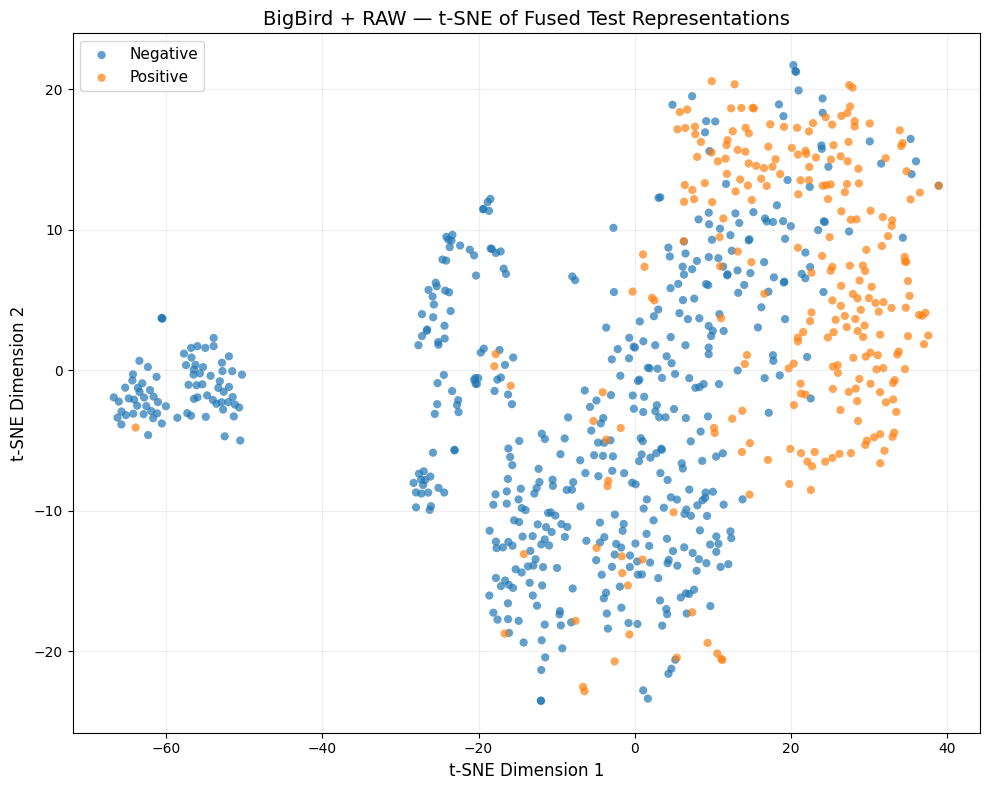


t-SNE ANALYSIS COMPLETE
✓ Fused representation extracted
✓ PCA reduction completed
✓ t-SNE reduction completed
✓ Coordinates saved:
/kaggle/working/bigbird_raw_results/explainability/tsne/bigbird_raw_tsne_coordinates.csv
✓ Graph saved:
/kaggle/working/bigbird_raw_results/explainability/tsne/bigbird_raw_tsne.png
✓ Graph displayed above
✓ Configuration saved


In [20]:
# ============================================================
# EXPLAINABILITY — CELL 1
# BIGBIRD + RAW
# t-SNE: FUSED REPRESENTATION → PCA → t-SNE
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

print("=" * 70)
print("t-SNE REPRESENTATION ANALYSIS")
print("BIGBIRD + RAW")
print("=" * 70)

# ============================================================
# FIXED EXPLAINABILITY SETTINGS
# ============================================================

EXPLAINABILITY_SEED = 42
PCA_COMPONENTS = 50
TSNE_COMPONENTS = 2
TSNE_PERPLEXITY = 30
TSNE_LEARNING_RATE = 200
TSNE_MAX_ITER = 1000

np.random.seed(
    EXPLAINABILITY_SEED
)

torch.manual_seed(
    EXPLAINABILITY_SEED
)

# ============================================================
# OUTPUT DIRECTORIES
# ============================================================

EXPLAINABILITY_DIR = os.path.join(
    RAW_RESULT_DIR,
    "explainability"
)

TSNE_DIR = os.path.join(
    EXPLAINABILITY_DIR,
    "tsne"
)

os.makedirs(
    TSNE_DIR,
    exist_ok=True
)

# ============================================================
# MODEL
# ============================================================

model_raw.eval()

# ============================================================
# EXTRACT FUSED REPRESENTATIONS
# ============================================================

fused_representations = []
test_labels = []

print()
print("Extracting fused model representations...")

with torch.no_grad():

    for batch_idx, batch in enumerate(
        test_loader_raw,
        start=1
    ):

        input_ids = batch[
            "input_ids"
        ].to(device)

        attention_mask = batch[
            "attention_mask"
        ].to(device)

        metadata = batch[
            "metadata"
        ].to(device)

        labels = batch[
            "labels"
        ].to(device)

        output = model_raw(
            input_ids=input_ids,
            attention_mask=attention_mask,
            metadata=metadata
        )

        # ----------------------------------------------------
        # EXACT MODEL OUTPUTS
        # ----------------------------------------------------

        text_representation = output[
            "text_representation"
        ]

        metadata_representation = output[
            "metadata_representation"
        ]

        # ----------------------------------------------------
        # SAME LEARNED METADATA GATE
        # ----------------------------------------------------

        metadata_gate = torch.sigmoid(
            model_raw.metadata_beta
        )

        gated_metadata = (
            metadata_gate
            *
            metadata_representation
        )

        # ----------------------------------------------------
        # EXACT FUSED REPRESENTATION
        # ----------------------------------------------------

        fused = torch.cat(
            [
                text_representation,
                gated_metadata
            ],
            dim=1
        )

        fused_representations.append(
            fused.cpu().numpy()
        )

        test_labels.extend(
            labels.cpu().numpy().tolist()
        )

        if (
            batch_idx == 1
            or batch_idx % 10 == 0
            or batch_idx == len(test_loader_raw)
        ):

            print(
                f"Processed batch "
                f"{batch_idx}/{len(test_loader_raw)}"
            )

# ============================================================
# COMBINE
# ============================================================

fused_representations = np.concatenate(
    fused_representations,
    axis=0
)

test_labels = np.array(
    test_labels
)

# ============================================================
# INTEGRITY
# ============================================================

print()
print("=" * 70)
print("FUSED REPRESENTATION")
print("=" * 70)

print(
    "Representation shape:",
    fused_representations.shape
)

print(
    "Number of test users:",
    len(test_labels)
)

print(
    "Representation dimensions:",
    fused_representations.shape[1]
)

print(
    "Negative users:",
    int(
        (test_labels == 0).sum()
    )
)

print(
    "Positive users:",
    int(
        (test_labels == 1).sum()
    )
)

assert (
    fused_representations.shape[0]
    ==
    len(test_labels)
)

assert np.isfinite(
    fused_representations
).all()

# ============================================================
# PCA
# ============================================================

print()
print("=" * 70)
print("PCA REDUCTION")
print("=" * 70)

pca_dimensions = min(
    PCA_COMPONENTS,
    fused_representations.shape[1]
)

pca = PCA(
    n_components=pca_dimensions,
    random_state=EXPLAINABILITY_SEED
)

pca_representation = pca.fit_transform(
    fused_representations
)

explained_variance = (
    pca.explained_variance_ratio_.sum()
)

print(
    "Original dimensions:",
    fused_representations.shape[1]
)

print(
    "PCA dimensions:",
    pca_representation.shape[1]
)

print(
    "Variance retained:",
    f"{explained_variance * 100:.2f}%"
)

# ============================================================
# t-SNE
# ============================================================

print()
print("=" * 70)
print("t-SNE REDUCTION")
print("=" * 70)

tsne = TSNE(
    n_components=TSNE_COMPONENTS,
    perplexity=TSNE_PERPLEXITY,
    learning_rate=TSNE_LEARNING_RATE,
    init="pca",
    random_state=EXPLAINABILITY_SEED,
    max_iter=TSNE_MAX_ITER
)

tsne_representation = tsne.fit_transform(
    pca_representation
)

print(
    "t-SNE output shape:",
    tsne_representation.shape
)

# ============================================================
# SAVE COORDINATES
# ============================================================

tsne_df = pd.DataFrame({

    "tsne_1":
        tsne_representation[:, 0],

    "tsne_2":
        tsne_representation[:, 1],

    "label":
        test_labels

})

tsne_df["class"] = tsne_df[
    "label"
].map({
    0: "Negative",
    1: "Positive"
})

tsne_csv_path = os.path.join(
    TSNE_DIR,
    "bigbird_raw_tsne_coordinates.csv"
)

tsne_df.to_csv(
    tsne_csv_path,
    index=False
)

# ============================================================
# PUBLICATION-QUALITY PLOT
# ============================================================

plt.figure(
    figsize=(10, 8)
)

negative_mask = (
    test_labels == 0
)

positive_mask = (
    test_labels == 1
)

plt.scatter(
    tsne_representation[
        negative_mask,
        0
    ],
    tsne_representation[
        negative_mask,
        1
    ],
    s=35,
    alpha=0.70,
    label="Negative",
    edgecolors="none"
)

plt.scatter(
    tsne_representation[
        positive_mask,
        0
    ],
    tsne_representation[
        positive_mask,
        1
    ],
    s=35,
    alpha=0.70,
    label="Positive",
    edgecolors="none"
)

plt.xlabel(
    "t-SNE Dimension 1",
    fontsize=12
)

plt.ylabel(
    "t-SNE Dimension 2",
    fontsize=12
)

plt.title(
    "BigBird + RAW — "
    "t-SNE of Fused Test Representations",
    fontsize=14
)

plt.legend(
    fontsize=11
)

plt.grid(
    alpha=0.20
)

plt.tight_layout()

tsne_plot_path = os.path.join(
    TSNE_DIR,
    "bigbird_raw_tsne.png"
)

# SAVE
plt.savefig(
    tsne_plot_path,
    dpi=300,
    bbox_inches="tight"
)

# DISPLAY
plt.show()

plt.close()

# ============================================================
# SAVE CONFIGURATION
# ============================================================

tsne_config = {

    "model":
        "BigBird",

    "cleaning":
        "RAW",

    "dataset":
        "Held-out test set",

    "test_users":
        int(
            len(test_labels)
        ),

    "input_representation":
        "Fused classifier representation",

    "text_representation_dimension":
        int(
            text_representation.shape[1]
        ),

    "metadata_representation_dimension":
        int(
            metadata_representation.shape[1]
        ),

    "fused_representation_dimension":
        int(
            fused_representations.shape[1]
        ),

    "pca_dimensions":
        int(
            pca_dimensions
        ),

    "pca_variance_retained":
        float(
            explained_variance
        ),

    "tsne_dimensions":
        int(
            TSNE_COMPONENTS
        ),

    "tsne_perplexity":
        int(
            TSNE_PERPLEXITY
        ),

    "tsne_learning_rate":
        TSNE_LEARNING_RATE,

    "tsne_max_iterations":
        int(
            TSNE_MAX_ITER
        ),

    "random_seed":
        EXPLAINABILITY_SEED

}

with open(
    os.path.join(
        TSNE_DIR,
        "bigbird_raw_tsne_config.json"
    ),
    "w"
) as f:

    json.dump(
        tsne_config,
        f,
        indent=2
    )

# ============================================================
# FINAL OUTPUT
# ============================================================

print()
print("=" * 70)
print("t-SNE ANALYSIS COMPLETE")
print("=" * 70)

print(
    "✓ Fused representation extracted"
)

print(
    "✓ PCA reduction completed"
)

print(
    "✓ t-SNE reduction completed"
)

print(
    "✓ Coordinates saved:"
)

print(
    tsne_csv_path
)

print(
    "✓ Graph saved:"
)

print(
    tsne_plot_path
)

print(
    "✓ Graph displayed above"
)

print(
    "✓ Configuration saved"
)

GRAD-CAM EXPLAINABILITY
BIGBIRD + RAW
TEST PREDICTIONS READY
Test samples : 767
SELECTED CASES
TP : test index 1 | true=1 | pred=1 | probability=0.8327
TN : test index 0 | true=0 | pred=0 | probability=0.3739
FP : test index 8 | true=0 | pred=1 | probability=0.6044
FN : test index 94 | true=1 | pred=0 | probability=0.4126
PROCESSING TP
Test index : 1


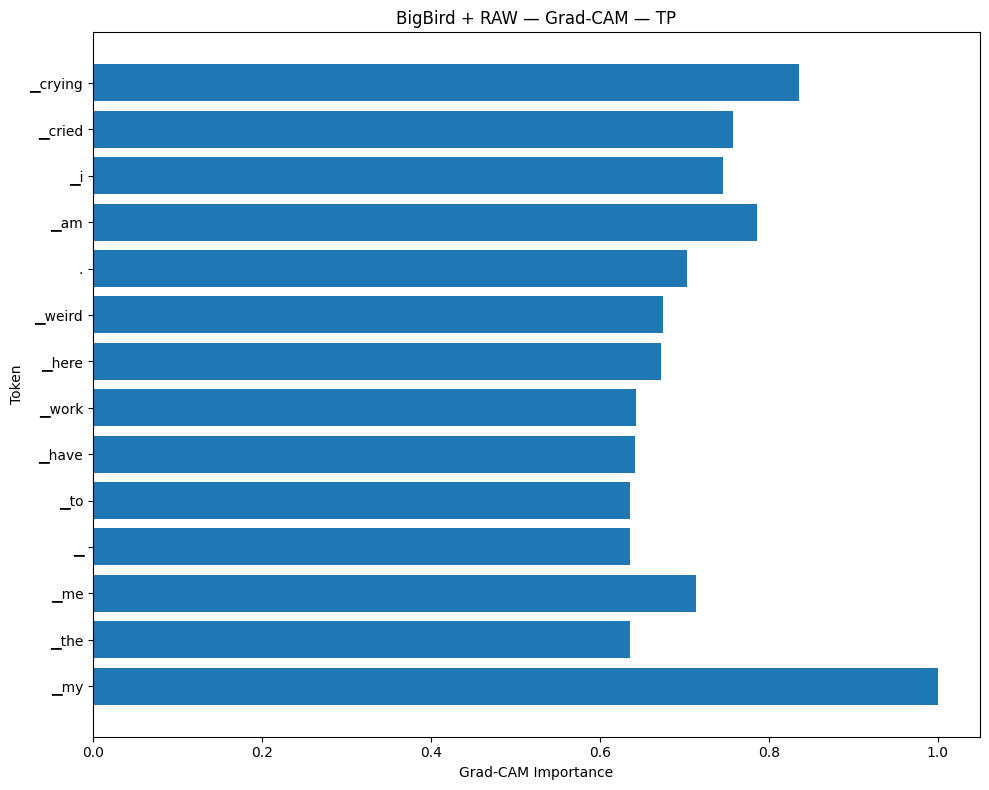

Saved: /kaggle/working/bigbird_raw_results/explainability/gradcam/bigbird_raw_gradcam_tp_tokens.csv
PROCESSING TN
Test index : 0


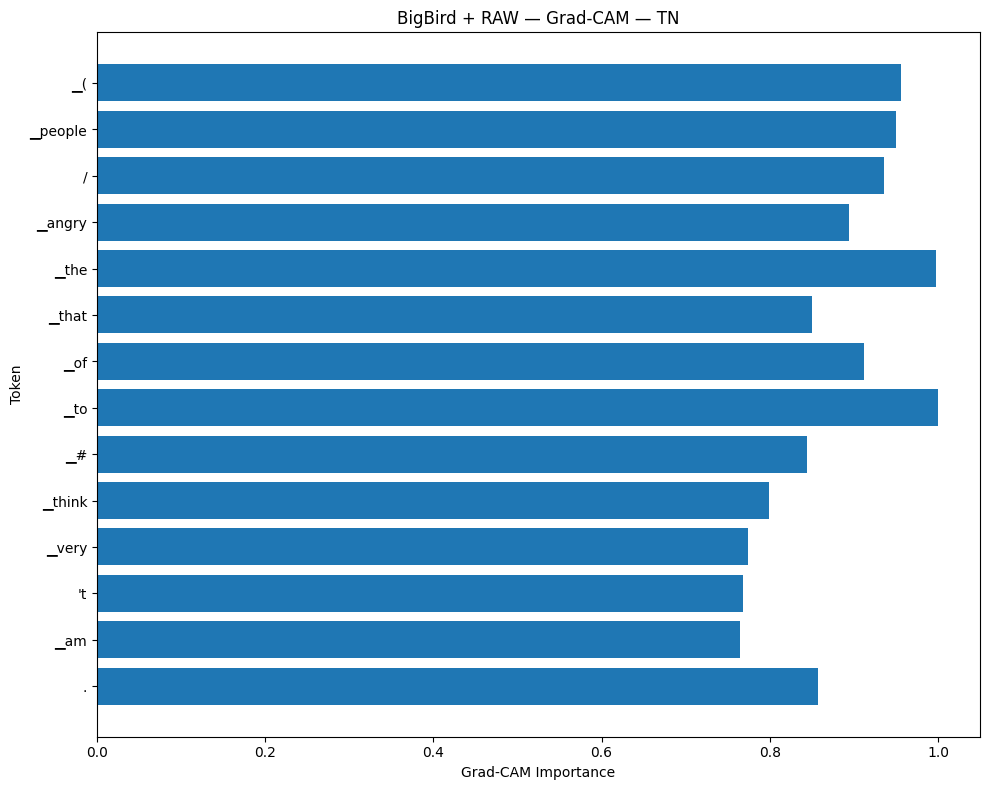

Saved: /kaggle/working/bigbird_raw_results/explainability/gradcam/bigbird_raw_gradcam_tn_tokens.csv
PROCESSING FP
Test index : 8


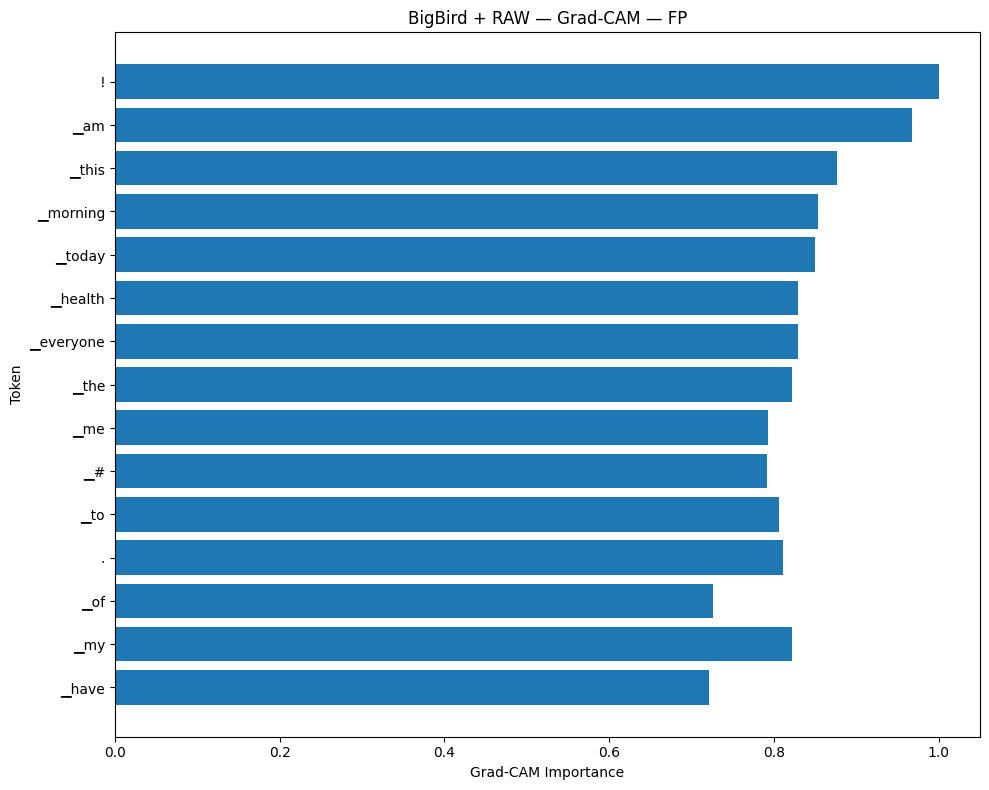

Saved: /kaggle/working/bigbird_raw_results/explainability/gradcam/bigbird_raw_gradcam_fp_tokens.csv
PROCESSING FN
Test index : 94


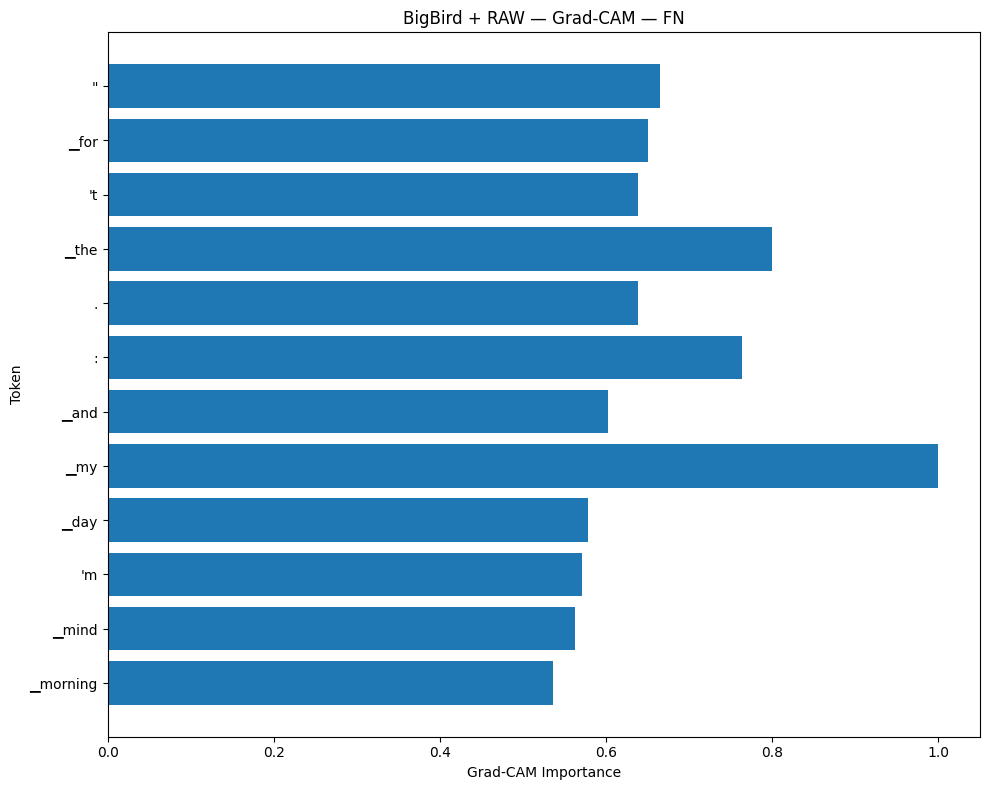

Saved: /kaggle/working/bigbird_raw_results/explainability/gradcam/bigbird_raw_gradcam_fn_tokens.csv
GRAD-CAM COMPLETE
Output directory:
/kaggle/working/bigbird_raw_results/explainability/gradcam
Configuration saved:
/kaggle/working/bigbird_raw_results/explainability/gradcam/bigbird_raw_gradcam_config.json
Cases processed: ['TP', 'TN', 'FP', 'FN']


In [21]:
# ============================================================
# EXPLAINABILITY — CELL 2
# BIGBIRD + RAW
# GRAD-CAM: TOKEN-LEVEL LOCAL EXPLANATION
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

print("=" * 70)
print("GRAD-CAM EXPLAINABILITY")
print("BIGBIRD + RAW")
print("=" * 70)

GRADCAM_SEED = 42
GRADCAM_TOP_TOKENS = 20

np.random.seed(GRADCAM_SEED)
torch.manual_seed(GRADCAM_SEED)

EXPLAINABILITY_DIR = os.path.join(
    RAW_RESULT_DIR,
    "explainability"
)

GRADCAM_DIR = os.path.join(
    EXPLAINABILITY_DIR,
    "gradcam"
)

os.makedirs(GRADCAM_DIR, exist_ok=True)

model_raw.eval()

# ============================================================
# STEP 1 — CALCULATE TEST PREDICTIONS
# ============================================================

labels_np = []
preds_np = []
probs_np = []

with torch.no_grad():

    for batch in test_loader_raw:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        metadata = batch["metadata"].to(device)

        output = model_raw(
            input_ids=input_ids,
            attention_mask=attention_mask,
            metadata=metadata
        )

        logits = output["logits"]

        probabilities = torch.softmax(logits, dim=1)
        predictions = torch.argmax(logits, dim=1)

        labels_np.extend(
            batch["labels"].cpu().numpy().tolist()
        )

        preds_np.extend(
            predictions.cpu().numpy().tolist()
        )

        probs_np.extend(
            probabilities[:, 1].cpu().numpy().tolist()
        )

labels_np = np.array(labels_np)
preds_np = np.array(preds_np)
probs_np = np.array(probs_np)

print("=" * 70)
print("TEST PREDICTIONS READY")
print(f"Test samples : {len(labels_np)}")
print("=" * 70)


# ============================================================
# STEP 2 — SELECT TP / TN / FP / FN CASES
# ============================================================

selected_cases = {}

tp_candidates = np.where(
    (labels_np == 1) & (preds_np == 1)
)[0]

tn_candidates = np.where(
    (labels_np == 0) & (preds_np == 0)
)[0]

fp_candidates = np.where(
    (labels_np == 0) & (preds_np == 1)
)[0]

fn_candidates = np.where(
    (labels_np == 1) & (preds_np == 0)
)[0]

if len(tp_candidates) > 0:
    selected_cases["TP"] = int(tp_candidates[0])

if len(tn_candidates) > 0:
    selected_cases["TN"] = int(tn_candidates[0])

if len(fp_candidates) > 0:
    selected_cases["FP"] = int(fp_candidates[0])

if len(fn_candidates) > 0:
    selected_cases["FN"] = int(fn_candidates[0])

print("=" * 70)
print("SELECTED CASES")
print("=" * 70)

for case_type, test_index in selected_cases.items():

    print(
        f"{case_type} : test index {test_index} | "
        f"true={labels_np[test_index]} | "
        f"pred={preds_np[test_index]} | "
        f"probability={probs_np[test_index]:.4f}"
    )


# ============================================================
# STEP 3 — GRAD-CAM COMPUTATION
# ============================================================

def compute_bigbird_raw_gradcam(test_index):

    sample = test_dataset_raw[test_index]

    input_ids = sample["input_ids"].unsqueeze(0).to(device)
    attention_mask = sample["attention_mask"].unsqueeze(0).to(device)
    metadata = sample["metadata"].unsqueeze(0).to(device)

    # --------------------------------------------------------
    # BIGBIRD ENCODER
    # --------------------------------------------------------

    with torch.no_grad():

        bigbird_output = model_raw.bigbird(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

    hidden_states = bigbird_output.last_hidden_state.detach()
    hidden_states.requires_grad_(True)
    hidden_states.retain_grad()

    # --------------------------------------------------------
    # ATTENTION POOLING
    # --------------------------------------------------------

    attention_features = model_raw.attention_projection(
        hidden_states
    )

    attention_scores = model_raw.attention_score(
        torch.tanh(attention_features)
    ).squeeze(-1)

    attention_scores = attention_scores.float()

    attention_scores = attention_scores.masked_fill(
        attention_mask == 0,
        torch.finfo(attention_scores.dtype).min
    )

    attention_weights = torch.softmax(
        attention_scores,
        dim=1
    )

    text_representation = torch.sum(
        hidden_states *
        attention_weights.unsqueeze(-1),
        dim=1
    )

    # --------------------------------------------------------
    # METADATA BRANCH
    # --------------------------------------------------------

    metadata_representation = model_raw.metadata_branch(
        metadata
    )

    metadata_gate = torch.sigmoid(
        model_raw.metadata_beta
    )

    gated_metadata = (
        metadata_gate *
        metadata_representation
    )

    # --------------------------------------------------------
    # FUSION + CLASSIFIER
    # --------------------------------------------------------

    fused = torch.cat(
        [
            text_representation,
            gated_metadata
        ],
        dim=1
    )

    logits = model_raw.classifier(fused)

    positive_logit = logits[:, 1]

    # --------------------------------------------------------
    # BACKWARD
    # --------------------------------------------------------

    model_raw.zero_grad(set_to_none=True)

    positive_logit.backward()

    gradients = hidden_states.grad

    # --------------------------------------------------------
    # GRAD-CAM
    # --------------------------------------------------------

    channel_weights = gradients.mean(
        dim=1,
        keepdim=True
    )

    gradcam = (
        channel_weights *
        hidden_states
    ).sum(dim=-1)

    gradcam = torch.relu(gradcam)

    gradcam = gradcam.squeeze(0)
    attention_weights = attention_weights.squeeze(0)
    valid_mask = attention_mask.squeeze(0)

    gradcam = gradcam.detach().cpu().numpy()
    attention_weights = (
        attention_weights.detach().cpu().numpy()
    )
    valid_mask = valid_mask.detach().cpu().numpy()

    gradcam = gradcam * valid_mask

    if gradcam.max() > 0:

        gradcam = gradcam / gradcam.max()

    return {
        "gradcam": gradcam,
        "attention_weights": attention_weights,
        "input_ids": sample["input_ids"].cpu().numpy(),
        "attention_mask": sample["attention_mask"].cpu().numpy(),
        "true_label": int(labels_np[test_index]),
        "predicted_label": int(preds_np[test_index]),
        "positive_probability": float(probs_np[test_index])
    }


# ============================================================
# STEP 4 — TOKEN INFORMATION
# ============================================================

def get_token_information(
    input_ids,
    attention_mask,
    gradcam,
    tokenizer,
    top_tokens=20
):

    token_ids = input_ids[
        attention_mask.astype(bool)
    ]

    importance = gradcam[
        attention_mask.astype(bool)
    ]

    tokens = tokenizer.convert_ids_to_tokens(
        token_ids.tolist()
    )

    token_information = []

    for token, score in zip(tokens, importance):

        if token in tokenizer.all_special_tokens:
            continue

        token_information.append(
            {
                "token": token,
                "importance": float(score)
            }
        )

    token_information = sorted(
        token_information,
        key=lambda x: x["importance"],
        reverse=True
    )

    for rank, item in enumerate(
        token_information,
        start=1
    ):

        item["rank"] = rank

    return token_information[:top_tokens]


# ============================================================
# STEP 5 — RUN TP / TN / FP / FN
# ============================================================

all_gradcam_results = []

for case_type, test_index in selected_cases.items():

    print("=" * 70)
    print(f"PROCESSING {case_type}")
    print(f"Test index : {test_index}")
    print("=" * 70)

    result = compute_bigbird_raw_gradcam(
        test_index
    )

    token_information = get_token_information(
        result["input_ids"],
        result["attention_mask"],
        result["gradcam"],
        tokenizer_raw,
        GRADCAM_TOP_TOKENS
    )

    token_df = pd.DataFrame(
        token_information
    )

    token_csv_path = os.path.join(
        GRADCAM_DIR,
        f"bigbird_raw_gradcam_{case_type.lower()}_tokens.csv"
    )

    token_df.to_csv(
        token_csv_path,
        index=False
    )

    # --------------------------------------------------------
    # TOP TOKEN PLOT
    # --------------------------------------------------------

    plot_df = token_df.sort_values(
        "importance",
        ascending=True
    )

    plt.figure(figsize=(10, 8))

    plt.barh(
        plot_df["token"],
        plot_df["importance"]
    )

    plt.xlabel(
        "Grad-CAM Importance"
    )

    plt.ylabel(
        "Token"
    )

    plt.title(
        f"BigBird + RAW — Grad-CAM — {case_type}"
    )

    plt.tight_layout()

    plot_path = os.path.join(
        GRADCAM_DIR,
        f"bigbird_raw_gradcam_{case_type.lower()}.png"
    )

    plt.savefig(
        plot_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

    all_gradcam_results.append(
        {
            "case_type": case_type,
            "test_index": test_index,
            "true_label": result["true_label"],
            "predicted_label": result["predicted_label"],
            "positive_probability": result[
                "positive_probability"
            ],
            "top_tokens": token_information
        }
    )

    print(
        f"Saved: {token_csv_path}"
    )


# ============================================================
# STEP 6 — SAVE CONFIGURATION
# ============================================================

gradcam_config = {

    "model":
        "google/bigbird-roberta-base",

    "architecture":
        "BigBird + Metadata Branch",

    "cleaning":
        "RAW / MINIMAL CLEANING",

    "dataset":
        "Held-out test set",

    "method":
        "Transformer Grad-CAM",

    "target":
        "Positive class logit",

    "hidden_dimension":
        int(model_raw.bigbird.config.hidden_size),

    "cases":
        ["TP", "TN", "FP", "FN"],

    "top_tokens_displayed":
        GRADCAM_TOP_TOKENS,

    "random_seed":
        GRADCAM_SEED,

    "model_training":
        "No additional training",

    "transformer_weights":
        "Frozen"
}

config_path = os.path.join(
    GRADCAM_DIR,
    "bigbird_raw_gradcam_config.json"
)

with open(
    config_path,
    "w"
) as f:

    json.dump(
        gradcam_config,
        f,
        indent=4
    )


# ============================================================
# FINAL SUMMARY
# ============================================================

print("=" * 70)
print("GRAD-CAM COMPLETE")
print("=" * 70)

print(
    f"Output directory:\n{GRADCAM_DIR}"
)

print(
    f"Configuration saved:\n{config_path}"
)

print(
    "Cases processed:",
    list(selected_cases.keys())
)

print("=" * 70)

SHAP ANALYSIS
BIGBIRD + RAW
✓ Metadata features confirmed: 53
✓ BigBird + RAW model loaded
✓ Evaluation mode enabled

SHAP BACKGROUND
Background samples: 50
Metadata dimensions: 53

SHAP TEST USERS
Negative users: 50
Positive users: 50
Total users: 100

GENERATING SHAP EXPLANATIONS
Processed 1/100
Processed 10/100
Processed 20/100
Processed 30/100
Processed 40/100
Processed 50/100
Processed 60/100
Processed 70/100
Processed 80/100
Processed 90/100
Processed 100/100

TOP SHAP FEATURES
 rank                  feature  mean_abs_shap_value
    1              lda_topic_2             0.080996
    2               word_count             0.070733
    3        lexical_diversity             0.063455
    4             lda_topic_17             0.049051
    5      night_posting_ratio             0.042484
    6             lda_topic_14             0.038169
    7         favourites_count             0.026333
    8              lda_topic_9             0.025855
    9            emotion_score             

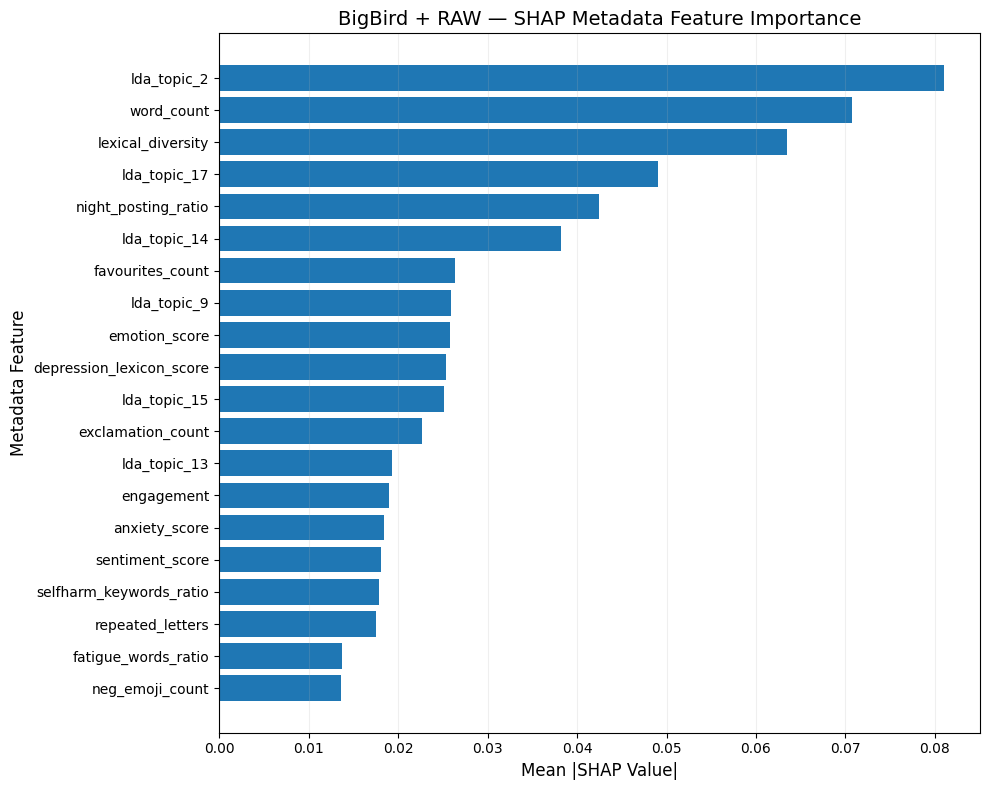

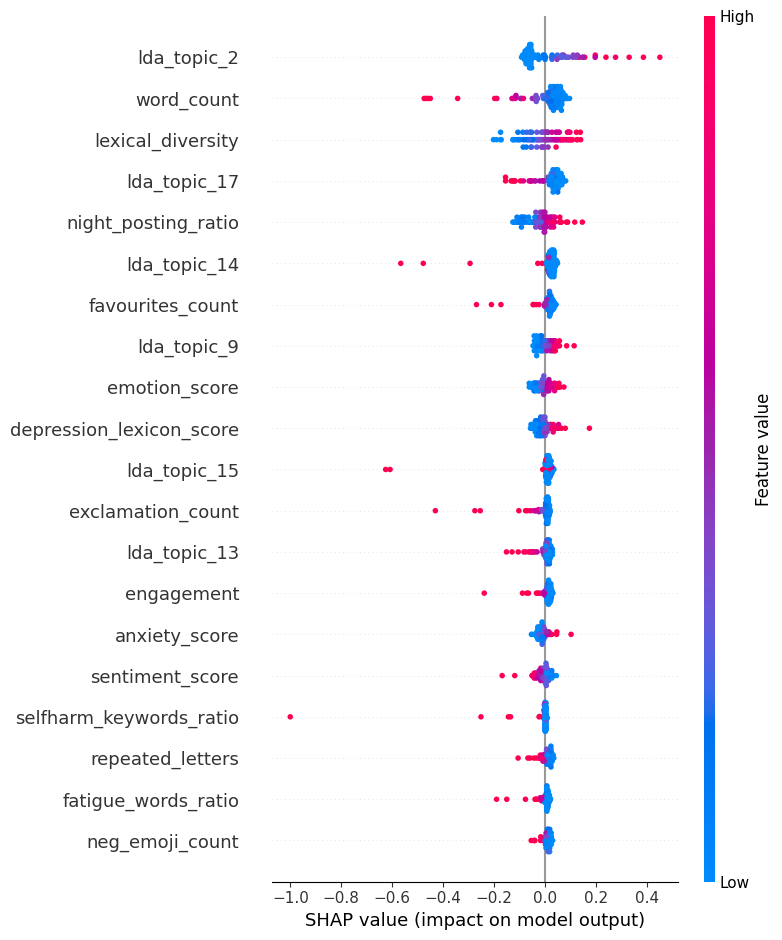


SHAP ANALYSIS COMPLETE
✓ 53 metadata features used
✓ 50 negative + 50 positive test users targeted
✓ Metadata-only SHAP explanations generated
✓ Global feature importance calculated
✓ SHAP summary plot saved
✓ Top feature plot saved
✓ SHAP CSV saved
✓ Configuration saved

SHAP output directory: /kaggle/working/bigbird_raw_results/explainability/shap


In [22]:
# ============================================================
# EXPLAINABILITY — CELL 3
# BIGBIRD + RAW
# SHAP: METADATA-LEVEL GLOBAL EXPLANATION
# ============================================================

import os
import json
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import shap

print("=" * 70)
print("SHAP ANALYSIS")
print("BIGBIRD + RAW")
print("=" * 70)

# ============================================================
# FIXED SHAP SETTINGS
# ============================================================

SHAP_SEED = 42
SHAP_BACKGROUND_SIZE = 50
SHAP_TEST_SIZE_PER_CLASS = 50
SHAP_TOP_FEATURES = 20

np.random.seed(SHAP_SEED)
random.seed(SHAP_SEED)
torch.manual_seed(SHAP_SEED)

# ============================================================
# OUTPUT DIRECTORY
# ============================================================

EXPLAINABILITY_DIR = os.path.join(
    RAW_RESULT_DIR,
    "explainability"
)

SHAP_DIR = os.path.join(
    EXPLAINABILITY_DIR,
    "shap"
)

os.makedirs(
    SHAP_DIR,
    exist_ok=True
)

# ============================================================
# EXACT 53 METADATA FEATURE NAMES
# ============================================================

behavioral_features = [
    "posting_frequency",
    "follower_friend_ratio",
    "night_posting_ratio",
    "engagement",
    "followers_count",
    "friends_count",
    "statuses_count",
    "favourites_count"
]

linguistic_features = [
    "first_person_ratio",
    "negation_ratio",
    "uppercase_ratio",
    "punctuation_freq"
]

readability_features = [
    "flesch_reading_ease",
    "gunning_fog",
    "flesch_kincaid_grade"
]

emotional_features = [
    "sentiment_score",
    "emotion_score",
    "pos_emoji_count",
    "neg_emoji_count",
    "emoji_density",
    "exclamation_count"
]

psychological_features = [
    "depression_lexicon_score",
    "hopelessness_score",
    "loneliness_score",
    "anxiety_score",
    "sleep_words_ratio",
    "fatigue_words_ratio",
    "selfharm_keywords_ratio"
]

writing_style_features = [
    "avg_sentence_length",
    "lexical_diversity",
    "word_count",
    "avg_paragraph_length",
    "repeated_letters"
]

lda_features = [
    f"lda_topic_{i}"
    for i in range(1, 21)
]

raw_metadata_features = (
    behavioral_features
    + linguistic_features
    + readability_features
    + emotional_features
    + psychological_features
    + writing_style_features
    + lda_features
)

assert len(raw_metadata_features) == 53

print(
    f"✓ Metadata features confirmed: "
    f"{len(raw_metadata_features)}"
)

# ============================================================
# MODEL
# ============================================================

model_raw.eval()

print("✓ BigBird + RAW model loaded")
print("✓ Evaluation mode enabled")

# ============================================================
# SHAP WRAPPER
# FIX TEXT INPUT FOR EACH USER
# VARY ONLY METADATA
# ============================================================

class MetadataSHAPWrapper(nn.Module):

    def __init__(
        self,
        model,
        input_ids,
        attention_mask
    ):

        super().__init__()

        self.model = model

        self.register_buffer(
            "input_ids",
            input_ids
        )

        self.register_buffer(
            "attention_mask",
            attention_mask
        )

    def forward(
        self,
        metadata
    ):

        batch_size = metadata.shape[0]

        input_ids = self.input_ids.expand(
            batch_size,
            -1
        )

        attention_mask = self.attention_mask.expand(
            batch_size,
            -1
        )

        output = self.model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            metadata=metadata
        )

        # Positive / depression class logit
        return output["logits"][:, 1:2]


# ============================================================
# BACKGROUND METADATA
# ============================================================

background_metadata = (
    train_dataset_raw.metadata[
        :SHAP_BACKGROUND_SIZE
    ]
    .clone()
    .detach()
    .float()
    .to(device)
)

print()
print("=" * 70)
print("SHAP BACKGROUND")
print("=" * 70)

print(
    "Background samples:",
    background_metadata.shape[0]
)

print(
    "Metadata dimensions:",
    background_metadata.shape[1]
)

# ============================================================
# TEST USERS
# 50 NEGATIVE + 50 POSITIVE
# ============================================================

test_labels = np.asarray(
    test_dataset_raw.labels
)

negative_indices = np.where(
    test_labels == 0
)[0]

positive_indices = np.where(
    test_labels == 1
)[0]

np.random.seed(
    SHAP_SEED
)

negative_indices = np.random.choice(
    negative_indices,
    size=min(
        SHAP_TEST_SIZE_PER_CLASS,
        len(negative_indices)
    ),
    replace=False
)

positive_indices = np.random.choice(
    positive_indices,
    size=min(
        SHAP_TEST_SIZE_PER_CLASS,
        len(positive_indices)
    ),
    replace=False
)

selected_shap_indices = np.concatenate(
    [
        negative_indices,
        positive_indices
    ]
)

print()
print("=" * 70)
print("SHAP TEST USERS")
print("=" * 70)

print(
    "Negative users:",
    len(negative_indices)
)

print(
    "Positive users:",
    len(positive_indices)
)

print(
    "Total users:",
    len(selected_shap_indices)
)

# ============================================================
# COMPUTE SHAP VALUES
# ============================================================

all_shap_rows = []
all_user_importance = []

print()
print("=" * 70)
print("GENERATING SHAP EXPLANATIONS")
print("=" * 70)

for count, test_index in enumerate(
    selected_shap_indices,
    start=1
):

    test_index = int(
        test_index
    )

    sample = test_dataset_raw[
        test_index
    ]

    input_ids = (
        sample["input_ids"]
        .unsqueeze(0)
        .to(device)
    )

    attention_mask = (
        sample["attention_mask"]
        .unsqueeze(0)
        .to(device)
    )

    metadata = (
        sample["metadata"]
        .unsqueeze(0)
        .to(device)
        .float()
    )

    true_label = int(
        sample["labels"].item()
    )

    wrapper = MetadataSHAPWrapper(
        model=model_raw,
        input_ids=input_ids,
        attention_mask=attention_mask
    ).to(device)

    wrapper.eval()

    explainer = shap.GradientExplainer(
        wrapper,
        background_metadata
    )

    shap_values = explainer.shap_values(
        metadata
    )

    # --------------------------------------------------------
    # SHAP VERSION HANDLING
    # --------------------------------------------------------

    if isinstance(
        shap_values,
        list
    ):

        shap_array = np.asarray(
            shap_values[0]
        )

    else:

        shap_array = np.asarray(
            shap_values
        )

    shap_array = np.squeeze(
        shap_array
    )

    # --------------------------------------------------------
    # SAVE USER-LEVEL IMPORTANCE
    # --------------------------------------------------------

    user_importance = pd.DataFrame({

        "feature":
            raw_metadata_features,

        "shap_value":
            shap_array,

        "abs_shap_value":
            np.abs(shap_array)

    })

    user_importance = user_importance.sort_values(
        "abs_shap_value",
        ascending=False
    ).reset_index(
        drop=True
    )

    user_importance["test_index"] = test_index
    user_importance["true_label"] = true_label

    all_user_importance.append(
        user_importance
    )

    for rank, row in enumerate(
        user_importance.itertuples(
            index=False
        ),
        start=1
    ):

        all_shap_rows.append({

            "test_index":
                test_index,

            "true_label":
                true_label,

            "feature":
                row.feature,

            "shap_value":
                float(
                    row.shap_value
                ),

            "abs_shap_value":
                float(
                    row.abs_shap_value
                ),

            "rank":
                rank
        })

    if (
        count == 1
        or count % 10 == 0
        or count == len(selected_shap_indices)
    ):

        print(
            f"Processed "
            f"{count}/"
            f"{len(selected_shap_indices)}"
        )

# ============================================================
# COMBINE SHAP RESULTS
# ============================================================

shap_results_df = pd.DataFrame(
    all_shap_rows
)

shap_csv_path = os.path.join(
    SHAP_DIR,
    "bigbird_raw_shap_values.csv"
)

shap_results_df.to_csv(
    shap_csv_path,
    index=False
)

# ============================================================
# GLOBAL FEATURE IMPORTANCE
# ============================================================

global_importance = (
    shap_results_df
    .groupby("feature")[
        "abs_shap_value"
    ]
    .mean()
    .sort_values(
        ascending=False
    )
    .reset_index()
)

global_importance.columns = [
    "feature",
    "mean_abs_shap_value"
]

global_importance["rank"] = (
    np.arange(
        len(global_importance)
    ) + 1
)

global_importance_csv = os.path.join(
    SHAP_DIR,
    "bigbird_raw_shap_feature_importance.csv"
)

global_importance.to_csv(
    global_importance_csv,
    index=False
)

# ============================================================
# TOP FEATURES
# ============================================================

top_features = global_importance.head(
    SHAP_TOP_FEATURES
).copy()

print()
print("=" * 70)
print("TOP SHAP FEATURES")
print("=" * 70)

print(
    top_features[
        [
            "rank",
            "feature",
            "mean_abs_shap_value"
        ]
    ].to_string(
        index=False
    )
)

# ============================================================
# PAPER-READY GLOBAL BAR PLOT
# ============================================================

plot_df = top_features.iloc[::-1]

plt.figure(
    figsize=(10, 8)
)

plt.barh(
    plot_df["feature"],
    plot_df["mean_abs_shap_value"]
)

plt.xlabel(
    "Mean |SHAP Value|",
    fontsize=12
)

plt.ylabel(
    "Metadata Feature",
    fontsize=12
)

plt.title(
    "BigBird + RAW — SHAP Metadata Feature Importance",
    fontsize=14
)

plt.grid(
    axis="x",
    alpha=0.20
)

plt.tight_layout()

global_plot_path = os.path.join(
    SHAP_DIR,
    "bigbird_raw_shap_global_feature_importance.png"
)

plt.savefig(
    global_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ============================================================
# SHAP SUMMARY / BEESWARM
# ============================================================

# Reconstruct matrix:
# users × features

shap_matrix = np.zeros(
    (
        len(selected_shap_indices),
        len(raw_metadata_features)
    ),
    dtype=np.float32
)

for row_index, test_index in enumerate(
    selected_shap_indices
):

    user_rows = shap_results_df[
        shap_results_df["test_index"]
        == int(test_index)
    ]

    feature_map = dict(
        zip(
            user_rows["feature"],
            user_rows["shap_value"]
        )
    )

    for feature_index, feature in enumerate(
        raw_metadata_features
    ):

        shap_matrix[
            row_index,
            feature_index
        ] = feature_map.get(
            feature,
            0.0
        )

metadata_matrix = np.asarray(
    [
        test_dataset_raw.metadata[
            int(test_index)
        ].cpu().numpy()
        for test_index in selected_shap_indices
    ],
    dtype=np.float32
)

plt.figure(
    figsize=(10, 8)
)

shap.summary_plot(
    shap_matrix,
    metadata_matrix,
    feature_names=raw_metadata_features,
    max_display=SHAP_TOP_FEATURES,
    show=False
)

plt.tight_layout()

summary_plot_path = os.path.join(
    SHAP_DIR,
    "bigbird_raw_shap_summary.png"
)

plt.savefig(
    summary_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ============================================================
# SAVE USER INFORMATION
# ============================================================

user_information = []

for test_index in selected_shap_indices:

    test_index = int(
        test_index
    )

    user_information.append({

        "test_index":
            test_index,

        "true_label":
            int(
                test_dataset_raw.labels[
                    test_index
                ].item()
            )
    })

user_information_df = pd.DataFrame(
    user_information
)

user_information_path = os.path.join(
    SHAP_DIR,
    "bigbird_raw_shap_user_information.csv"
)

user_information_df.to_csv(
    user_information_path,
    index=False
)

# ============================================================
# SAVE CONFIGURATION
# ============================================================

shap_config = {

    "model":
        "BigBird",

    "cleaning":
        "RAW / MINIMAL CLEANING",

    "dataset":
        "Held-out test set",

    "method":
        "SHAP GradientExplainer",

    "explanation_target":
        "Positive/depression class logit",

    "explanation_type":
        "Metadata-level explanation",

    "metadata_features":
        53,

    "background_size":
        SHAP_BACKGROUND_SIZE,

    "test_size_per_class":
        SHAP_TEST_SIZE_PER_CLASS,

    "total_test_users":
        int(
            len(selected_shap_indices)
        ),

    "top_features_displayed":
        SHAP_TOP_FEATURES,

    "random_seed":
        SHAP_SEED,

    "model_training":
        "No additional training",

    "transformer_weights":
        "Frozen"
}

config_path = os.path.join(
    SHAP_DIR,
    "bigbird_raw_shap_config.json"
)

with open(
    config_path,
    "w"
) as f:

    json.dump(
        shap_config,
        f,
        indent=2
    )

# ============================================================
# COMPLETE
# ============================================================

print()
print("=" * 70)
print("SHAP ANALYSIS COMPLETE")
print("=" * 70)

print(
    "✓ 53 metadata features used"
)

print(
    "✓ 50 negative + 50 positive test users targeted"
)

print(
    "✓ Metadata-only SHAP explanations generated"
)

print(
    "✓ Global feature importance calculated"
)

print(
    "✓ SHAP summary plot saved"
)

print(
    "✓ Top feature plot saved"
)

print(
    "✓ SHAP CSV saved"
)

print(
    "✓ Configuration saved"
)

print()
print(
    "SHAP output directory:",
    SHAP_DIR
)

LIME EXPLAINABILITY
BIGBIRD + RAW
✓ BigBird + RAW model loaded
✓ Evaluation mode enabled

TEST PREDICTIONS READY
Test samples: 767

SELECTED CASES
TP : test index 1 | true=1 | pred=1 | probability=0.8327
TN : test index 0 | true=0 | pred=0 | probability=0.3739
FP : test index 8 | true=0 | pred=1 | probability=0.6044
FN : test index 94 | true=1 | pred=0 | probability=0.4126

GENERATING LIME EXPLANATIONS

Processing TP (test index 1)...
✓ TP explanation complete

Processing TN (test index 0)...
✓ TN explanation complete

Processing FP (test index 8)...
✓ FP explanation complete

Processing FN (test index 94)...
✓ FN explanation complete

LIME EXPLANATIONS

TP — LIME LOCAL EXPLANATION



TN — LIME LOCAL EXPLANATION



FP — LIME LOCAL EXPLANATION



FN — LIME LOCAL EXPLANATION


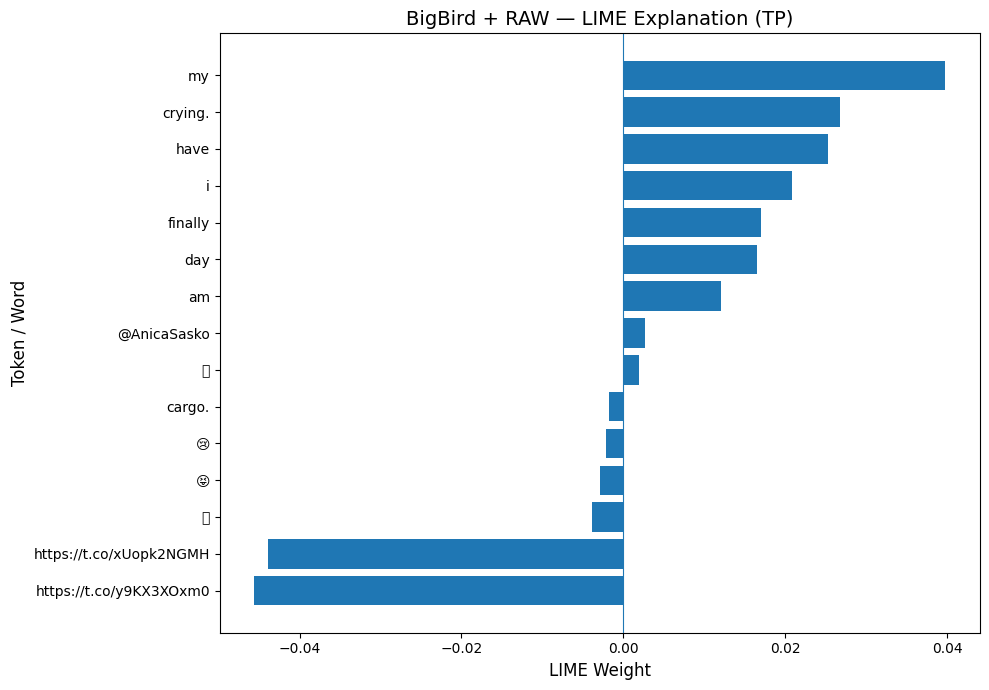

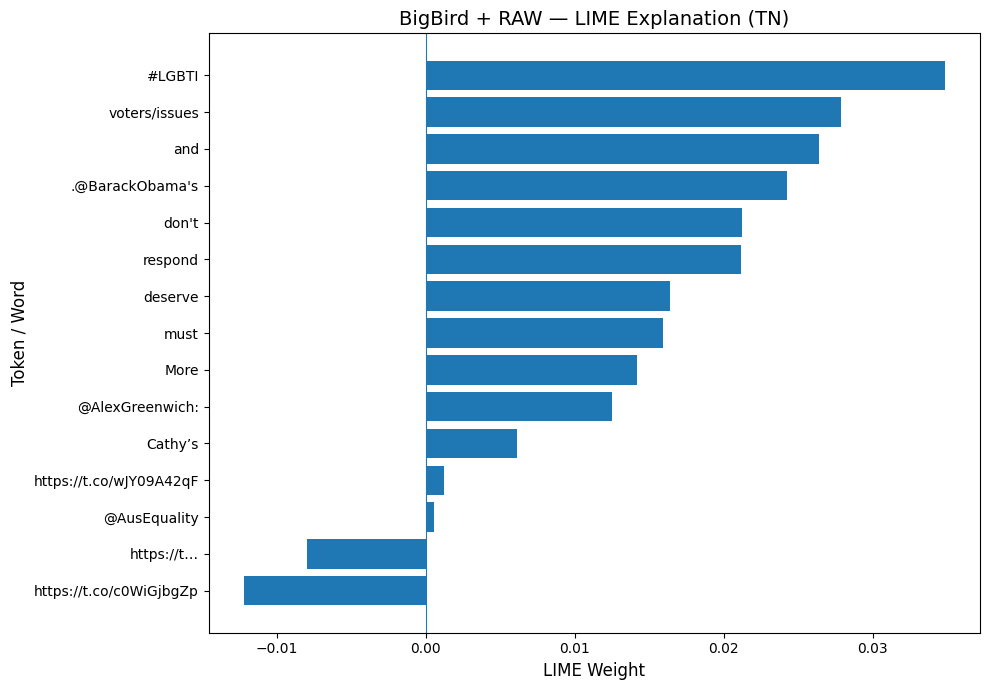

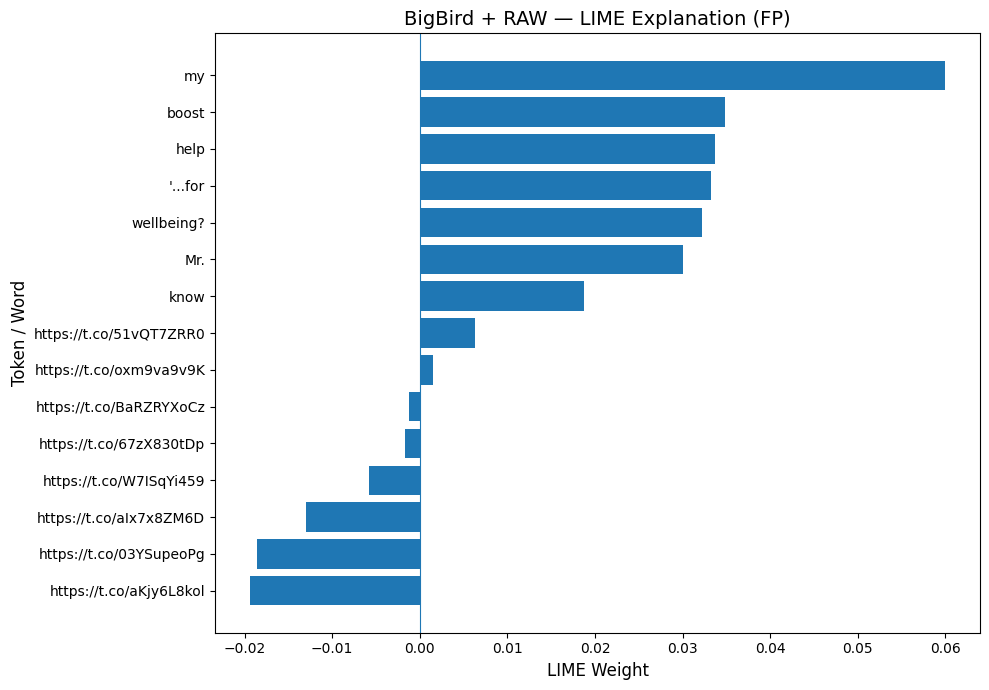

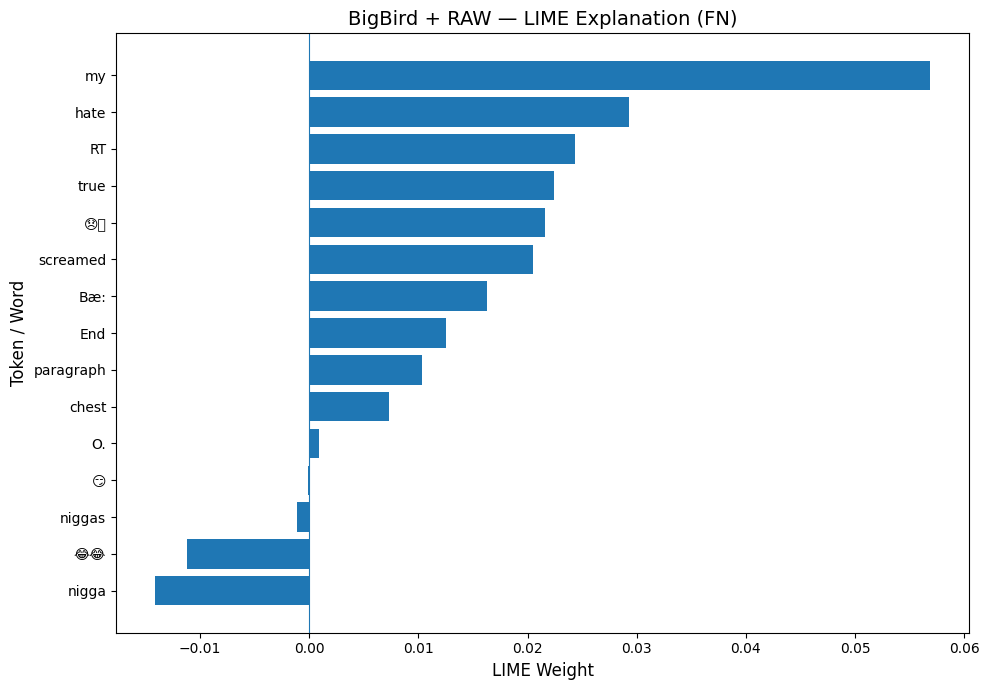


LIME ANALYSIS COMPLETE
✓ TP, TN, FP, FN cases explained
✓ Same trained BigBird + RAW model used
✓ Metadata held fixed per user
✓ 1000 LIME perturbations per case
✓ Top 15 features extracted
✓ LIME results saved
✓ HTML explanations saved
✓ Paper-ready LIME plots saved and displayed

LIME output directory: /kaggle/working/bigbird_raw_results/explainability/lime


In [27]:
# ============================================================
# EXPLAINABILITY — LIME
# BIGBIRD + RAW
# TOKEN / WORD-LEVEL LOCAL EXPLANATION
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from lime.lime_text import LimeTextExplainer
from IPython.display import display, HTML

print("=" * 70)
print("LIME EXPLAINABILITY")
print("BIGBIRD + RAW")
print("=" * 70)

# ============================================================
# FIXED LIME SETTINGS
# ============================================================

LIME_SEED = 42
LIME_NUM_SAMPLES = 1000
LIME_NUM_FEATURES = 15
LIME_BATCH_SIZE = 8

np.random.seed(LIME_SEED)
torch.manual_seed(LIME_SEED)

# ============================================================
# OUTPUT DIRECTORY
# ============================================================

EXPLAINABILITY_DIR = os.path.join(
    RAW_RESULT_DIR,
    "explainability"
)

LIME_DIR = os.path.join(
    EXPLAINABILITY_DIR,
    "lime"
)

os.makedirs(
    LIME_DIR,
    exist_ok=True
)

# ============================================================
# MODEL
# ============================================================

model_raw.eval()

print("✓ BigBird + RAW model loaded")
print("✓ Evaluation mode enabled")

# ============================================================
# TEST PREDICTIONS
# ============================================================

labels_np = []
preds_np = []
probs_np = []

with torch.no_grad():

    for batch in test_loader_raw:

        input_ids = batch[
            "input_ids"
        ].to(device)

        attention_mask = batch[
            "attention_mask"
        ].to(device)

        metadata = batch[
            "metadata"
        ].to(device)

        output = model_raw(
            input_ids=input_ids,
            attention_mask=attention_mask,
            metadata=metadata
        )

        logits = output["logits"]

        probabilities = torch.softmax(
            logits,
            dim=1
        )

        predictions = torch.argmax(
            logits,
            dim=1
        )

        labels_np.extend(
            batch["labels"]
            .cpu()
            .numpy()
            .tolist()
        )

        preds_np.extend(
            predictions
            .cpu()
            .numpy()
            .tolist()
        )

        probs_np.extend(
            probabilities[:, 1]
            .cpu()
            .numpy()
            .tolist()
        )

labels_np = np.array(
    labels_np
)

preds_np = np.array(
    preds_np
)

probs_np = np.array(
    probs_np
)

print()
print("=" * 70)
print("TEST PREDICTIONS READY")
print("=" * 70)

print(
    "Test samples:",
    len(labels_np)
)

# ============================================================
# SELECT TP / TN / FP / FN
# ============================================================

selected_cases = {}

tp_candidates = np.where(
    (labels_np == 1)
    &
    (preds_np == 1)
)[0]

tn_candidates = np.where(
    (labels_np == 0)
    &
    (preds_np == 0)
)[0]

fp_candidates = np.where(
    (labels_np == 0)
    &
    (preds_np == 1)
)[0]

fn_candidates = np.where(
    (labels_np == 1)
    &
    (preds_np == 0)
)[0]

if len(tp_candidates) > 0:
    selected_cases["TP"] = int(
        tp_candidates[0]
    )

if len(tn_candidates) > 0:
    selected_cases["TN"] = int(
        tn_candidates[0]
    )

if len(fp_candidates) > 0:
    selected_cases["FP"] = int(
        fp_candidates[0]
    )

if len(fn_candidates) > 0:
    selected_cases["FN"] = int(
        fn_candidates[0]
    )

print()
print("=" * 70)
print("SELECTED CASES")
print("=" * 70)

for case_name, test_index in selected_cases.items():

    print(
        f"{case_name} : "
        f"test index {test_index} | "
        f"true={labels_np[test_index]} | "
        f"pred={preds_np[test_index]} | "
        f"probability={probs_np[test_index]:.4f}"
    )

# ============================================================
# GET TEST TEXT
# ============================================================

def get_test_text(test_index):

    return str(
        test_raw_df.iloc[
            test_index
        ]["model_text"]
    )


# ============================================================
# CREATE LIME PREDICTOR
# TEXT VARIES
# METADATA REMAINS FIXED
# ============================================================

def make_lime_predictor(test_index):

    sample = test_dataset_raw[
        test_index
    ]

    fixed_metadata = (
        sample["metadata"]
        .unsqueeze(0)
        .to(device)
        .float()
    )

    def predictor(texts):

        all_probabilities = []

        # ----------------------------------------------------
        # PROCESS LIME PERTURBATIONS IN SMALL BATCHES
        # TO AVOID GPU OUT-OF-MEMORY
        # ----------------------------------------------------

        for start in range(
            0,
            len(texts),
            LIME_BATCH_SIZE
        ):

            batch_texts = texts[
                start:
                start + LIME_BATCH_SIZE
            ]

            encoded = tokenizer_raw(
                batch_texts,
                padding="max_length",
                truncation=True,
                max_length=MAX_LENGTH_RAW,
                return_attention_mask=True,
                return_tensors="pt"
            )

            lime_input_ids = (
                encoded["input_ids"]
                .to(device)
            )

            lime_attention_mask = (
                encoded["attention_mask"]
                .to(device)
            )

            batch_metadata = (
                fixed_metadata.expand(
                    len(batch_texts),
                    -1
                )
            )

            with torch.no_grad():

                output = model_raw(
                    input_ids=lime_input_ids,
                    attention_mask=lime_attention_mask,
                    metadata=batch_metadata
                )

                probabilities = torch.softmax(
                    output["logits"],
                    dim=1
                )

            all_probabilities.append(
                probabilities
                .cpu()
                .numpy()
            )

            del (
                lime_input_ids,
                lime_attention_mask,
                batch_metadata,
                output,
                probabilities
            )

            if torch.cuda.is_available():
                torch.cuda.empty_cache()

        return np.vstack(
            all_probabilities
        )

    return predictor


# ============================================================
# LIME EXPLAINER
# ============================================================

explainer = LimeTextExplainer(
    class_names=[
        "Negative",
        "Positive"
    ],
    split_expression=r"\s+",
    random_state=LIME_SEED
)

# ============================================================
# RUN LIME FOR FOUR CASES
# ============================================================

all_explanations = {}

print()
print("=" * 70)
print("GENERATING LIME EXPLANATIONS")
print("=" * 70)

for case_name, test_index in selected_cases.items():

    print()
    print(
        f"Processing {case_name} "
        f"(test index {test_index})..."
    )

    text = get_test_text(
        test_index
    )

    predictor = make_lime_predictor(
        test_index
    )

    explanation = explainer.explain_instance(
        text,
        predictor,
        labels=(1,),
        num_features=LIME_NUM_FEATURES,
        num_samples=LIME_NUM_SAMPLES
    )

    all_explanations[
        case_name
    ] = explanation

    print(
        f"✓ {case_name} explanation complete"
    )

# ============================================================
# SAVE LIME RESULTS
# ============================================================

all_lime_rows = []

for case_name, explanation in all_explanations.items():

    explanation_list = (
        explanation.as_list(
            label=1
        )
    )

    for rank, (
        word,
        weight
    ) in enumerate(
        explanation_list,
        start=1
    ):

        all_lime_rows.append({

            "case":
                case_name,

            "test_index":
                selected_cases[
                    case_name
                ],

            "true_label":
                int(
                    labels_np[
                        selected_cases[
                            case_name
                        ]
                    ]
                ),

            "predicted_label":
                int(
                    preds_np[
                        selected_cases[
                            case_name
                        ]
                    ]
                ),

            "positive_probability":
                float(
                    probs_np[
                        selected_cases[
                            case_name
                        ]
                    ]
                ),

            "rank":
                rank,

            "word":
                word,

            "lime_weight":
                float(weight)

        })

lime_results_df = pd.DataFrame(
    all_lime_rows
)

lime_csv_path = os.path.join(
    LIME_DIR,
    "bigbird_raw_lime_results.csv"
)

lime_results_df.to_csv(
    lime_csv_path,
    index=False
)

# ============================================================
# DISPLAY + SAVE HTML
# ============================================================

print()
print("=" * 70)
print("LIME EXPLANATIONS")
print("=" * 70)

for case_name, explanation in all_explanations.items():

    print()
    print(
        "=" * 60
    )

    print(
        f"{case_name} — "
        f"LIME LOCAL EXPLANATION"
    )

    print(
        "=" * 60
    )

    display(
        HTML(
            explanation.as_html(
                labels=[1]
            )
        )
    )

    html_path = os.path.join(
        LIME_DIR,
        f"bigbird_raw_lime_{case_name}.html"
    )

    with open(
        html_path,
        "w",
        encoding="utf-8"
    ) as f:

        f.write(
            explanation.as_html(
                labels=[1]
            )
        )

# ============================================================
# PAPER-FRIENDLY LIME BAR PLOTS
# ============================================================

for case_name, explanation in all_explanations.items():

    explanation_list = (
        explanation.as_list(
            label=1
        )
    )

    plot_df = pd.DataFrame(
        explanation_list,
        columns=[
            "word",
            "weight"
        ]
    )

    plot_df = plot_df.sort_values(
        "weight"
    )

    plt.figure(
        figsize=(10, 7)
    )

    plt.barh(
        plot_df["word"],
        plot_df["weight"]
    )

    plt.axvline(
        0,
        linewidth=0.8
    )

    plt.xlabel(
        "LIME Weight",
        fontsize=12
    )

    plt.ylabel(
        "Token / Word",
        fontsize=12
    )

    plt.title(
        f"BigBird + RAW — "
        f"LIME Explanation ({case_name})",
        fontsize=14
    )

    plt.tight_layout()

    plot_path = os.path.join(
        LIME_DIR,
        f"bigbird_raw_lime_{case_name}.png"
    )

    plt.savefig(
        plot_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    plt.close()

# ============================================================
# SAVE CASE INFORMATION
# ============================================================

case_info_rows = []

for case_name, test_index in selected_cases.items():

    case_info_rows.append({

        "case":
            case_name,

        "test_index":
            int(test_index),

        "true_label":
            int(
                labels_np[
                    test_index
                ]
            ),

        "predicted_label":
            int(
                preds_np[
                    test_index
                ]
            ),

        "positive_probability":
            float(
                probs_np[
                    test_index
                ]
            ),

        "text_length_characters":
            len(
                get_test_text(
                    test_index
                )
            )

    })

case_info_df = pd.DataFrame(
    case_info_rows
)

case_info_df.to_csv(
    os.path.join(
        LIME_DIR,
        "bigbird_raw_lime_case_information.csv"
    ),
    index=False
)

# ============================================================
# SAVE CONFIGURATION
# ============================================================

lime_config = {

    "model":
        "BigBird",

    "cleaning":
        "RAW",

    "dataset":
        "Held-out test set",

    "target":
        "Positive/depression class",

    "representative_cases":
        [
            "TP",
            "TN",
            "FP",
            "FN"
        ],

    "case_selection":
        "First matching test example in fixed test order",

    "random_seed":
        LIME_SEED,

    "num_samples":
        LIME_NUM_SAMPLES,

    "num_features":
        LIME_NUM_FEATURES,

    "batch_size":
        LIME_BATCH_SIZE,

    "metadata":
        "Fixed for each explained user",

    "text_perturbation":
        "LIME word-level perturbations",

    "model_training":
        "No additional training",

    "transformer_weights":
        "Frozen"
}

with open(
    os.path.join(
        LIME_DIR,
        "bigbird_raw_lime_config.json"
    ),
    "w"
) as f:

    json.dump(
        lime_config,
        f,
        indent=2
    )

# ============================================================
# COMPLETE
# ============================================================

print()
print("=" * 70)
print("LIME ANALYSIS COMPLETE")
print("=" * 70)

print(
    "✓ TP, TN, FP, FN cases explained"
)

print(
    "✓ Same trained BigBird + RAW model used"
)

print(
    "✓ Metadata held fixed per user"
)

print(
    f"✓ {LIME_NUM_SAMPLES} LIME perturbations per case"
)

print(
    f"✓ Top {LIME_NUM_FEATURES} features extracted"
)

print(
    "✓ LIME results saved"
)

print(
    "✓ HTML explanations saved"
)

print(
    "✓ Paper-ready LIME plots saved and displayed"
)

print()
print(
    "LIME output directory:",
    LIME_DIR
)